# Construction Cost Escalation Index

**A lag-based regression model using public Statistics Canada data, with out-of-sample validation**

**Author:** Emely Lephilibert  
**Data:** Statistics Canada, tables 18-10-0001-01, 18-10-0266-01 and 18-10-0004-01, snapshot of 2026-11-17  
**Language:** Python




## **Executive summary**

| Finding | Evidence |
|---------|----------|
| Fuel and construction material prices lead consumer inflation | Strongest correlation with the Montréal CPI at a 1-month lag for fuel (0.634) and an 8-month lag for materials (0.765) |
| A two-input index tracks the CPI with a simple, transparent formula | Construction Market Index (CMI): 15.1% fuel, 84.9% materials, R² 0.6247 |
| The model holds on data it has not seen | April to October 2026: RMSE 0.218 against 0.443 for a naive benchmark, 7 of 7 months inside the 95% interval |
| The index triggers adjustments only in extraordinary periods | 17 months above the review band, all in the post-COVID surge (Nov 2021 to Mar 2023); no trigger in the 2020 shock |
| 2026 shows rising pressure, close to the contract limit | No trigger in the rolling review; a contract with a February 2026 base date reaches +10.16% by November, just over the +10% first-year limit |
| A project layer adapts the index to a project's cost structure | M16 combines fixed, fuel, materials and CMI components with project-specific weights; it records the same number of historical triggers as the CMI, starting one month earlier |

For a cost control team: public Statistics Canada data are enough to build an escalation index that anticipates inflation, can be audited line by line and can be adapted to the cost breakdown of each project.

## **Business context**

Multi-year construction projects are priced at one point in time, while fuel and material costs keep moving during execution. Escalation above the level assumed in the bid erodes the margin; escalation below it leaves the project overpriced. Tracking escalation against the price base is a core cost control task.

Statistics Canada publishes monthly prices for fuel and for fabricated metal and construction materials. This notebook builds an escalation index from these public series, assesses whether they signal escalation before it appears in general inflation, and adapts the index to the cost structure of a project.

## **Intended use**

The index is designed for cost control and estimating teams on multi-year construction projects. It supports four decisions:

- **Bid pricing:** the escalation allowance to carry in the estimate.
- **Contract monitoring:** when and how much input costs have moved since the price base.
- **Contract adjustments:** whether escalation has moved outside an agreed review band, and the amount to adjust.
- **Early warning:** which cost drivers to watch, and at which lag their association with consumer prices is strongest.

The market index (CMI) is the same for every project; the project index (M16) applies the cost breakdown of a specific contract. Both use only public data, so any party can rebuild them and verify every figure at each review date.

## **Project Constants and Analysis Framework**

The following constants are fixed before any data is loaded and apply to every calculation in the notebook. The contract values describe a hypothetical multi-year construction contract, used to translate index movements into dollars.

| Constant | Value | Rationale |
|----------|-------|-----------|
| Base period | January 2018 | Neutral pre-COVID baseline: oil prices had recovered from the 2015 crash, markets were stable and there was no pandemic distortion |
| Contract value | \$100,000,000 CAD | Reference value for the dollar impact |
| Standard anticipated inflation | 2.0% per year | Inflation level assumed foreseeable when the contract is priced |
| Trigger threshold | ±10 percentage points around the standard anticipated inflation rate | Tolerance around the standard inflation before a price adjustment applies |
| Review band | +12% / -8% year over year | Standard inflation plus or minus the trigger threshold; only the change outside the band is adjusted |

## **Time Period Classification**

The 195-month analysis period (January 2010 to March 2026) is divided into four economic regimes. In each one, input costs and consumer inflation relate differently, so results are reported by regime as well as for the full period.

| Regime | Period | Economic characteristics |
|--------|--------|--------------------------|
| Pre-COVID | Jan 2010 to Feb 2020 | Normal market cycle, including the 2015 oil crash and the recovery that followed. Baseline reference. |
| COVID Shock | Mar 2020 to Dec 2020 | Sharp drop in demand. Fuel prices collapsed while the CPI stayed stable, so input costs and consumer prices moved apart. |
| Post-COVID surge | Jan 2021 to Dec 2023 | The strongest inflationary episode in the data. All series rose at the same time. The most relevant scenario for multi-year contract risk. |
| Stabilization | Jan 2024 to Mar 2026 | Gradual retreat from the peaks. Input costs partly corrected and CPI growth slowed. |

The classification is applied to every later analysis (trends, lead times, regression models and index evaluation), so the index can be compared across different market conditions.

## **The data**

| Series | Statistics Canada table | Geography | Unit | Role |
|--------|-------------------------|-----------|------|------|
| Diesel fuel, retail price | 18-10-0001-01 | Montréal | Cents per litre | Cost input |
| Regular unleaded gasoline, retail price | 18-10-0001-01 | Montréal | Cents per litre | Cost input |
| IPPI, Fabricated metal products and construction materials [P63] | 18-10-0266-01 | Canada | Index, 2020 = 100 | Cost input |
| CPI, All-items | 18-10-0004-01 | Montréal and Canada | Index, 2002 = 100 | Benchmark |

- **Analysis period:** January 2010 to March 2026, monthly (195 months). All trends, lead times, weights and in-sample results use data from this period only. The 12-month comparison means year-over-year changes start in January 2011, while the 8-month materials lag means model estimation starts in September 2011.
- **Out-of-sample test:** April to October 2026 (September for the IPPI), used only in Chapters 5 and 6 to test the frozen index.
- **What a row is:** one month, with one value for each series. The master dataset covers January 2010 to October 2026 (202 months), including the out-of-sample months.
- **Snapshot:** 2026-11-17, saved in the project repository. Section 7.4 lists every period used in the analysis.

## **Chapters**

| Chapter | Objective | Output |
|---------|-----------|--------|
| 0. Data audit and preparation | Load the Statistics Canada tables, check their integrity and build a normalized monthly dataset | A clean master dataset with January 2018 = 100, saved as a dated snapshot |
| 1. Trends and regimes | Describe how fuel, materials and the CPI moved across four economic regimes | Year-over-year and monthly volatility profiles by regime |
| 2. Association and lead time | Measure how closely each input follows the CPI and at which lag the association is strongest | Correlations by regime and the optimal lag of each input (the CFI at 1 month, materials at 8 months) |
| 3. Index modeling | Turn the leading inputs into candidate index formulas | Three candidates (M12, M14, M15) with their weights and fit |
| 4. In-sample evaluation | Test the candidates against the CPI and in a contract simulation | Tracking performance, trigger history, dollar impact and a COVID stress test |
| 5. Out-of-sample backtest | Check the model on months it was not fitted on and follow the indexes through 2026 | Forecast accuracy, the 2026 trigger tests and a forecast of the November 2026 CPI |
| 6. From market index to project index | Choose the Construction Market Index and adapt it to a project's cost structure | The CMI and the project index M16, tested in the history and in 2026 |
| 7. Conclusions and recommendations | Summarize the results and set out how to use them | Conclusions, recommendations, limitations and reproducibility notes |

## **Pills for this project**

**Board pills:** Trend analysis · Regression analysis · Cost control

**Method pills:** `normalization` · `cross-correlation` · `rolling-correlation` · `ols-regression` · `constrained-regression` · `vif` · `cooks-distance` · `out-of-sample-validation` · `prediction-intervals` · `trigger-simulation`


## **How to read this notebook**

Each chapter opens with a short paragraph on what it does. Most sections follow the same pattern: a short introduction, the code, then a reading of the result. Tables come before charts. Every chapter closes with **Implications for cost control**, which translates the result into decisions for a cost control team. Readers short on time can read the executive summary, the closing of each chapter and Chapter 7.

## **Setup**

Libraries, analysis periods and folder paths used throughout the notebook. In Colab, the notebook reads the data from Google Drive; anywhere else, it reads it from the `data/` folder of the repository. The analysis period ends in March 2026; months published later are loaded only for the out-of-sample tests in Chapters 5 and 6.

In [1]:
# Libraries, data folders (Google Drive in Colab, the repository elsewhere), analysis periods and chart style
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

# In Colab the raw Statistics Canada files live in Google Drive (Colab cannot download them directly);
# anywhere else the notebook uses the data/ folder next to it, as in the GitHub repository
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/construction-cost-escalation-index")
except ImportError:
    PROJECT_DIR = Path.cwd()
RAW_DIR = PROJECT_DIR / "data/raw"
PROCESSED_DIR = PROJECT_DIR / "data/processed"
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Analysis periods
ANALYSIS_START = "2010-01-01"
ANALYSIS_END = "2026-03-01"   # last month used to build the index
BASE_DATE = "2018-01-01"      # common base period for normalization (January 2018 = 100)
SNAPSHOT_DATE = "2026-11-17"  # date of the data download, fixed so the snapshot never changes

# One chart style for the whole notebook (same as the previous portfolio projects)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

# Chart palette (cost control: green accent)
COLORS = {"blue": "#2F5D8A", "green": "#3B8C5A", "grey": "#7A7A7A",
          "light_blue": "#9DB7D1", "navy": "#1F3B5C"}

print(f"Data folder    : {PROJECT_DIR}")
print(f"Snapshot date  : {SNAPSHOT_DATE}")
print(f"Analysis period: {ANALYSIS_START[:7]} to {ANALYSIS_END[:7]}")
print(f"Base period    : {BASE_DATE[:7]} = 100")
print(f"Raw files found: {sorted(p.name for p in RAW_DIR.glob('*.zip'))}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data folder    : /content/drive/MyDrive/construction-cost-escalation-index
Snapshot date  : 2026-11-17
Analysis period: 2010-01 to 2026-03
Base period    : 2018-01 = 100
Raw files found: ['18100001-eng.zip', '18100004-eng.zip', '18100266-eng.zip']


The snapshot is dated 2026-11-17. The analysis covers January 2010 to March 2026, and every series is normalized to January 2018 = 100. The three Statistics Canada tables are stored as zip files in the project folder on Google Drive, because Statistics Canada blocks direct downloads from Colab.

# **Chapter 0: Data audit and preparation**

This chapter turns three public Statistics Canada tables into one clean monthly dataset. The series used in the analysis are extracted on their exact labels, audited for completeness and normalized to January 2018 = 100. The result is saved as a dated snapshot, so every later figure can be reproduced even after Statistics Canada revises its data.

### **0.1 Raw tables**

The three tables are the full CSV packages published by Statistics Canada, downloaded from its website on the snapshot date and stored in the project folder. The full tables include every geography and product; the series used here are identified in section 0.2 and extracted in section 0.3.

In [2]:
# Read the three full Statistics Canada tables from the zip files and show their size and columns
TABLES = {
    "fuel": "18100001",   # Monthly average retail prices for gasoline and fuel oil
    "ippi": "18100266",   # Industrial product price index, by product, monthly
    "cpi":  "18100004",   # Consumer Price Index, monthly, not seasonally adjusted
}

def read_statcan_table(pid):
    # Read the CSV inside the zip package downloaded from Statistics Canada
    with zipfile.ZipFile(RAW_DIR / f"{pid}-eng.zip") as z:
        with z.open(f"{pid}.csv") as f:
            return pd.read_csv(f, low_memory=False)

raw = {}
for name, pid in TABLES.items():
    raw[name] = read_statcan_table(pid)
    print(f"{name} ({pid}): {raw[name].shape[0]:,} rows, {raw[name].shape[1]} columns")
    print(f"  {list(raw[name].columns)}\n")

fuel (18100001): 46,332 rows, 15 columns
  ['REF_DATE', 'GEO', 'DGUID', 'Type of fuel', 'UOM', 'UOM_ID', 'SCALAR_FACTOR', 'SCALAR_ID', 'VECTOR', 'COORDINATE', 'VALUE', 'STATUS', 'SYMBOL', 'TERMINATED', 'DECIMALS']

ippi (18100266): 125,776 rows, 15 columns
  ['REF_DATE', 'GEO', 'DGUID', 'North American Product Classification System (NAPCS)', 'UOM', 'UOM_ID', 'SCALAR_FACTOR', 'SCALAR_ID', 'VECTOR', 'COORDINATE', 'VALUE', 'STATUS', 'SYMBOL', 'TERMINATED', 'DECIMALS']

cpi (18100004): 1,156,923 rows, 15 columns
  ['REF_DATE', 'GEO', 'DGUID', 'Products and product groups', 'UOM', 'UOM_ID', 'SCALAR_FACTOR', 'SCALAR_ID', 'VECTOR', 'COORDINATE', 'VALUE', 'STATUS', 'SYMBOL', 'TERMINATED', 'DECIMALS']



The three tables share the standard Statistics Canada layout of 15 columns: the reference month (`REF_DATE`), the geography (`GEO`), one classification column, the value (`VALUE`) and metadata such as the unit, the series identifier (`VECTOR`) and the status flag. The classification column is `Type of fuel` in the fuel table (46,332 rows), the NAPCS product code in the IPPI table (125,776 rows) and `Products and product groups` in the CPI table (1,156,923 rows).

### **0.2 Series labels**

Before extracting the series, the exact labels are checked in each table: the fuel types published for Montréal, the IPPI product label that contains the code P63, and the CPI geographies available for All-items. Matching on exact labels avoids capturing a neighbouring geography or product by mistake.

In [3]:
# List the candidate labels for each series before extracting them
fuel_mtl = raw["fuel"][raw["fuel"]["GEO"].str.contains("Montr", na=False)]
print("Fuel, geographies matching 'Montr':", fuel_mtl["GEO"].unique().tolist())
print("Fuel types for Montréal:")
for t in fuel_mtl["Type of fuel"].unique():
    n = (fuel_mtl["Type of fuel"] == t).sum()
    print(f"  {t} ({n} months)")

napcs = "North American Product Classification System (NAPCS)"
p63 = raw["ippi"][raw["ippi"][napcs].str.contains(r"\[P63\]", na=False)]
print("\nIPPI labels containing [P63]:", p63[napcs].unique().tolist())
print("IPPI geographies for P63:", p63["GEO"].unique().tolist())

cpi_all = raw["cpi"][raw["cpi"]["Products and product groups"] == "All-items"]
print("\nCPI All-items geographies containing 'Montr', 'Quebec' or 'Canada':")
print([g for g in cpi_all["GEO"].unique() if any(k in g for k in ("Montr", "Quebec", "Canada"))])

Fuel, geographies matching 'Montr': ['Montréal, Quebec']
Fuel types for Montréal:
  Regular unleaded gasoline at full service filling stations (409 months)
  Regular unleaded gasoline at self service filling stations (442 months)
  Premium unleaded gasoline at full service filling stations (277 months)
  Premium unleaded gasoline at self service filling stations (442 months)
  Diesel fuel at full service filling stations (277 months)
  Diesel fuel at self service filling stations (442 months)
  Household heating fuel (442 months)

IPPI labels containing [P63]: ['Fabricated metal products and construction materials [P63]']
IPPI geographies for P63: ['Canada']

CPI All-items geographies containing 'Montr', 'Quebec' or 'Canada':
['Canada', 'Québec, Quebec', 'Montréal, Quebec', 'Ottawa-Gatineau, Ontario part, Ontario/Quebec', 'Quebec']


Montréal publishes each fuel at full service and at self service stations. The self service series of regular unleaded gasoline and diesel are complete over the 442 months in the table, while the full service series are shorter (409 and 277 months) and do not cover the full analysis period. The analysis uses the self service prices. The IPPI table has a single P63 label, published for Canada, and the CPI geographies are matched on the exact labels `Montréal, Quebec` and `Canada`, which excludes `Québec, Quebec`, the province and the Ottawa-Gatineau area.

### **0.3 Series extraction**

Each series is extracted on its exact labels and checked for coverage: first and last month available, number of months, duplicated months, missing values, unit of measure and status flags. The status flag marks values that Statistics Canada considers preliminary or of lower quality.

In [4]:
# Extract the five series on their exact labels and check their coverage and quality
napcs = "North American Product Classification System (NAPCS)"
SERIES = {
    "diesel":       ("fuel", "GEO", "Montréal, Quebec", "Type of fuel", "Diesel fuel at self service filling stations"),
    "gasoline":     ("fuel", "GEO", "Montréal, Quebec", "Type of fuel", "Regular unleaded gasoline at self service filling stations"),
    "ippi_p63":     ("ippi", "GEO", "Canada", napcs, "Fabricated metal products and construction materials [P63]"),
    "cpi_montreal": ("cpi", "GEO", "Montréal, Quebec", "Products and product groups", "All-items"),
    "cpi_canada":   ("cpi", "GEO", "Canada", "Products and product groups", "All-items"),
}

series = {}
for name, (table, geo_col, geo, item_col, item) in SERIES.items():
    df = raw[table]
    s = df[(df[geo_col] == geo) & (df[item_col] == item)][["REF_DATE", "VALUE", "STATUS", "UOM"]].copy()
    s["REF_DATE"] = pd.to_datetime(s["REF_DATE"])
    series[name] = s.sort_values("REF_DATE").reset_index(drop=True)
    print(f"{name}: {s['REF_DATE'].min():%Y-%m} to {s['REF_DATE'].max():%Y-%m}, {len(s)} months, "
          f"duplicates {s['REF_DATE'].duplicated().sum()}, missing values {s['VALUE'].isna().sum()}")
    print(f"  unit: {s['UOM'].unique().tolist()}, status flags: {s['STATUS'].value_counts(dropna=False).to_dict()}")

diesel: 1990-01 to 2026-10, 442 months, duplicates 0, missing values 0
  unit: ['Cents per litre'], status flags: {nan: 442}
gasoline: 1990-01 to 2026-10, 442 months, duplicates 0, missing values 0
  unit: ['Cents per litre'], status flags: {nan: 442}
ippi_p63: 1981-01 to 2026-09, 549 months, duplicates 0, missing values 0
  unit: ['Index, 202001=100'], status flags: {nan: 549}
cpi_montreal: 1971-01 to 2026-10, 670 months, duplicates 0, missing values 0
  unit: ['2002=100'], status flags: {nan: 670}
cpi_canada: 1914-01 to 2026-10, 1354 months, duplicates 0, missing values 0
  unit: ['2002=100'], status flags: {nan: 1354}


Within their respective published coverage, none of the five series has duplicated months, missing values or status flags. Each series starts well before 2010, which leaves room for the year-over-year changes and lags of later chapters. Fuel prices and both CPI series run through October 2026, while the IPPI runs through September 2026. October 2026 is therefore missing from the IPPI in the merged dataset because that month's value had not yet been published, not because of a data quality issue. All observations after March 2026 form the out-of-sample period.

### **0.4 Master dataset**

The five series are merged into one table with one row per month, starting in January 2010. Each month is labeled with its economic regime, as defined in the Time Period Classification, and months after March 2026 are labeled as out-of-sample.

In [5]:
# Merge the five series into one monthly table and label each month with its economic regime
master = None
for name, s in series.items():
    s = s[["REF_DATE", "VALUE"]].rename(columns={"REF_DATE": "month", "VALUE": name})
    master = s if master is None else master.merge(s, on="month", how="outer")
master = master[master["month"] >= ANALYSIS_START].sort_values("month").reset_index(drop=True)

REGIMES = {
    "Pre-COVID":        ("2010-01-01", "2020-02-01"),
    "COVID shock":      ("2020-03-01", "2020-12-01"),
    "Post-COVID surge": ("2021-01-01", "2023-12-01"),
    "Stabilization":    ("2024-01-01", "2026-03-01"),
}
master["regime"] = "Out-of-sample"
for regime, (start, end) in REGIMES.items():
    master.loc[master["month"].between(start, end), "regime"] = regime

print(f"Master dataset: {master.shape[0]} months x {master.shape[1]} columns, "
      f"{master['month'].min():%Y-%m} to {master['month'].max():%Y-%m}")
print("\nMonths by regime:")
print(master["regime"].value_counts().reindex(list(REGIMES) + ["Out-of-sample"]).to_string())
print("\nMissing values by column:")
print(master.isna().sum().to_string())
print("\nFirst and last rows:")
print(pd.concat([master.head(2), master.tail(2)]).to_string(index=False))

Master dataset: 202 months x 7 columns, 2010-01 to 2026-10

Months by regime:
regime
Pre-COVID           122
COVID shock          10
Post-COVID surge     36
Stabilization        27
Out-of-sample         7

Missing values by column:
month           0
diesel          0
gasoline        0
ippi_p63        1
cpi_montreal    0
cpi_canada      0
regime          0

First and last rows:
     month  diesel  gasoline  ippi_p63  cpi_montreal  cpi_canada        regime
2010-01-01   106.2     105.7      79.3         114.0       115.1     Pre-COVID
2010-02-01   103.7     104.2      79.3         114.2       115.6     Pre-COVID
2026-09-01   287.1     198.4     150.2         170.6       170.0 Out-of-sample
2026-10-01   292.9     192.1       NaN         171.6       170.4 Out-of-sample


**Months by Regime**

Each month is assigned to one of four economic regimes based on its date:

| Regime | Months | Date range |
|--------|--------|------------|
| Pre-COVID | 122 | Jan 2010 to Feb 2020 |
| COVID Shock | 10 | Mar 2020 to Dec 2020 |
| Post-COVID surge | 36 | Jan 2021 to Dec 2023 |
| Stabilization | 27 | Jan 2024 to Mar 2026 |
| Analysis period | 195 | Jan 2010 to Mar 2026 |
| Out-of-sample | 7 | Apr 2026 to Oct 2026 |

**Master Dataset Verification**

| Property | Value |
|----------|-------|
| Total months | 202 (195 analysis, 7 out-of-sample) |
| Date range | January 2010 to October 2026 |
| Missing values | 1 (IPPI for October 2026, not yet published) |
| Series included | 5 (2 fuel, 1 IPPI, 2 CPI) |
| Regime labels | Assigned to all rows |

### **0.5 Raw value summary and the 2026 fuel spike**

Raw values at the start and end of the analysis period show how much each series grew over sixteen years, before normalization. March 2026, the last month of the analysis period, brought an unusual jump in fuel prices; the monthly path through October 2026 shows whether that spike was temporary.

In [6]:
# Compare raw values at the start and end of the analysis period, and follow fuel prices through 2026
cols = ["diesel", "gasoline", "ippi_p63", "cpi_montreal", "cpi_canada"]
m = master.set_index("month")
summary = pd.DataFrame({
    "Jan 2010": m.loc["2010-01-01", cols],
    "Mar 2026": m.loc["2026-03-01", cols],
    "Latest": m[cols].apply(lambda s: s.dropna().iloc[-1]),
    "Latest month": m[cols].apply(lambda s: f"{s.dropna().index[-1]:%Y-%m}"),
})
summary["Change Jan 2010 to Mar 2026 (%)"] = (summary["Mar 2026"] / summary["Jan 2010"] - 1) * 100
print(summary.round(1).to_string())

# Monthly fuel prices in 2026 with month-over-month change
fuel_2026 = m.loc["2026-01-01":, ["diesel", "gasoline"]].copy()
fuel_2026["diesel MoM (%)"] = m["diesel"].pct_change().loc["2026-01-01":] * 100
fuel_2026["gasoline MoM (%)"] = m["gasoline"].pct_change().loc["2026-01-01":] * 100
fuel_2026.index = fuel_2026.index.strftime("%Y-%m")
print("\n", fuel_2026.round(1).to_string())

# Largest monthly diesel increase since January 2010
diesel_mom = m["diesel"].pct_change() * 100
print(f"\nLargest monthly diesel increase: {diesel_mom.max():.1f}% in {diesel_mom.idxmax():%Y-%m}")

             Jan 2010 Mar 2026  Latest Latest month Change Jan 2010 to Mar 2026 (%)
diesel          106.2    241.5   292.9      2026-10                       127.40113
gasoline        105.7    178.8   192.1      2026-10                       69.157994
ippi_p63         79.3    147.8   150.2      2026-09                       86.380832
cpi_montreal    114.0    167.0   171.6      2026-10                       46.491228
cpi_canada      115.1    167.4   170.4      2026-10                       45.438749

          diesel  gasoline  diesel MoM (%)  gasoline MoM (%)
month                                                      
2026-01   177.1     146.3             0.1              -0.2
2026-02   192.4     150.0             8.6               2.5
2026-03   241.5     178.8            25.5              19.2
2026-04   244.5     190.3             1.2               6.4
2026-05   240.2     197.1            -1.8               3.6
2026-06   221.0     179.0            -8.0              -9.2
2026-07   237.

**Raw Value Summary**

| Series | Jan 2010 | Mar 2026 | Change | Latest |
|--------|----------|----------|--------|--------|
| Diesel (¢/L) | 106.2 | 241.5 | +127.4% | 292.9 (Oct 2026) |
| Gasoline (¢/L) | 105.7 | 178.8 | +69.2% | 192.1 (Oct 2026) |
| IPPI P63 | 79.3 | 147.8 | +86.4% | 150.2 (Sep 2026) |
| CPI Montréal | 114.0 | 167.0 | +46.5% | 171.6 (Oct 2026) |
| CPI Canada | 115.1 | 167.4 | +45.4% | 170.4 (Oct 2026) |

Input costs rise faster than consumer prices over the analysis period. Diesel grows almost three times as much as the CPI of Montréal, and the IPPI almost twice as much. A measure of escalation based on general inflation alone would understate the cost movement of these construction-related inputs.

The IPPI for March 2026 is now 147.8, revised from 147.0 in earlier releases. Recent IPPI values can change, so every result in this notebook comes from the dated snapshot.

**Data Integrity Note: the 2026 Diesel Price Spike**

Fuel prices jump at the end of the analysis period. In March 2026 diesel rises 25.5% in one month, the largest monthly increase since January 2010.

| Month | Diesel (¢/L) | Gasoline (¢/L) | Diesel MoM | Gasoline MoM |
|-------|--------------|----------------|------------|--------------|
| Jan 2026 | 177.1 | 146.3 | +0.1% | -0.2% |
| Feb 2026 | 192.4 | 150.0 | +8.6% | +2.5% |
| Mar 2026 | 241.5 | 178.8 | +25.5% | +19.2% |
| Apr 2026 | 244.5 | 190.3 | +1.2% | +6.4% |
| May 2026 | 240.2 | 197.1 | -1.8% | +3.6% |
| Jun 2026 | 221.0 | 179.0 | -8.0% | -9.2% |
| Jul 2026 | 237.1 | 187.4 | +7.3% | +4.7% |
| Aug 2026 | 256.6 | 184.9 | +8.2% | -1.3% |
| Sep 2026 | 287.1 | 198.4 | +11.9% | +7.3% |
| Oct 2026 | 292.9 | 192.1 | +2.0% | -3.2% |

The value carries no status flag, so Statistics Canada does not mark it as preliminary or of lower quality. A missing flag is not proof of accuracy, so the movement is checked against independent sources. Kalibrate reports that the Canadian average retail diesel price increased by 67.4 cents per litre, reaching 236.7 cents per litre at the end of March 2026, and links the rise to the crude oil supply shock that followed the outbreak of war in the Middle East at the end of February 2026. Natural Resources Canada data put the national retail diesel price above \$2.64 per litre in late September 2026, a record level. These national figures are not directly comparable with the Montréal monthly averages, but they provide an independent reference for the sharp increase in March and for the high level that follows. The March 2026 value is therefore treated as a real market movement.



**Treatment of March 2026**

The value is kept in full in every later calculation:

| Reason | Detail |
|--------|--------|
| Verifiability | The index rests on published values that anyone can check; replacing a real value breaks that principle |
| Statistical integrity | Excluding a genuine market observation solely to improve model fit would reduce the index's ability to represent actual cost movements |
| Cost control relevance | Input cost shocks are what an escalation index is meant to capture |
| Current market | Projects priced in 2025 or 2026 face this market |

March 2026 is normalized like every other month and appears unsmoothed in every fuel chart. As the last month of the analysis period, it may weigh on the regression coefficients; section 4.3 measures how much. Chapter 4 also checks whether it pushes the index outside the review band (+12% / -8%) on the \$100M reference contract.

The spike does not fully reverse. Diesel eases to 221.0 cents per litre in June, but stays above 200 from March to October 2026 and reaches 292.9 in October, 21.3% above its March level, while gasoline stays below 200. The analysis period ends at the start of a new fuel price episode, which Chapters 5 and 6 follow.

### **0.6 Normalization**

The five series are measured on different scales: fuel prices in cents per litre, the IPPI as an index with 2020 = 100 and the CPI as an index with 2002 = 100. In their raw form they cannot be compared or combined, because a one cent move in diesel and a one point move in the IPPI do not mean the same thing.

Normalization divides each series by its own value in January 2018 and multiplies the result by 100:

$$\text{Normalized}_t = \frac{\text{Value}_t}{\text{Value}_{\text{Jan 2018}}} \times 100$$

After normalization, every series reads as a percentage of its January 2018 level: a diesel value of 150 means diesel costs 50% more than in January 2018. Only the scale of the levels changes. Percentage changes, the volatility measured on them in Chapter 1, and correlations stay exactly the same, so the series can be plotted together and combined into one index.


**Base Period Values**

| Series | Raw Value (Jan 2018) | Unit |
|--------|----------------------|------|
| Diesel | 127.7 | Cents per litre |
| Gasoline | 127.6 | Cents per litre |
| IPPI P63 | 92.6 | Index (2020=100) |
| CPI Montréal | 128.2 | Index (2002=100) |
| CPI Canada | 131.7 | Index (2002=100) |

January 2018 is the base period set in the Project Constants: after the 2015 to 2016 oil price collapse and before the COVID shock.

In [7]:
# Normalize each series to January 2018 = 100, verify the base month and compare regimes
cols = ["diesel", "gasoline", "ippi_p63", "cpi_montreal", "cpi_canada"]
base = master.set_index("month").loc[BASE_DATE, cols]
for c in cols:
    master[f"{c}_n"] = master[c] / base[c] * 100

print("Base values (January 2018):")
print(base.round(1).to_string())
print("\nNormalized values in January 2018:")
print(master.loc[master["month"] == BASE_DATE, [f"{c}_n" for c in cols]].round(1).to_string(index=False))

# First and last normalized value of each regime, with the change between them
rows = []
for regime in REGIMES:
    sub = master[master["regime"] == regime]
    for c, label in [("diesel", "Diesel"), ("gasoline", "Gasoline"), ("ippi_p63", "IPPI P63"), ("cpi_montreal", "CPI Montréal")]:
        first, last = sub[f"{c}_n"].iloc[0], sub[f"{c}_n"].iloc[-1]
        rows.append([regime, label, round(first, 1), round(last, 1), round((last / first - 1) * 100, 1)])
print("\n", pd.DataFrame(rows, columns=["Regime", "Series", "Start", "End", "Change (%)"]).to_string(index=False))

Base values (January 2018):
diesel          127.7
gasoline        127.6
ippi_p63         92.6
cpi_montreal    128.2
cpi_canada      131.7

Normalized values in January 2018:
 diesel_n  gasoline_n  ippi_p63_n  cpi_montreal_n  cpi_canada_n
    100.0       100.0       100.0           100.0         100.0

           Regime       Series  Start   End  Change (%)
       Pre-COVID       Diesel   83.2  98.2        18.1
       Pre-COVID     Gasoline   82.8  94.1        13.6
       Pre-COVID     IPPI P63   85.6 107.2        25.2
       Pre-COVID CPI Montréal   88.9 104.4        17.5
     COVID shock       Diesel   89.4  83.8        -6.3
     COVID shock     Gasoline   77.8  85.2         9.5
     COVID shock     IPPI P63  107.9 108.7         0.8
     COVID shock CPI Montréal  104.1 105.0         0.8
Post-COVID surge       Diesel   86.7 148.7        71.5
Post-COVID surge     Gasoline   90.4 124.0        37.1
Post-COVID surge     IPPI P63  111.0 150.3        35.4
Post-COVID surge CPI Montréal  105.5

**Verification:** all five series equal exactly 100.0 in January 2018, so the normalization is correct.

**Normalized Values by Economic Regime** (first and last month of each regime)

| Regime | Series | Start | End | Change |
|--------|--------|-------|-----|--------|
| **Pre-COVID** | Diesel | 83.2 | 98.2 | +18.1% |
| | Gasoline | 82.8 | 94.1 | +13.6% |
| | IPPI P63 | 85.6 | 107.2 | +25.2% |
| | CPI Montréal | 88.9 | 104.4 | +17.5% |
| **COVID Shock** | Diesel | 89.4 | 83.8 | -6.3% |
| | Gasoline | 77.8 | 85.2 | +9.5% |
| | IPPI P63 | 107.9 | 108.7 | +0.8% |
| | CPI Montréal | 104.1 | 105.0 | +0.8% |
| **Post-COVID surge** | Diesel | 86.7 | 148.7 | +71.5% |
| | Gasoline | 90.4 | 124.0 | +37.1% |
| | IPPI P63 | 111.0 | 150.3 | +35.4% |
| | CPI Montréal | 105.5 | 122.6 | +16.2% |
| **Stabilization** | Diesel | 144.6 | 189.1 | +30.8% |
| | Gasoline | 124.2 | 140.1 | +12.8% |
| | IPPI P63 | 150.5 | 159.6 | +6.0% |
| | CPI Montréal | 122.3 | 130.3 | +6.5% |


**Key Observations by Regime**

- **Pre-COVID (Jan 2010 to Feb 2020):** all series start below the January 2018 level. The IPPI grows the most (+25.2%), ahead of the CPI of Montréal (+17.5%), while fuel grows at a similar pace to the CPI.
- **COVID Shock (Mar 2020 to Dec 2020):** fuel and the CPI move apart. Diesel falls 6.3% while the CPI barely moves. Gasoline ends the period higher because it starts from an already collapsed level in March 2020. The IPPI stays almost flat. This is the period where an input cost index is least likely to follow consumer prices.
- **Post-COVID surge (Jan 2021 to Dec 2023):** every series rises at the same time. Diesel grows more than four times as much as the CPI and the IPPI more than twice as much. This is where input cost exposure is greatest for a multi-year project.
- **Stabilization (Jan 2024 to Mar 2026):** materials and consumer prices grow at a similar pace (+6.0% and +6.5%). Diesel keeps rising faster (+30.8%), partly because of the March 2026 spike described in the Data Integrity Note.

### **0.7 Snapshot**

Two files are saved with the snapshot date in their names. The series snapshot keeps the original Statistics Canada rows of the five series, with their vector identifiers and metadata, so the extraction can be audited. The master dataset is the table built in sections 0.4 to 0.6, with raw values, normalized values and regime labels, and is the starting point of every later chapter. The full zip packages are not part of the project repository because of their size; they can be downloaded again from Statistics Canada, although recent values may differ after revisions.

In [8]:
# Save the series snapshot and the master dataset with the snapshot date, then reload them to check
snapshot_rows = []
for name, (table, geo_col, geo, item_col, item) in SERIES.items():
    df = raw[table]
    rows = df[(df[geo_col] == geo) & (df[item_col] == item)].copy()
    rows.insert(0, "series", name)
    snapshot_rows.append(rows.rename(columns={item_col: "item"}))
snapshot = pd.concat(snapshot_rows, ignore_index=True)

snapshot_path = RAW_DIR / f"statcan_series_{SNAPSHOT_DATE}.csv.gz"
master_path = PROCESSED_DIR / f"master_dataset_{SNAPSHOT_DATE}.parquet"
snapshot.to_csv(snapshot_path, index=False, compression="gzip")
master.to_parquet(master_path, index=False)

# Reload both files and confirm they match what was saved
check_snapshot = pd.read_csv(snapshot_path)
check_master = pd.read_parquet(master_path)
print(f"{snapshot_path.name}: {len(check_snapshot):,} rows, {snapshot_path.stat().st_size / 1024:.0f} KB")
print(f"  rows by series: {check_snapshot['series'].value_counts().to_dict()}")
print(f"{master_path.name}: {check_master.shape[0]} months x {check_master.shape[1]} columns, "
      f"{master_path.stat().st_size / 1024:.0f} KB")
print(f"  columns: {list(check_master.columns)}")
print(f"  identical to the master table in memory: {check_master.equals(master)}")

statcan_series_2026-11-17.csv.gz: 3,457 rows, 18 KB
  rows by series: {'cpi_canada': 1354, 'cpi_montreal': 670, 'ippi_p63': 549, 'diesel': 442, 'gasoline': 442}
master_dataset_2026-11-17.parquet: 202 months x 12 columns, 21 KB
  columns: ['month', 'diesel', 'gasoline', 'ippi_p63', 'cpi_montreal', 'cpi_canada', 'regime', 'diesel_n', 'gasoline_n', 'ippi_p63_n', 'cpi_montreal_n', 'cpi_canada_n']
  identical to the master table in memory: True


**Snapshot Files**

| File | Content | Size |
|------|---------|------|
| statcan_series_2026-11-17.csv.gz | 3,457 original Statistics Canada rows: 1,354 CPI Canada, 670 CPI Montréal, 549 IPPI, 442 diesel, 442 gasoline | 18 KB |
| master_dataset_2026-11-17.parquet | 202 months x 12 columns: month, five raw series, regime and five normalized series | 21 KB |

Both files fit easily in the project repository, and the reloaded master dataset is identical to the table built in sections 0.4 to 0.6.



**Master Dataset: Final Structure**

| Column | Description |
|--------|-------------|
| `month` | First day of the reference month (datetime) |
| `diesel` | Diesel retail price, Montréal, self service (cents per litre) |
| `gasoline` | Regular unleaded gasoline retail price, Montréal, self service (cents per litre) |
| `ippi_p63` | IPPI, fabricated metal products and construction materials, Canada (2020 = 100) |
| `cpi_montreal` | CPI All-items, Montréal (2002 = 100) |
| `cpi_canada` | CPI All-items, Canada (2002 = 100) |
| `regime` | Economic regime label, or Out-of-sample after March 2026 |
| `diesel_n` | Normalized diesel price (January 2018 = 100) |
| `gasoline_n` | Normalized gasoline price (January 2018 = 100) |
| `ippi_p63_n` | Normalized IPPI P63 (January 2018 = 100) |
| `cpi_montreal_n` | Normalized CPI Montréal (January 2018 = 100) |
| `cpi_canada_n` | Normalized CPI Canada (January 2018 = 100) |

### **Implications for cost control**

- **Reproducible by any party.** The public series are complete and consistent from 2010 onward, with no missing values or quality flags, so an index built on them can be rebuilt and checked at any review date.
- **Name the exact series.** Montréal publishes each fuel at full service and self service stations, and a loose filter would mix two different prices. A procedure that references these series should name the exact label, not only the table number.
- **Plan around publication delays.** The IPPI is published about one month later than fuel prices and the CPI, so review dates need to account for the delay.
- **Record the values used.** Recent IPPI values are revised after first publication (March 2026 moved from 147.0 to 147.8), so every calculation should record the values and the release date it used.
- **Fuel escalation is an active risk.** Diesel rises 25.5% in March 2026 and reaches 292.9 cents per litre in October 2026, more than double its January 2018 level. Projects priced or reviewed in 2026 carry a fuel exposure well above that of earlier years.

# **Chapter 1: Trends and regimes**

This chapter compares the long-term behavior of fuel and material prices with general inflation. Annual growth is computed first, then the normalized series are plotted together over the sixteen years, and month-to-month volatility is measured in each economic regime. The results show how much escalation risk changes with the economic cycle, and which inputs are stable enough to anchor an index.

### **1.1 Year-over-year changes and the Combined Fuel Index**

Year-over-year percentage changes are computed for every series:

$$\Delta_t = \frac{\text{Index}_t - \text{Index}_{t-12}}{\text{Index}_{t-12}} \times 100$$

Comparing each month with the same month one year earlier helps control for seasonality and reduces short-term noise, giving an annual rate of change for each series at each point in time. The first 12 months have no earlier value to compare with, so the year-over-year series of the analysis period start in January 2011.

The Combined Fuel Index (CFI) is also computed at this stage, as the simple average of normalized diesel and gasoline prices:

$$\text{CFI}_t = \frac{\text{Diesel}^{n}_t + \text{Gasoline}^{n}_t}{2}$$

In [9]:
# Build the Combined Fuel Index, compute year-over-year changes and summarize their mean and spread by regime
master["cfi_n"] = (master["diesel_n"] + master["gasoline_n"]) / 2
yoy_cols = ["diesel_n", "gasoline_n", "cfi_n", "ippi_p63_n", "cpi_montreal_n", "cpi_canada_n"]
for c in yoy_cols:
    master[f"{c}_yoy"] = master[c].pct_change(12, fill_method=None) * 100

# Year-over-year dataset of the analysis period (the first 12 months have no earlier value)
ana_yoy = master[(master["regime"] != "Out-of-sample") & master["cpi_montreal_n_yoy"].notna()]
print(f"Year-over-year observations in the analysis period: {len(ana_yoy)}, "
      f"{ana_yoy['month'].min():%Y-%m} to {ana_yoy['month'].max():%Y-%m}")

labels = {"diesel_n_yoy": "Diesel", "gasoline_n_yoy": "Gasoline", "cfi_n_yoy": "CFI",
          "ippi_p63_n_yoy": "IPPI P63", "cpi_montreal_n_yoy": "CPI Montréal", "cpi_canada_n_yoy": "CPI Canada"}

def by_regime(stat):
    # Mean or standard deviation of each year-over-year series, by regime and for the full period
    t = ana_yoy.groupby("regime")[list(labels)].agg(stat).reindex(list(REGIMES))
    t.loc["Full period"] = ana_yoy[list(labels)].agg(stat)
    return t.rename(columns=labels).T

print("\nMonths by regime:", ana_yoy["regime"].value_counts().reindex(list(REGIMES)).to_dict())
print("\nMean year-over-year change (%):")
print(by_regime("mean").round(2).to_string())
std = by_regime("std")
print("\nStandard deviation of the year-over-year change (percentage points):")
print(std.round(2).to_string())
print("\nVolatility ratio vs CPI Montréal (standard deviation / standard deviation of CPI Montréal):")
print((std / std.loc["CPI Montréal"]).round(1).to_string())

Year-over-year observations in the analysis period: 183, 2011-01 to 2026-03

Months by regime: {'Pre-COVID': 110, 'COVID shock': 10, 'Post-COVID surge': 36, 'Stabilization': 27}

Mean year-over-year change (%):
regime        Pre-COVID  COVID shock  Post-COVID surge  Stabilization  Full period
Diesel             2.87       -19.16             25.65          -1.42         5.52
Gasoline           2.49       -19.15             18.49          -2.32         3.74
CFI                2.64       -19.21             21.64          -1.95         4.51
IPPI P63           2.45        -0.07             12.85           1.25         4.18
CPI Montréal       1.62         0.66              5.18           2.70         2.42
CPI Canada         1.75         0.41              4.70           2.22         2.32

Standard deviation of the year-over-year change (percentage points):
regime        Pre-COVID  COVID shock  Post-COVID surge  Stabilization  Full period
Diesel            12.90         3.65             36.02 

The year-over-year dataset of the analysis period has 183 months, from January 2011 to March 2026 (110 in Pre-COVID, which starts in January 2011 here, 10 in the COVID Shock, 36 in the Post-COVID surge and 27 in Stabilization).

**Mean Year-over-Year Change by Regime (%)**

| Series | Pre-COVID | COVID Shock | Post-COVID surge | Stabilization | Full period |
|--------|-----------|-------------|------------------|---------------|-------------|
| Diesel | +2.87 | -19.16 | +25.65 | -1.42 | +5.52 |
| Gasoline | +2.49 | -19.15 | +18.49 | -2.32 | +3.74 |
| CFI | +2.64 | -19.21 | +21.64 | -1.95 | +4.51 |
| IPPI P63 | +2.45 | -0.07 | +12.85 | +1.25 | +4.18 |
| CPI Montréal | +1.62 | +0.66 | +5.18 | +2.70 | +2.42 |
| CPI Canada | +1.75 | +0.41 | +4.70 | +2.22 | +2.32 |



**Volatility: Standard Deviation of the Year-over-Year Change by Regime (percentage points)**

| Series | Pre-COVID | COVID Shock | Post-COVID surge | Stabilization | Full period |
|--------|-----------|-------------|------------------|---------------|-------------|
| Diesel | 12.90 | 3.65 | 36.02 | 10.61 | 22.16 |
| Gasoline | 11.90 | 8.17 | 22.88 | 6.54 | 16.53 |
| CFI | 12.10 | 4.81 | 27.54 | 8.05 | 18.47 |
| IPPI P63 | 2.61 | 0.88 | 12.96 | 2.21 | 7.49 |
| CPI Montréal | 0.74 | 0.45 | 1.56 | 0.62 | 1.71 |
| CPI Canada | 0.68 | 0.46 | 1.83 | 0.41 | 1.57 |



**Volatility Ratio vs CPI Montréal by Regime**

| Series | Pre-COVID | COVID Shock | Post-COVID surge | Stabilization | Full period |
|--------|-----------|-------------|------------------|---------------|-------------|
| Diesel | 17.5× | 8.1× | 23.1× | 17.2× | 12.9× |
| Gasoline | 16.1× | 18.1× | 14.7× | 10.6× | 9.6× |
| CFI | 16.4× | 10.6× | 17.6× | 13.1× | 10.8× |
| IPPI P63 | 3.5× | 1.9× | 8.3× | 3.6× | 4.4× |
| CPI Montréal | 1.0× | 1.0× | 1.0× | 1.0× | 1.0× |
| CPI Canada | 0.9× | 1.0× | 1.2× | 0.7× | 0.9× |



**Key Findings by Regime**

- **Pre-COVID (Jan 2011 to Feb 2020):** all series grow at similar average rates, close to the 2.0% standard anticipated inflation. Their volatility is very different: fuel is 16 to 17 times as volatile as the CPI of Montréal even in calm years, and the IPPI 3.5 times. An index driven by fuel would follow short-term price swings rather than sustained escalation.
- **COVID Shock (Mar 2020 to Dec 2020):** fuel falls about 19% year over year on average while the CPI keeps rising slightly and the IPPI stays flat. The lower limit of the review band (-8%) is meant to absorb this type of temporary drop; Chapter 4 checks whether it does.
- **Post-COVID surge (Jan 2021 to Dec 2023):** fuel grows 4 to 5 times as fast as the CPI on average, and the IPPI about 2.5 times. Volatility reaches its peak: diesel is 23 times as volatile as the CPI.
- **Stabilization (Jan 2024 to Mar 2026):** average growth is low again. Fuel prices fall on average as they retreat from their post-COVID peaks, and fuel volatility drops below its pre-COVID level but remains 10 to 17 times that of the CPI. The diesel figure includes the March 2026 spike.

The IPPI is the least volatile input in every regime (1.9 to 8.3 times the CPI, against 8.1 to 23.1 times for fuel). This makes it the natural anchor of the index, with fuel as a secondary signal.

### **1.2 Normalized trends**

The five normalized series are plotted together over the analysis period, with the economic regimes shaded. A common scale (January 2018 = 100) shows directly how far each input cost has moved compared with consumer prices.

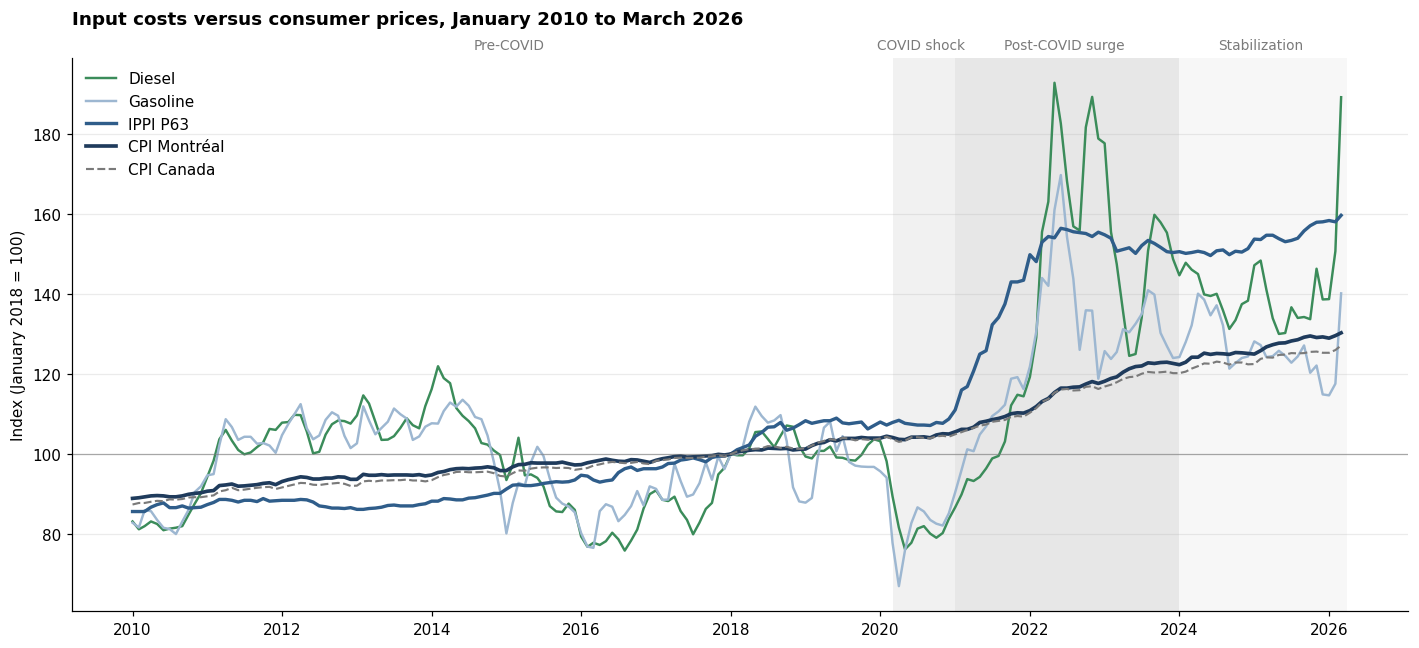

Diesel        peak  192.7 in 2022-05 | March 2026:  189.1
Gasoline      peak  169.7 in 2022-06 | March 2026:  140.1
IPPI P63      peak  159.6 in 2026-03 | March 2026:  159.6
CPI Montréal  peak  130.3 in 2026-03 | March 2026:  130.3
CPI Canada    peak  127.1 in 2026-03 | March 2026:  127.1


In [10]:
# Plot the five normalized series over the analysis period, with regimes shaded, and report each series' peak
ana = master[master["regime"] != "Out-of-sample"]
lines = [("diesel_n", "Diesel", COLORS["green"], "-", 1.6),
         ("gasoline_n", "Gasoline", COLORS["light_blue"], "-", 1.6),
         ("ippi_p63_n", "IPPI P63", COLORS["blue"], "-", 2.2),
         ("cpi_montreal_n", "CPI Montréal", COLORS["navy"], "-", 2.4),
         ("cpi_canada_n", "CPI Canada", COLORS["grey"], "--", 1.4)]

fig, ax = plt.subplots(figsize=(13, 6))
for (regime, (start, end)), shade in zip(REGIMES.items(), [0.0, 0.10, 0.18, 0.06]):
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end) + pd.offsets.MonthEnd(0), color=COLORS["grey"], alpha=shade, lw=0)
    ax.text(pd.Timestamp(start) + (pd.Timestamp(end) - pd.Timestamp(start)) / 2, 1.01, regime,
            transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=9, color=COLORS["grey"])
for col, label, color, style, width in lines:
    ax.plot(ana["month"], ana[col], label=label, color=color, linestyle=style, linewidth=width)
ax.axhline(100, color=COLORS["grey"], linewidth=0.8, alpha=0.6)
ax.set_ylabel("Index (January 2018 = 100)")
ax.set_title("Input costs versus consumer prices, January 2010 to March 2026",
             loc="left", fontsize=12, fontweight="bold", pad=22)
ax.legend(loc="upper left", frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

# Peak normalized value of each series in the analysis period
for col, label, *_ in lines:
    i = ana[col].idxmax()
    print(f"{label:<13} peak {ana.loc[i, col]:6.1f} in {ana.loc[i, 'month']:%Y-%m} | March 2026: {ana[col].iloc[-1]:6.1f}")

**Peak Normalized Values, January 2010 to March 2026**

| Series | Peak | Peak month | March 2026 |
|--------|------|------------|------------|
| Diesel | 192.7 | May 2022 | 189.1 |
| Gasoline | 169.7 | June 2022 | 140.1 |
| IPPI P63 | 159.6 | March 2026 | 159.6 |
| CPI Montréal | 130.3 | March 2026 | 130.3 |
| CPI Canada | 127.1 | March 2026 | 127.1 |



**Reading the Chart by Regime**

- **Pre-COVID:** fuel swings widely, roughly between 75 and 125, while the CPI of Montréal rises smoothly and the IPPI stays close to it. The 2015 to 2016 oil price collapse pulls both fuels down to about 75 to 80 with no visible effect on the CPI: fuel shocks do not pass directly into consumer prices.
- **COVID Shock:** fuel collapses (gasoline below 70, diesel about 76) while the CPI stays near 104 and the IPPI barely moves.
- **Post-COVID surge:** the only sustained period in which every series rises together. Fuel peaks in mid-2022 and then corrects, while the IPPI climbs above 150 and holds that level. A project priced in early 2021 with CPI-based escalation would see input costs rise 35% to 72% while its allowance tracks 16%.
- **Stabilization:** fuel stays well above its 2018 level after retreating from the peaks. The IPPI rises from 150.5 to 159.6 and the CPI keeps growing gradually. The March 2026 diesel spike shows at the right edge of the chart.



**What the Chart Suggests for the Index**

The IPPI follows the CPI most closely in every regime, without the swings of fuel, which makes it the natural anchor of the index. Fuel turns upward early in the post-COVID surge; if it moves ahead of the CPI, it can work as a secondary component that captures sustained energy shocks. Chapter 2 measures whether that lead exists. With the IPPI at its highest level and diesel near its 2022 peak in March 2026, escalation risk remains current.

### **1.3 Month-over-month volatility**

Year-over-year changes show the annual trend; month-over-month changes show how erratically each series moves from one month to the next. This short-term volatility matters for index design: a heavily weighted volatile input would make the index jump with every monthly price swing, even when underlying costs are stable.

The month-over-month change of each series is:

$$\Delta_t = \frac{\text{Index}_t - \text{Index}_{t-1}}{\text{Index}_{t-1}} \times 100$$

The volatility ratio compares the standard deviation of each series with that of the CPI of Montréal:

$$\text{Volatility Ratio} = \frac{\text{Std Dev}(\text{Series})}{\text{Std Dev}(\text{CPI Montréal})}$$

A ratio of 10 means the series moves ten times more, month to month, than consumer prices.

In [11]:
# Compute month-over-month changes and summarize their volatility for the full period and by regime
mom_cols = ["diesel_n", "gasoline_n", "cfi_n", "ippi_p63_n", "cpi_montreal_n", "cpi_canada_n"]
for c in mom_cols:
    master[f"{c}_mom"] = master[c].pct_change(1, fill_method=None) * 100
ana_mom = master[(master["regime"] != "Out-of-sample") & master["cpi_montreal_n_mom"].notna()]
names = {"diesel_n_mom": "Diesel", "gasoline_n_mom": "Gasoline", "cfi_n_mom": "CFI", "ippi_p63_n_mom": "IPPI P63",
         "cpi_montreal_n_mom": "CPI Montréal", "cpi_canada_n_mom": "CPI Canada"}

# Full period summary
rows = []
for col, label in names.items():
    s = ana_mom.set_index("month")[col]
    rows.append([label, s.mean(), s.std(), s.min(), f"{s.idxmin():%Y-%m}", s.max(), f"{s.idxmax():%Y-%m}"])
vol = pd.DataFrame(rows, columns=["Series", "Mean (%)", "Std dev (%)", "Min (%)", "Min month", "Max (%)", "Max month"])
vol["Ratio to CPI Montréal"] = vol["Std dev (%)"] / vol.loc[vol["Series"] == "CPI Montréal", "Std dev (%)"].iloc[0]
print(f"Month-over-month observations: {len(ana_mom)}, {ana_mom['month'].min():%Y-%m} to {ana_mom['month'].max():%Y-%m}\n")
print(vol.round(2).to_string(index=False))

# Standard deviation and volatility ratio by regime
std_r = ana_mom.groupby("regime")[list(names)].std().reindex(list(REGIMES)).rename(columns=names).T
print("\nStandard deviation of the month-over-month change by regime (%):")
print(std_r.round(3).to_string())
print("\nVolatility ratio vs CPI Montréal by regime:")
print((std_r / std_r.loc["CPI Montréal"]).round(1).to_string())



Month-over-month observations: 194, 2010-02 to 2026-03

      Series  Mean (%)  Std dev (%)  Min (%) Min month  Max (%) Max month  Ratio to CPI Montréal
      Diesel      0.53         4.76   -12.48   2023-02    25.52   2026-03                  12.78
    Gasoline      0.39         4.94   -17.32   2020-03    19.20   2026-03                  13.24
         CFI      0.44         4.33   -13.04   2020-03    22.75   2026-03                  11.61
    IPPI P63      0.33         0.99    -2.11   2023-03     5.15   2021-07                   2.65
CPI Montréal      0.20         0.37    -0.73   2014-12     1.37   2011-03                   1.00
  CPI Canada      0.19         0.38    -0.72   2014-12     1.43   2022-03                   1.03

Standard deviation of the month-over-month change by regime (%):
regime        Pre-COVID  COVID shock  Post-COVID surge  Stabilization
Diesel            3.032        5.091             7.408          6.199
Gasoline          4.187        9.396             5.745     

**Full Period Volatility Summary, February 2010 to March 2026 (194 months)**

| Series | Mean | Std dev | Min (month) | Max (month) | Ratio to CPI Montréal |
|--------|------|---------|-------------|-------------|-----------------------|
| Diesel | +0.53% | 4.76% | -12.48% (Feb 2023) | +25.52% (Mar 2026) | 12.8× |
| Gasoline | +0.39% | 4.94% | -17.32% (Mar 2020) | +19.20% (Mar 2026) | 13.2× |
| CFI | +0.44% | 4.33% | -13.04% (Mar 2020) | +22.75% (Mar 2026) | 11.6× |
| IPPI P63 | +0.33% | 0.99% | -2.11% (Mar 2023) | +5.15% (Jul 2021) | 2.6× |
| CPI Montréal | +0.20% | 0.37% | -0.73% (Dec 2014) | +1.37% (Mar 2011) | 1.0× |
| CPI Canada | +0.19% | 0.38% | -0.72% (Dec 2014) | +1.43% (Mar 2022) | 1.0× |



**Standard Deviation of the Month-over-Month Change by Regime (%)**

| Series | Pre-COVID | COVID Shock | Post-COVID surge | Stabilization |
|--------|-----------|-------------|------------------|---------------|
| Diesel | 3.032 | 5.091 | **7.408** | 6.199 |
| Gasoline | 4.187 | **9.396** | 5.745 | 4.841 |
| CFI | 3.144 | **6.357** | 6.002 | 5.296 |
| IPPI P63 | 0.624 | 0.531 | **1.810** | 0.566 |
| CPI Montréal | 0.341 | 0.371 | **0.396** | 0.364 |
| CPI Canada | 0.348 | **0.447** | 0.432 | 0.366 |

Bold values mark the most volatile regime of each series.



**Volatility Ratio vs CPI Montréal by Regime**

| Series | Pre-COVID | COVID Shock | Post-COVID surge | Stabilization |
|--------|-----------|-------------|------------------|---------------|
| Diesel | 8.9× | 13.7× | 18.7× | 17.1× |
| Gasoline | 12.3× | 25.3× | 14.5× | 13.3× |
| CFI | 9.2× | 17.1× | 15.1× | 14.6× |
| IPPI P63 | 1.8× | 1.4× | 4.6× | 1.6× |
| CPI Montréal | 1.0× | 1.0× | 1.0× | 1.0× |
| CPI Canada | 1.0× | 1.2× | 1.1× | 1.0× |


**Key Findings**

- **Fuel is volatile in every regime.** Diesel and gasoline move about 13 times as much as the CPI of Montréal from month to month over the full period, and at least 9 times as much even in the calm pre-COVID years. Averaging the two fuels into the CFI lowers the ratio only slightly, to 11.6.
- **The IPPI behaves much closer to the CPI.** Its ratio stays between 1.4 and 1.8 in every regime except the post-COVID surge, where it rises to 4.6. Even at that peak, the IPPI moves less than either fuel in its calmest regime.
- **Inputs peak in different regimes.** Diesel and the IPPI are most volatile in the post-COVID surge; gasoline and the CFI in the COVID shock, where gasoline reaches 25 times the volatility of the CPI. A likely reason is that lockdowns cut personal driving more than the freight and construction activity that use diesel.
- **The choice of CPI benchmark does not change the results.** The CPIs of Montréal and Canada have almost the same volatility in every regime. The CPI of Montréal remains the main benchmark.

**Month-over-month change by group of series**

The three panels show the monthly changes of fuel, the IPPI and the CPI, each on its own scale, with the economic regimes shaded. The difference in vertical scale between the panels is part of the result.

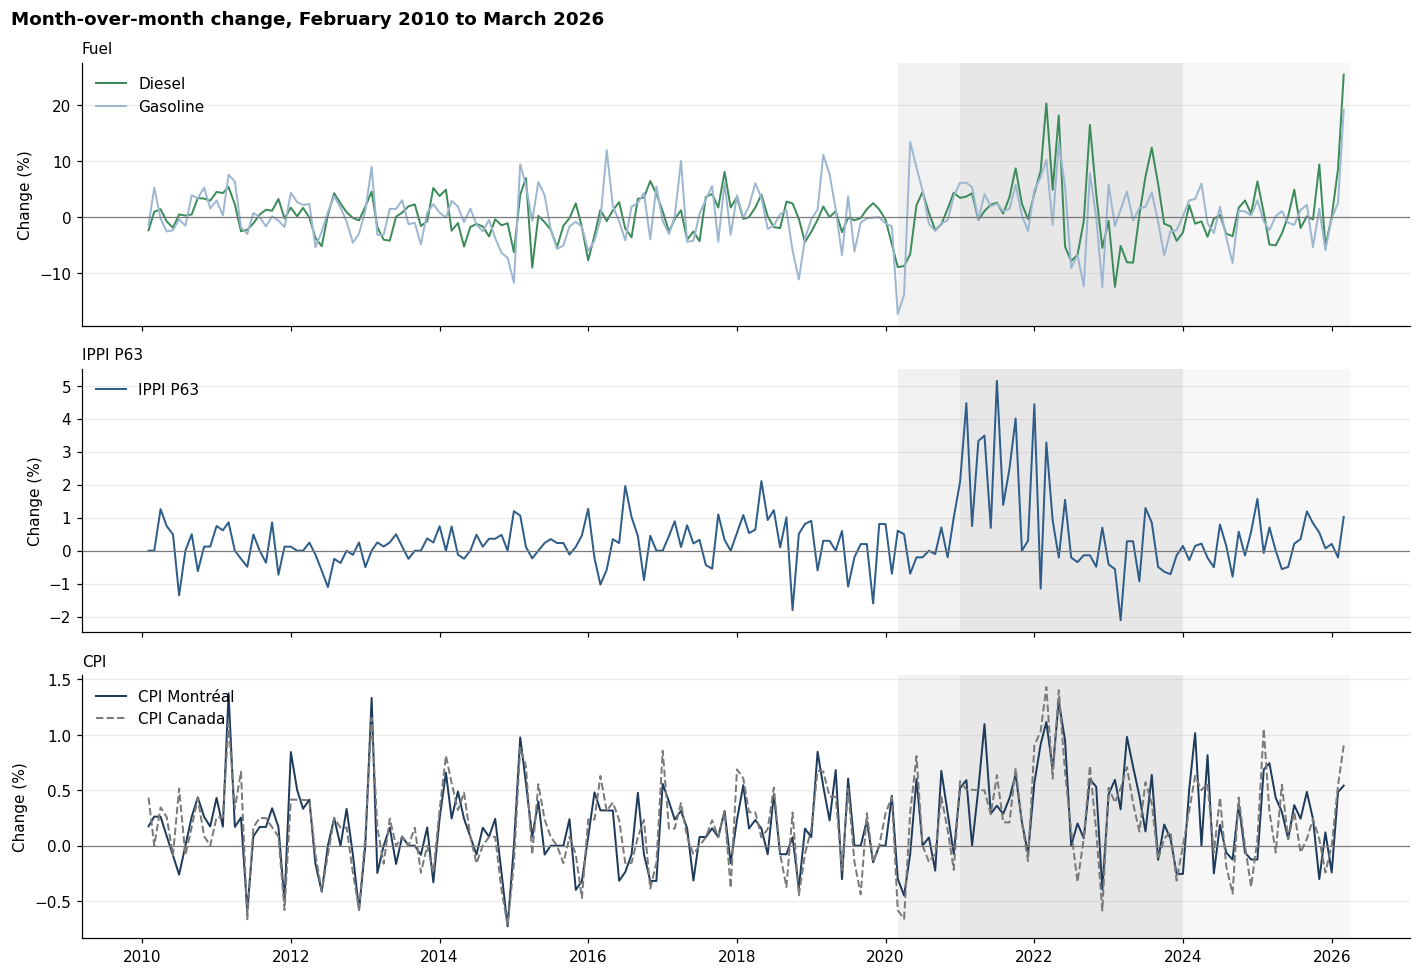

In [12]:
# Plot the month-over-month changes in three panels, each on its own scale: fuel, IPPI and CPI
panels = [("Fuel", [("diesel_n_mom", "Diesel", COLORS["green"], "-"), ("gasoline_n_mom", "Gasoline", COLORS["light_blue"], "-")]),
          ("IPPI P63", [("ippi_p63_n_mom", "IPPI P63", COLORS["blue"], "-")]),
          ("CPI", [("cpi_montreal_n_mom", "CPI Montréal", COLORS["navy"], "-"), ("cpi_canada_n_mom", "CPI Canada", COLORS["grey"], "--")])]

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, (title, series_list) in zip(axes, panels):
    for (regime, (start, end)), shade in zip(REGIMES.items(), [0.0, 0.10, 0.18, 0.06]):
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end) + pd.offsets.MonthEnd(0), color=COLORS["grey"], alpha=shade, lw=0)
    for col, label, color, style in series_list:
        ax.plot(ana_mom["month"], ana_mom[col], label=label, color=color, linestyle=style, linewidth=1.3)
    ax.axhline(0, color=COLORS["grey"], linewidth=0.8)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_ylabel("Change (%)")
    ax.legend(loc="upper left", frameon=False)
    ax.grid(axis="x", visible=False)
fig.suptitle("Month-over-month change, February 2010 to March 2026", x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

**Reading the Chart**

- **Fuel:** both series swing between about -17% and +26% from one month to the next, with no calm regime in the sixteen years. The largest drops come in March 2020 for gasoline and February 2023 for diesel, and the largest rise in March 2026 for both.
- **IPPI P63:** outside the post-COVID surge, monthly changes stay within about -2% and +2%. Its largest move, +5.15% in July 2021, is about the size of one standard deviation of fuel's monthly change.
- **CPI:** the scale of the bottom panel is about twenty times smaller than the fuel panel. The CPI of Montréal never moves more than 1.37% in a single month, and the CPIs of Montréal and Canada move almost together.

A fuel-heavy index would follow monthly price swings rather than sustained escalation. The IPPI is stable enough to anchor the index, and fuel fits better as a secondary component.

### **1.4 Implication for index weight design**

The volatility profile of each input suggests how much weight it can carry in an index. A simple approximation of the volatility of a combination is the weighted sum of the volatility ratios of its components:

$$\text{Composite Volatility} \approx w_{\text{IPPI}} \times \text{Ratio}_{\text{IPPI}} + w_{\text{CFI}} \times \text{Ratio}_{\text{CFI}}$$

This sum is an upper bound: it holds only if the two series move perfectly together. Because the CFI and the IPPI are only partially correlated, the real volatility of a combination is lower. Each structure, from all fuel to all IPPI, is therefore built and its volatility measured directly on the monthly changes of the analysis period. The monthly volatility is also converted to an annual figure by multiplying it by $\sqrt{12}$, which assumes that monthly changes are independent of each other.

In [13]:
# Measure the volatility of CFI / IPPI combinations and compare it with the weighted-sum approximation
cpi_sd = ana_mom["cpi_montreal_n_mom"].std()
r_cfi = ana_mom["cfi_n_mom"].std() / cpi_sd
r_ippi = ana_mom["ippi_p63_n_mom"].std() / cpi_sd
print(f"CPI Montréal monthly std dev: {cpi_sd:.3f}% | ratio CFI: {r_cfi:.2f} | ratio IPPI: {r_ippi:.2f}")
print(f"Correlation of the monthly changes of the CFI and the IPPI: {ana_mom['cfi_n_mom'].corr(ana_mom['ippi_p63_n_mom']):.2f}\n")

rows = []
for w_cfi in [1.0, 0.7, 0.5, 0.35, 0.2, 0.0]:
    combo = w_cfi * master["cfi_n"] + (1 - w_cfi) * master["ippi_p63_n"]
    mom = (combo.pct_change(1, fill_method=None) * 100)[ana_mom.index]
    measured = mom.std() / cpi_sd
    approx = w_cfi * r_cfi + (1 - w_cfi) * r_ippi
    rows.append([f"{w_cfi:.0%} CFI / {1 - w_cfi:.0%} IPPI", approx, measured, mom.std(), mom.std() * np.sqrt(12)])
structures = pd.DataFrame(rows, columns=["Structure", "Approximation (x CPI)", "Measured (x CPI)",
                                         "Monthly std dev (%)", "Annualized std dev (%)"])
print(structures.round(2).to_string(index=False))

CPI Montréal monthly std dev: 0.373% | ratio CFI: 11.61 | ratio IPPI: 2.65
Correlation of the monthly changes of the CFI and the IPPI: 0.18

         Structure  Approximation (x CPI)  Measured (x CPI)  Monthly std dev (%)  Annualized std dev (%)
100% CFI / 0% IPPI                  11.61             11.61                 4.33                   15.00
70% CFI / 30% IPPI                   8.92              8.14                 3.03                   10.51
50% CFI / 50% IPPI                   7.13              6.01                 2.24                    7.76
35% CFI / 65% IPPI                   5.78              4.55                 1.70                    5.88
20% CFI / 80% IPPI                   4.44              3.34                 1.25                    4.32
0% CFI / 100% IPPI                   2.65              2.65                 0.99                    3.42


**Volatility Profile and Preliminary Role of Each Input**

| Series | Volatility vs CPI | Max single month | Preliminary role |
|--------|-------------------|------------------|------------------|
| Diesel | 12.8× | +25.52% | Secondary, combined with gasoline |
| Gasoline | 13.2× | +19.20% | Secondary, combined with diesel |
| CFI | 11.6× | +22.75% | Fuel component, minority weight |
| IPPI P63 | 2.6× | +5.15% | Primary anchor, majority weight |

The roles above follow from volatility alone. The actual weights are estimated by regression in Chapter 3.



**The Composite Volatility Calculation: 35% CFI and 65% IPPI**

| Component | Weight | Volatility ratio | Contribution |
|-----------|--------|------------------|--------------|
| IPPI P63 | 65% | 2.65× | 0.65 × 2.65 = 1.72× |
| CFI | 35% | 11.61× | 0.35 × 11.61 = 4.06× |
| **Approximation** | 100% | | **5.78×** |
| **Measured** | 100% | | **4.55×** |

The approximation assumes that the two series move perfectly together. Their monthly changes have a correlation of only 0.18, so part of their movements cancel out, and the measured volatility of the combination is 21% lower than the approximation.



**Comparison of Weight Structures** (analysis period, 194 months)

| Structure | Approximation | Measured | Monthly std dev | Annualized std dev | Assessment |
|-----------|---------------|----------|-----------------|--------------------|------------|
| 100% CFI | 11.61× | 11.61× | 4.33% | 15.00% | Too volatile: follows every fuel price swing |
| 70% CFI / 30% IPPI | 8.92× | 8.14× | 3.03% | 10.51% | Still dominated by fuel volatility |
| 50% CFI / 50% IPPI | 7.13× | 6.01× | 2.24% | 7.76% | Borderline |
| 35% CFI / 65% IPPI | 5.78× | 4.55× | 1.70% | 5.88% | Stable, with meaningful fuel exposure |
| 20% CFI / 80% IPPI | 4.44× | 3.34× | 1.25% | 4.32% | Stable, with limited fuel exposure |
| 100% IPPI | 2.65× | 2.65× | 0.99% | 3.42% | No fuel exposure: misses energy shocks |



**Reading the Comparison**

A 35% CFI / 65% IPPI structure has a monthly standard deviation of 1.70%. Annualizing it under the independence assumption gives 5.88%. This provides a measure of the structure's typical volatility, but it does not directly establish whether annual adjustments stay within the review band.

Volatility shows how stable a structure is, not how well it tracks escalation. On this measure alone, any structure between 20% and 35% fuel offers a reasonable balance. Chapter 3 estimates the weights that best track the CPI, and Chapter 4 tests the resulting index against the review band using historical adjustments.

### **Implications for cost control**

- **CPI-based escalation understates construction risk.** Over the analysis period, diesel grows 127.4% and the IPPI 86.4%, against 46.5% for the CPI of Montréal. In the post-COVID surge, fuel grows 4 to 5 times as fast as the CPI. An escalation allowance tied only to general inflation leaves most of that gap uncovered.
- **Escalation risk depends on the regime.** The average annual growth of fuel ranges from about -19% to +26% across regimes, while the CPI stays between +0.66% and +5.18%. Escalation assumptions should be reviewed when market conditions change, not fixed once for the life of a project.
- **Fuel is a real cost driver but a poor anchor.** Fuel prices are about 13 times as volatile as the CPI from month to month. An index dominated by fuel would move with short-term price swings rather than with sustained escalation.
- **The IPPI is the natural anchor.** It is the least volatile construction input in every regime, although its volatility is 2.6 times the CPI over the full period. It follows the post-COVID surge without the swings of fuel.
- **A minority fuel weight keeps the index more stable.** A 35% fuel / 65% IPPI structure has an annualized volatility of about 5.9%, against 15.0% for fuel alone. Whether such an index stays inside the review band is tested on historical adjustments in Chapter 4, after Chapter 3 estimates the actual weights.

# **Chapter 2: Association and lead time**

This chapter measures how closely each input moves with consumer prices, and how far ahead. Correlations are computed on year-over-year changes for the full period and for each regime, then tracked over time with a rolling window. The lag analysis tests whether fuel and material prices anticipate the CPI, and by how many months: the lead times found here define the structure of the index in Chapter 3.

### **2.1 Correlation analysis**

Pearson correlation coefficients are computed on year-over-year changes, which help control for seasonality and reduce the influence of the common upward trend that can make price series appear more correlated than they actually are:

$$r = \frac{\sum (x_t - \bar{x})(y_t - \bar{y})}{\sqrt{\sum (x_t - \bar{x})^2 \sum (y_t - \bar{y})^2}}$$

**Reading the Correlation Coefficient**

| Correlation (r) | Interpretation |
|-----------------|----------------|
| 0.80 to 1.00 | Strong positive correlation |
| 0.60 to 0.79 | Moderate positive correlation |
| 0.40 to 0.59 | Weak positive correlation |
| 0.00 to 0.39 | Very weak positive correlation |
| Below 0.00 | Negative correlation |

The correlations are measured for the full period and separately for each regime, against the CPI of Montréal.

In [14]:
# Correlation of the year-over-year changes: full period matrix and correlation with the CPI by regime
corr_labels = {"diesel_n_yoy": "Diesel", "gasoline_n_yoy": "Gasoline", "cfi_n_yoy": "CFI",
               "ippi_p63_n_yoy": "IPPI P63", "cpi_montreal_n_yoy": "CPI Montréal", "cpi_canada_n_yoy": "CPI Canada"}
corr_matrix = ana_yoy[list(corr_labels)].rename(columns=corr_labels).corr()
print(f"Full period correlation matrix ({len(ana_yoy)} months, {ana_yoy['month'].min():%Y-%m} to {ana_yoy['month'].max():%Y-%m}):")
print(corr_matrix.round(3).to_string())

# Correlation of each input with the CPI of Montréal, by regime
inputs = ["diesel_n_yoy", "gasoline_n_yoy", "cfi_n_yoy", "ippi_p63_n_yoy"]
by_reg = {"Full period": ana_yoy[inputs].corrwith(ana_yoy["cpi_montreal_n_yoy"])}
for regime in REGIMES:
    sub = ana_yoy[ana_yoy["regime"] == regime]
    by_reg[f"{regime} ({len(sub)})"] = sub[inputs].corrwith(sub["cpi_montreal_n_yoy"])
print("\nCorrelation with the CPI of Montréal by regime (months in parentheses):")
print(pd.DataFrame(by_reg).rename(index=corr_labels).round(3).to_string())

Full period correlation matrix (183 months, 2011-01 to 2026-03):
              Diesel  Gasoline    CFI  IPPI P63  CPI Montréal  CPI Canada
Diesel         1.000     0.836  0.970     0.665         0.646       0.799
Gasoline       0.836     1.000  0.944     0.668         0.521       0.668
CFI            0.970     0.944  1.000     0.695         0.613       0.770
IPPI P63       0.665     0.668  0.695     1.000         0.516       0.621
CPI Montréal   0.646     0.521  0.613     0.516         1.000       0.942
CPI Canada     0.799     0.668  0.770     0.621         0.942       1.000

Correlation with the CPI of Montréal by regime (months in parentheses):
          Full period  Pre-COVID (110)  COVID shock (10)  Post-COVID surge (36)  Stabilization (27)
Diesel          0.646            0.440             0.492                  0.678               0.287
Gasoline        0.521            0.488             0.061                  0.193               0.406
CFI             0.613            0.473      

**Full Period Correlation Matrix** (year-over-year changes, 183 months, January 2011 to March 2026)

| | Diesel | Gasoline | CFI | IPPI P63 | CPI Montréal | CPI Canada |
|---|---|---|---|---|---|---|
| **Diesel** | 1.000 | 0.836 | 0.970 | 0.665 | 0.646 | 0.799 |
| **Gasoline** | 0.836 | 1.000 | 0.944 | 0.668 | 0.521 | 0.668 |
| **CFI** | 0.970 | 0.944 | 1.000 | 0.695 | 0.613 | 0.770 |
| **IPPI P63** | 0.665 | 0.668 | 0.695 | 1.000 | 0.516 | 0.621 |
| **CPI Montréal** | 0.646 | 0.521 | 0.613 | 0.516 | 1.000 | 0.942 |
| **CPI Canada** | 0.799 | 0.668 | 0.770 | 0.621 | 0.942 | 1.000 |




**Correlation with the CPI of Montréal by Regime** (months in parentheses)

| Series | Full period | Pre-COVID (110) | COVID Shock (10) | Post-COVID surge (36) | Stabilization (27) |
|--------|-------------|-----------------|------------------|-----------------------|--------------------|
| Diesel | 0.646 | 0.440 | 0.492 | 0.678 | 0.287 |
| Gasoline | 0.521 | 0.488 | 0.061 | 0.193 | 0.406 |
| CFI | 0.613 | 0.473 | 0.239 | 0.522 | 0.351 |
| IPPI P63 | 0.516 | -0.047 | 0.432 | 0.200 | 0.113 |

**Key Findings**

- **Every input is positively correlated with the CPI over the full period, but none strongly.** Diesel and the CFI show moderate correlation; gasoline and the IPPI show weak correlation. Correlation alone does not settle which inputs belong in the index: the stability of the relationship and its lead time are tested next.
- **Diesel and gasoline carry largely the same information.** Their correlation of 0.836 means that, side by side in a regression, they would compete for the same signal and produce unstable weights. Combining them into the CFI avoids this; Chapter 3 tests it.
- **The relationship changes with the regime.** Diesel is closest to the CPI in the post-COVID surge (0.678) and weakest in Stabilization (0.287), and gasoline almost disconnects during the COVID shock (0.061). With only 10 months, the COVID shock correlations are the least reliable in the table.
- **The IPPI shows almost no relationship with the CPI in the same month in normal markets** (-0.047 before COVID). Since it follows the CPI closely in level over the same years (section 1.2), a likely reason is that its relationship with consumer prices is stronger when the IPPI is measured several months earlier. Section 2.3 tests this lag.

**Correlation Summary: Implications for Index Design**

| Finding | Implication for the index |
|---------|---------------------------|
| All inputs positively correlated with the CPI (0.516 to 0.646) | The positive associations support testing these inputs as components; their contribution to the index is assessed through stability, lead time, regression fit and out-of-sample performance |
| Diesel has the highest same-month correlation (0.646) | The difference with gasoline is not enough on its own to give diesel a separate weight; the CFI keeps both fuels with equal weights for simplicity and transparency |
| High correlation between the two fuels (0.836) | Combining them into the CFI avoids the unstable weights of multicollinearity; Chapter 3 tests both options |
| Near-zero IPPI correlation before COVID (-0.047) | The timing of the IPPI matters; its contemporaneous value adds little in normal markets, so a lag needs to be tested |
| Fuel tracks the CPI best in the post-COVID surge (diesel 0.678, CFI 0.522) | The fuel component responds most during sustained inflation, the main risk the index is meant to cover |

### **2.1.1 Correlation heatmap**

The two tables of section 2.1 are shown as heatmaps: the full period matrix on the left, and the correlation of each input with the CPI of Montréal by regime on the right. Blue marks positive correlations and green negative ones; the darker the color, the stronger the relationship.

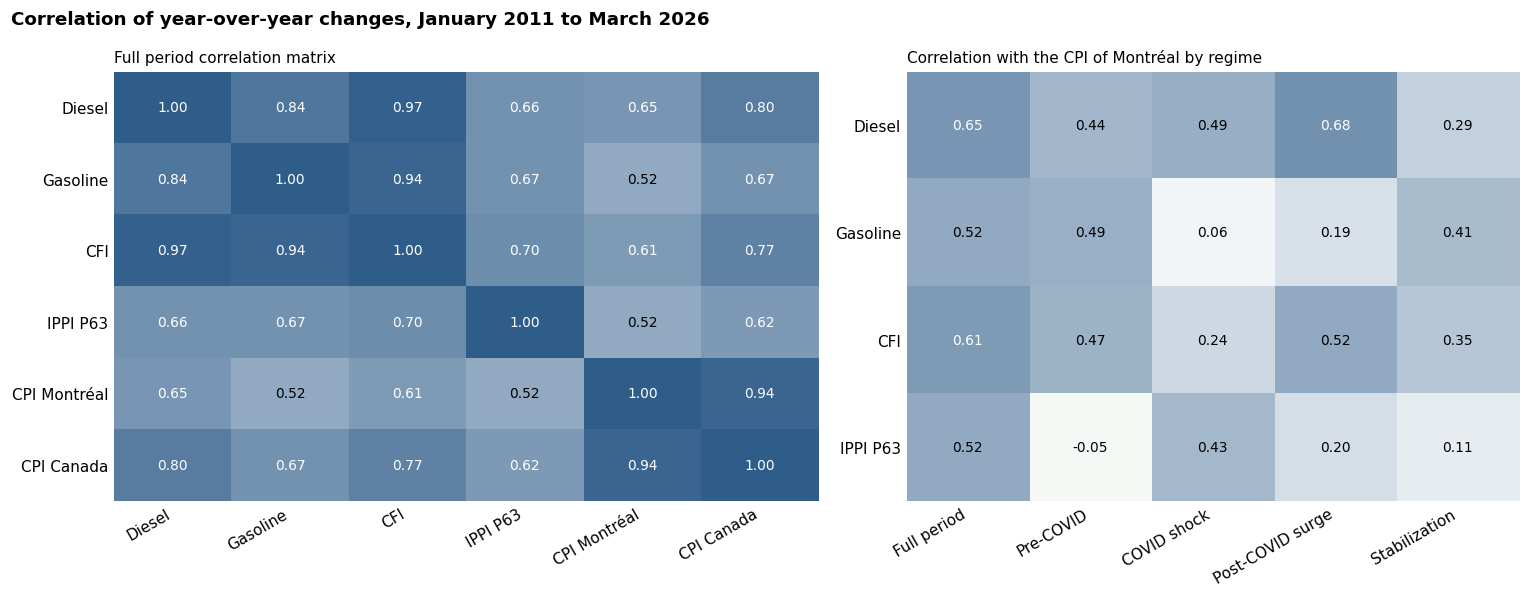

In [15]:
# Heatmaps of the full period correlation matrix and of the input correlations with the CPI by regime
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("cost_control", [COLORS["green"], "white", COLORS["blue"]])
regime_table = pd.DataFrame(by_reg).rename(index=corr_labels)
regime_table.columns = [c.split(" (")[0] for c in regime_table.columns]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.15, 1]})
for ax, table, title in [(axes[0], corr_matrix, "Full period correlation matrix"),
                         (axes[1], regime_table, "Correlation with the CPI of Montréal by regime")]:
    ax.imshow(table.values, cmap=cmap, vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(table.shape[1]), table.columns, rotation=30, ha="right")
    ax.set_yticks(range(table.shape[0]), table.index)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            v = table.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(v) > 0.6 else "black")
    ax.set_title(title, loc="left", fontsize=10)
    ax.grid(False)
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.tick_params(length=0)
fig.suptitle("Correlation of year-over-year changes, January 2011 to March 2026", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

**Reading the Chart**

- **Left panel:** the darkest cells form two clusters, the fuel series (diesel, gasoline and the CFI) and the two CPI benchmarks. The cells that link the inputs to the CPI of Montréal are lighter: every input contributes information, but none tracks the CPI on its own.
- **Right panel:** diesel has the most consistently positive relationship with the CPI across regimes, although its correlation weakens considerably during Stabilization (0.287). Gasoline depends most on the regime and almost disappears during the COVID shock. The CFI sits between the two fuels in every regime: it does not beat diesel alone, but it combines both fuels without the instability of using them separately. The IPPI has the only negative cell, before COVID, and weak or very weak positive values afterwards.

The panel by regime shows what a single full period figure hides. The pre-COVID years make up 60% of the months, and in them fuel shows weak positive correlations while the IPPI shows almost no contemporaneous relationship with the CPI. An index calibrated on same-month correlations would give fuel too much weight and the IPPI too little, which matters for a project that must also hold up in an inflation surge. If the relationship of the IPPI with consumer prices is stronger when the IPPI is measured several months earlier, it should be measured at that lag: section 2.3 tests this, and Chapter 3 uses the result.

### **2.2 Rolling correlation**

A single correlation over sixteen years averages very different market conditions. A rolling correlation recomputes it over a moving window of 36 months, one value per month, and shows how the relationship between each input and the CPI of Montréal evolves over time. With 36 months per window, the first value is available in December 2013.

Each rolling correlation is assigned to the regime in which its 36-month window ends. Windows can therefore include months from more than one regime, particularly around regime transitions. The regime summary describes correlations observed at each endpoint, not correlations calculated exclusively within each regime.

Rolling correlation: 148 windows, 2013-12 to 2026-03

Minimum and maximum rolling correlation by regime:
                 Diesel       Gasoline         CFI       IPPI P63      
                    min   max      min   max   min   max      min   max
regime                                                                 
Pre-COVID         -0.38  0.86    -0.28  0.87 -0.33  0.88    -0.48  0.60
COVID shock       -0.31  0.47    -0.09  0.56 -0.21  0.53    -0.45  0.16
Post-COVID surge   0.47  0.97     0.19  0.90  0.52  0.96     0.15  0.88
Stabilization     -0.34  0.74    -0.11  0.57 -0.28  0.70    -0.48  0.66

Last value (March 2026): {'Diesel': -0.34, 'Gasoline': -0.07, 'CFI': -0.27, 'IPPI P63': -0.48}


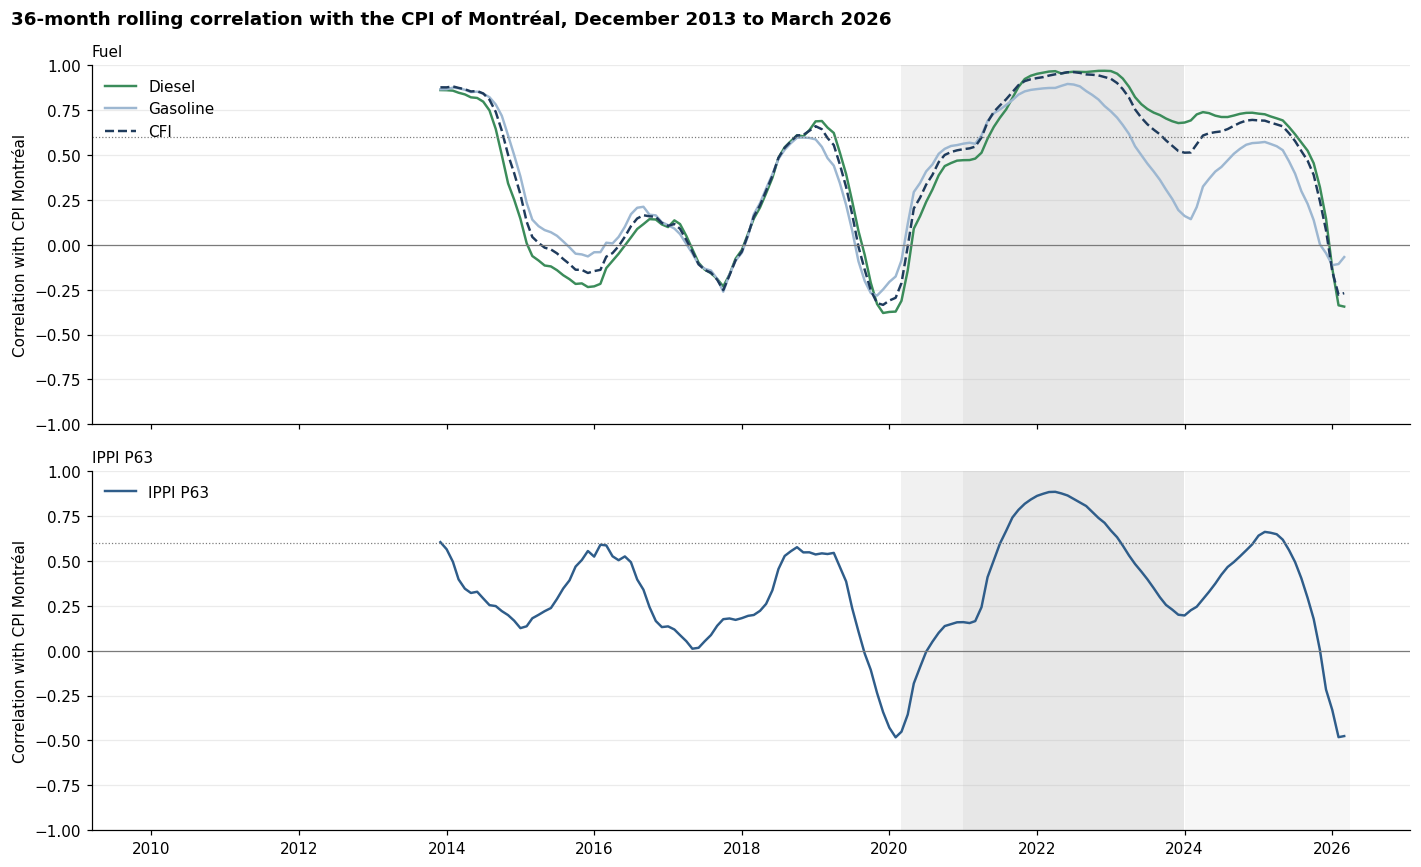

In [16]:
# 36-month rolling correlation of each input with the CPI of Montréal, summarized by regime and plotted
roll = ana_yoy.set_index("month")
roll_corr = pd.DataFrame({label: roll[col].rolling(36).corr(roll["cpi_montreal_n_yoy"])
                          for col, label in [("diesel_n_yoy", "Diesel"), ("gasoline_n_yoy", "Gasoline"),
                                             ("cfi_n_yoy", "CFI"), ("ippi_p63_n_yoy", "IPPI P63")]}).dropna()
roll_corr["regime"] = master.set_index("month").loc[roll_corr.index, "regime"]
print(f"Rolling correlation: {len(roll_corr)} windows, {roll_corr.index.min():%Y-%m} to {roll_corr.index.max():%Y-%m}\n")

# Range of the rolling correlation within each regime, and its last value
summary = roll_corr.groupby("regime").agg(["min", "max"]).reindex(list(REGIMES)).round(2)
print("Minimum and maximum rolling correlation by regime:")
print(summary.to_string())
print("\nLast value (March 2026):", roll_corr.drop(columns="regime").iloc[-1].round(2).to_dict())

# Two panels: fuel series and IPPI
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
panels = [("Fuel", [("Diesel", COLORS["green"], "-"), ("Gasoline", COLORS["light_blue"], "-"), ("CFI", COLORS["navy"], "--")]),
          ("IPPI P63", [("IPPI P63", COLORS["blue"], "-")])]
for ax, (title, series_list) in zip(axes, panels):
    for (regime, (start, end)), shade in zip(REGIMES.items(), [0.0, 0.10, 0.18, 0.06]):
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end) + pd.offsets.MonthEnd(0), color=COLORS["grey"], alpha=shade, lw=0)
    for label, color, style in series_list:
        ax.plot(roll_corr.index, roll_corr[label], label=label, color=color, linestyle=style, linewidth=1.6)
    ax.axhline(0, color=COLORS["grey"], linewidth=0.8)
    ax.axhline(0.6, color=COLORS["grey"], linewidth=0.8, linestyle=":")
    ax.set_ylim(-1, 1)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_ylabel("Correlation with CPI Montréal")
    ax.legend(loc="upper left", frameon=False)
    ax.grid(axis="x", visible=False)
fig.suptitle("36-month rolling correlation with the CPI of Montréal, December 2013 to March 2026",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

**Reading the Chart**

- **Fuel (top panel):** diesel, gasoline and the CFI follow almost the same path. The relationship with the CPI breaks twice before COVID: during the 2015 to 2017 oil price collapse, when fuel fell while consumer prices kept rising, and again in late 2019. It is strongest in 2021 to 2023, above 0.95 for diesel and the CFI, and falls below zero again from late 2025.
- **IPPI (bottom panel):** the path is more irregular. The correlation moves between zero and about 0.6 before 2019, rises in early 2016 while fuel is negative, reaches its trough (-0.48) in late 2019, peaks at 0.88 in 2022 and drops back to -0.48 by March 2026.

**Key Findings**

- **No input keeps a stable relationship with the CPI.** Every series goes through periods of near-zero or negative correlation. The index is not meant to follow the CPI in every month, but to capture sustained escalation, which is when correlations are highest.
- **Fuel and the IPPI are only partly complementary.** In 2015 and 2016 the IPPI holds up while fuel turns negative, which steadies a combined signal. In late 2019 and late 2025 both collapse at the same time.
- **Sustained inflation is when every input works.** In the post-COVID surge, fuel and the IPPI reach their highest correlations together.
- **The relationship is at its weakest at the end of the analysis period.** In the window ending in March 2026, every input is negatively correlated with the CPI. Over those three years, the CPI rises steadily while fuel prices retreat from their 2022 peaks before jumping again in 2026. The IPPI follows a different path: it holds near its 2022 level and then rises only gradually. Section 2.3 tests whether the inputs lead the CPI with a delay, and Chapter 5 follows the index after March 2026.

**Why this matters for the index**

Because input costs and the CPI move apart regularly, the review band matters alongside the index weights. When inputs diverge from consumer prices for a few months, the band is meant to absorb the movement; when they rise together in a sustained surge, the index is expected to cross the band. Chapter 4 tests this on the \$100M reference contract.

### **2.3 Lag analysis**

The weak contemporaneous correlation of the IPPI in normal markets suggests that its relationship with consumer prices may be stronger when the input is measured several months earlier. The lag analysis tests this for every input: the year-over-year change of the input at month $t-k$ is correlated with the year-over-year change of the CPI of Montréal at month $t$, for lags $k$ from 0 to 12 months:

$$r_k = \text{corr}\left(\Delta \text{Input}_{t-k},\ \Delta \text{CPI}_t\right)$$

The lag with the highest correlation is the optimal lead time: how many months ahead the input anticipates consumer prices. Each additional month of lag removes one month from the start of the comparison, so the number of observations falls from 183 at lag 0 to 171 at lag 12.

In [17]:
# Cross-correlation of each input at lags 0 to 12 months with the CPI of Montréal, and the optimal lag of each input
lag_inputs = {"diesel_n_yoy": "Diesel", "gasoline_n_yoy": "Gasoline", "cfi_n_yoy": "CFI", "ippi_p63_n_yoy": "IPPI P63"}
lagged = ana_yoy.set_index("month")
lag_table = pd.DataFrame({label: [lagged[col].shift(k).corr(lagged["cpi_montreal_n_yoy"]) for k in range(13)]
                          for col, label in lag_inputs.items()}, index=pd.Index(range(13), name="Lag (months)"))
lag_table["Observations"] = [lagged["cpi_montreal_n_yoy"].iloc[k:].shape[0] for k in range(13)]
print("Correlation with the CPI of Montréal at each lag:")
print(lag_table.round(3).to_string())

# Optimal lag of each input: the lag with the highest correlation
rows = []
for label in lag_inputs.values():
    k = lag_table[label].idxmax()
    rows.append([label, k, lag_table.loc[0, label], lag_table.loc[k, label], lag_table.loc[k, label] - lag_table.loc[0, label]])
optimal = pd.DataFrame(rows, columns=["Series", "Optimal lag", "Corr at lag 0", "Corr at optimal lag", "Improvement"])
print("\nOptimal lag summary:")
print(optimal.round(3).to_string(index=False))

Correlation with the CPI of Montréal at each lag:
              Diesel  Gasoline    CFI  IPPI P63  Observations
Lag (months)                                                 
0              0.646     0.521  0.613     0.516           183
1              0.661     0.548  0.634     0.562           182
2              0.656     0.552  0.633     0.609           181
3              0.648     0.562  0.633     0.649           180
4              0.634     0.569  0.628     0.683           179
5              0.624     0.577  0.625     0.715           178
6              0.614     0.575  0.620     0.738           177
7              0.600     0.565  0.607     0.755           176
8              0.581     0.556  0.592     0.765           175
9              0.556     0.544  0.572     0.757           174
10             0.527     0.534  0.550     0.748           173
11             0.491     0.519  0.522     0.723           172
12             0.449     0.491  0.484     0.697           171

Optimal lag summary

**Key Findings**

- **The IPPI is the strongest input once its delay is respected.** Its correlation rises steadily from 0.516 at lag 0 to 0.765 at lag 8, then declines. The input with the weakest same-month correlation becomes the most correlated of all at lag 8. This suggests that its weak contemporaneous relationship in sections 2.1 and 2.2 may reflect a timing effect rather than an inherently weak relationship.
- **Diesel and the CFI show an almost immediate relationship with the CPI.** Both peak at lag 1, with only a small gain over lag 0. Gasoline peaks later, at lag 5, with a larger improvement (0.055, against 0.015 for diesel and 0.021 for the CFI), although its peak remains below that of diesel. The CFI follows diesel's timing more closely than gasoline's, consistent with its slightly stronger correlation with diesel (0.970) than with gasoline (0.944) in section 2.1.
- **The exact lead time is less certain than its order of magnitude.** The IPPI correlation stays between 0.738 and 0.765 from lag 6 to lag 10, and the CFI is almost flat from lag 1 to lag 3. The data support a lead of about eight months for materials and about one month for the CFI; the exact month is a choice within a flat peak.

A plausible reading of the eight-month lead is that higher material prices at the producer level reach contractors' invoices first, then new contract prices, and only later construction spending and consumer prices such as shelter costs. This is an interpretation consistent with the data, not something the correlation proves.

In [18]:
# Robustness check: lag correlations on a common sample of 171 months, the sample available at lag 12
yoy = ana_yoy.set_index("month")
inputs = {"Diesel": "diesel_n_yoy", "Gasoline": "gasoline_n_yoy", "CFI": "cfi_n_yoy", "IPPI P63": "ippi_p63_n_yoy"}
cpi_yoy = yoy["cpi_montreal_n_yoy"]
common = cpi_yoy.index[12:]  # CPI months with an input value available at every lag from 0 to 12

lag_common = pd.DataFrame({label: [cpi_yoy.loc[common].corr(yoy[col].shift(k).loc[common]) for k in range(13)]
                           for label, col in inputs.items()})
lag_common.index.name = "Lag (months)"
print(f"Common sample: {len(common)} months, {common.min():%Y-%m} to {common.max():%Y-%m}\n")
print("Cross-correlation with the CPI of Montréal, common sample:")
print(lag_common.round(3).to_string())

# Optimal lag with the varying sample (section 2.3) against the common sample
rows = []
for label in inputs:
    rows.append([label,
                 int(lag_table[label].idxmax()), lag_table[label].max(),
                 int(lag_common[label].idxmax()), lag_common[label].max(), lag_common.loc[0, label]])
check = pd.DataFrame(rows, columns=["Series", "Optimal lag (varying sample)", "Max corr (varying sample)",
                                    "Optimal lag (common sample)", "Max corr (common sample)", "Corr at lag 0 (common sample)"])
print("\nOptimal lag, varying sample against common sample:")
print(check.round(3).to_string(index=False))

Common sample: 171 months, 2012-01 to 2026-03

Cross-correlation with the CPI of Montréal, common sample:
              Diesel  Gasoline    CFI  IPPI P63
Lag (months)                                   
0              0.648     0.526  0.618     0.524
1              0.662     0.553  0.638     0.571
2              0.656     0.557  0.636     0.619
3              0.649     0.567  0.637     0.658
4              0.634     0.575  0.631     0.691
5              0.624     0.582  0.629     0.722
6              0.614     0.579  0.622     0.743
7              0.601     0.569  0.610     0.759
8              0.583     0.559  0.595     0.767
9              0.558     0.545  0.574     0.759
10             0.527     0.535  0.551     0.749
11             0.491     0.520  0.522     0.723
12             0.449     0.491  0.484     0.697

Optimal lag, varying sample against common sample:
  Series  Optimal lag (varying sample)  Max corr (varying sample)  Optimal lag (common sample)  Max corr (common sample)  

**Robustness Check: Common Sample**

Each lag in the main table uses a slightly different sample, from 183 months at lag 0 to 171 at lag 12, so part of the difference between lags could come from the change in the comparison period. Repeating the analysis on a common sample of 171 months (January 2012 to March 2026) removes that effect. The optimal lag is the same for every input: 1 month for diesel and the CFI, 5 for gasoline and 8 for the IPPI. The peak correlations change by at most 0.005, and the gain of the IPPI from lag 0 to lag 8 stays almost unchanged (from 0.524 to 0.767, against 0.516 to 0.765 in the main table). The lead times do not depend on the sample used.

### **2.3.1 Lag analysis chart**

The correlation of each input with the CPI of Montréal is plotted against the lag, from 0 to 12 months, with the optimal lag of each series marked. The shape of each curve shows how the strength of the association with the CPI changes across lags and how sharply it peaks.

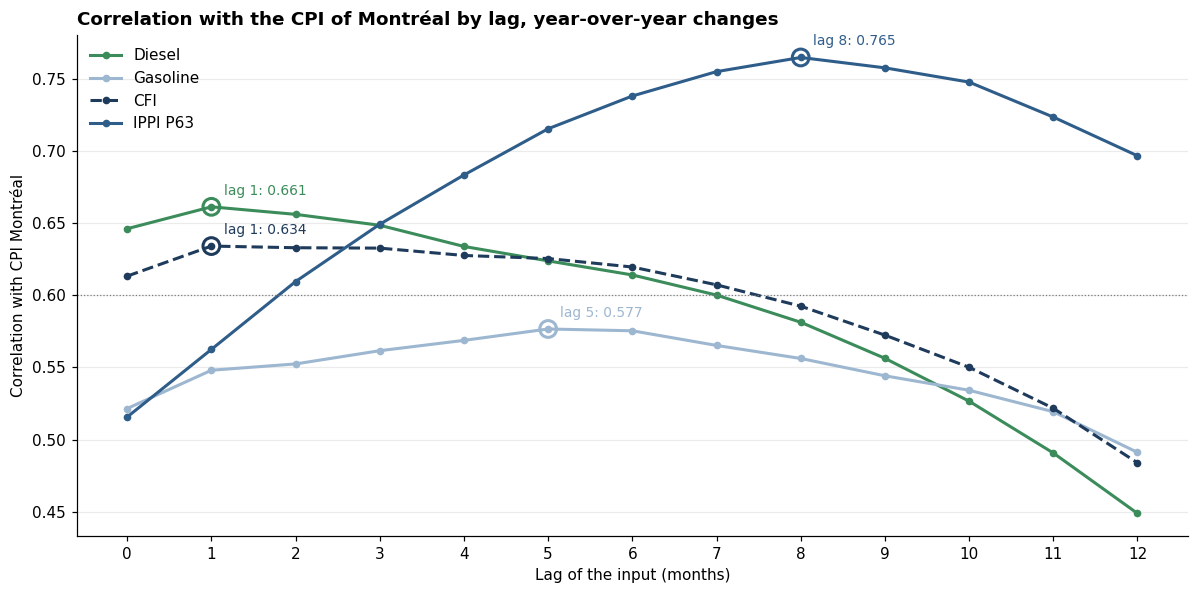

In [19]:
# Plot the correlation of each input with the CPI against the lag, marking the optimal lag of each series
lag_styles = {"Diesel": (COLORS["green"], "-"), "Gasoline": (COLORS["light_blue"], "-"),
              "CFI": (COLORS["navy"], "--"), "IPPI P63": (COLORS["blue"], "-")}

fig, ax = plt.subplots(figsize=(11, 5.5))
for label, (color, style) in lag_styles.items():
    ax.plot(lag_table.index, lag_table[label], label=label, color=color, linestyle=style, linewidth=2, marker="o", markersize=4)
    k = lag_table[label].idxmax()
    ax.scatter(k, lag_table.loc[k, label], s=120, facecolor="none", edgecolor=color, linewidth=2, zorder=3)
    ax.annotate(f"lag {k}: {lag_table.loc[k, label]:.3f}", (k, lag_table.loc[k, label]),
                textcoords="offset points", xytext=(8, 8), fontsize=9, color=color)
ax.axhline(0.6, color=COLORS["grey"], linewidth=0.8, linestyle=":")
ax.set_xticks(range(13))
ax.set_xlabel("Lag of the input (months)")
ax.set_ylabel("Correlation with CPI Montréal")
ax.set_title("Correlation with the CPI of Montréal by lag, year-over-year changes",
             loc="left", fontsize=12, fontweight="bold")
ax.legend(loc="upper left", frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Each curve shows how the correlation of one input with the CPI changes as the input is moved further back in time. A curve that peaks early shows that the strongest association occurs at a short lag; a curve that keeps rising shows that the association becomes stronger at longer lags. The dotted line at 0.6 marks the start of moderate correlation in the scale of section 2.1.

The fuel curves peak early and then decline. Diesel and the CFI reach their highest values at lag 1 (0.661 and 0.634) and stay at or above 0.6 through lag 7, then fall below it. Gasoline rises slowly to a flat peak at lag 5 (0.577) and never reaches the 0.6 threshold.

The IPPI follows a different path. It starts as the weakest input at lag 0 (0.516), crosses 0.6 between lag 1 and lag 2, and passes both diesel and the CFI between lag 2 and lag 3. It keeps rising until lag 8 (0.765) and declines only slowly after that: even at lag 12 its correlation (0.697) is higher than the best value of any fuel series at any lag.

The flat top of the IPPI curve shows why the 8-month lag is best read as the center of a range from about 6 to 10 months.

**Summary of the Lag Analysis**

Diesel and the CFI peak at lag 1, so the fuel component uses the values of the previous month. The IPPI peaks at lag 8, so the material component uses the values of eight months earlier. Gasoline has the lowest peak of the four series (0.577) and peaks at a different lag (5 months). Combining both fuels in the CFI keeps a single fuel component with one lag; the main reason to combine them is their high correlation with each other (0.836, section 2.1). Chapter 3 examines whether the two fuels add separable information when they enter the regression together.

The index therefore takes the form:

$$\text{Index}_t = w_{\text{CFI}} \times \text{CFI}_{t-1} + w_{\text{IPPI}} \times \text{IPPI}_{t-8}$$

Each component enters at the lag where its correlation with the CPI is strongest. Chapter 3 estimates the weights $w_{\text{CFI}}$ and $w_{\text{IPPI}}$ and compares this structure with alternatives.

### **Implications for cost control**

- **Material prices can serve as an early signal.** The IPPI has its strongest correlation with the CPI when it is measured about eight months earlier. A rise in fabricated metal and construction material prices is therefore a reason to review escalation allowances on active projects and on bids in preparation, not a confirmation that the pressure will reach the wider economy. Chapter 5 tests how well the lagged inputs forecast the CPI on months not used to build the model.
- **The fuel component gives little advance notice.** The CFI has its strongest correlation with the CPI at a one-month lag, almost the same as at lag 0, so it reflects current cost pressure rather than pressure months ahead. Gasoline alone peaks at a longer lag, but the combined component follows the timing of diesel.
- **One input is not enough.** No input tracks the CPI consistently across regimes, and every rolling correlation turns negative at some point, including the most recent window. Fuel and materials are partly complementary: in 2015 and 2016 the IPPI holds up while fuel turns negative. They also weaken together, as in late 2019 and late 2025, so combining them does not remove periods of decoupling. Whether the combination, with each input at its own lag, improves the index is assessed in Chapters 3 to 5.
- **Expect periods of decoupling.** Input costs and consumer prices drift apart for months at a time, as in 2015 to 2017, late 2019 to early 2020 and late 2025 to early 2026. Monthly movements of the index are therefore better read against a review band than acted on one by one. The band is a monitoring rule set in the Project Constants, not a result of the correlations; Chapter 4 tests how it behaves on the \$100M reference contract.

# **Chapter 3: Index modeling**

This chapter estimates how much weight each input should carry in the index. Candidate regression models are compared on how well they track the year-over-year change of the CPI of Montréal, with and without the lags of Chapter 2. The best model is tested for multicollinearity and for the effect of forcing a larger fuel weight, and regressions by regime are tried as an alternative. The chapter ends with three candidate indexes (M12, M14 and M15), whose coefficients are converted into weights; the choice among them is made in Chapter 6.

### **3.1 Regression dataset**

Ordinary Least Squares (OLS) regression quantifies the relationship between the inputs and the CPI of Montréal, using year-over-year changes. Thirteen model specifications are tested, from single contemporaneous inputs to combinations with the lags found in Chapter 2:

$$\Delta\text{CPI}_t = \alpha + \beta_1 \Delta\text{Input}_{1,t-\tau_1} + \beta_2 \Delta\text{Input}_{2,t-\tau_2} + \beta_3 \Delta\text{Input}_{3,t-\tau_3} + \varepsilon_t$$

where every variable is a year-over-year percentage change and $\tau$ is the lag in months (0 for contemporaneous).

**Regression Dataset**

| Property | Value |
|----------|-------|
| Dependent variable | CPI Montréal, year-over-year change |
| Independent variables | Diesel, gasoline, CFI and IPPI P63, year-over-year change, at different lags |
| Observations | 175 months, September 2011 to March 2026 |

The longest lag, 8 months for the IPPI, removes the first 8 of the 183 year-over-year months, so every model is estimated on the same 175 months.

**Evaluation Metrics**

| Metric | Definition | Reading |
|--------|------------|---------|
| R² | Share of the variance of the CPI explained by the model | Higher is better, maximum 1 |
| RMSE | Typical size of the prediction error, in percentage points | Lower is better |
| Directional accuracy | Share of months in which the predicted CPI change moves in the same direction as the actual one, up or down, compared with the previous month | 50% equals a coin flip |

In [20]:
# Build the regression dataset: year-over-year changes with the lags of Chapter 2, on a common sample
reg = ana_yoy.set_index("month")[["diesel_n_yoy", "gasoline_n_yoy", "cfi_n_yoy",
                                  "ippi_p63_n_yoy", "cpi_montreal_n_yoy", "regime"]].copy()
reg["diesel_lag1"] = reg["diesel_n_yoy"].shift(1)
reg["gasoline_lag5"] = reg["gasoline_n_yoy"].shift(5)
reg["cfi_lag1"] = reg["cfi_n_yoy"].shift(1)
reg["cfi_lag3"] = reg["cfi_n_yoy"].shift(3)
reg["ippi_lag8"] = reg["ippi_p63_n_yoy"].shift(8)
reg = reg.dropna()

print(f"Regression dataset: {len(reg)} months, {reg.index.min():%Y-%m} to {reg.index.max():%Y-%m}")
print("Months by regime:", reg["regime"].value_counts().reindex(list(REGIMES)).to_dict())

# Descriptive statistics of the year-over-year variables used in the models (%)
print("\n", reg.drop(columns="regime").describe().T[["mean", "std", "min", "max"]].round(2).to_string())

Regression dataset: 175 months, 2011-09 to 2026-03
Months by regime: {'Pre-COVID': 102, 'COVID shock': 10, 'Post-COVID surge': 36, 'Stabilization': 27}

                     mean    std    min     max
diesel_n_yoy        4.72  22.32 -35.39  104.40
gasoline_n_yoy      2.83  16.28 -37.13   58.72
cfi_n_yoy           3.65  18.41 -28.34   77.61
ippi_p63_n_yoy      4.28   7.64  -4.01   34.92
cpi_montreal_n_yoy  2.41   1.75   0.00    7.64
diesel_lag1         4.65  22.25 -35.39  104.40
gasoline_lag5       3.71  16.72 -37.13   58.72
cfi_lag1            3.66  18.43 -28.34   77.61
cfi_lag3            4.02  18.55 -28.34   77.61
ippi_lag8           4.21   7.66  -4.01   34.92


**Descriptive Statistics of the Regression Variables** (year-over-year change, 175 months)

| Variable | Mean (%) | Std dev | Min (%) | Max (%) |
|----------|----------|---------|---------|---------|
| CPI Montréal | 2.41 | 1.75 | 0.00 | 7.64 |
| Diesel | 4.72 | 22.32 | -35.39 | 104.40 |
| Gasoline | 2.83 | 16.28 | -37.13 | 58.72 |
| CFI | 3.65 | 18.41 | -28.34 | 77.61 |
| IPPI P63 | 4.28 | 7.64 | -4.01 | 34.92 |
| Diesel, lag 1 | 4.65 | 22.25 | -35.39 | 104.40 |
| Gasoline, lag 5 | 3.71 | 16.72 | -37.13 | 58.72 |
| CFI, lag 1 | 3.66 | 18.43 | -28.34 | 77.61 |
| CFI, lag 3 | 4.02 | 18.55 | -28.34 | 77.61 |
| IPPI P63, lag 8 | 4.21 | 7.66 | -4.01 | 34.92 |

The dataset has 175 months, from September 2011 to March 2026: 102 in Pre-COVID, 10 in the COVID shock, 36 in the post-COVID surge and 27 in Stabilization. The CPI moves within a narrow range, from 0.00% to 7.64% a year, while the inputs swing much more: diesel from -35.39% to +104.40%. The spread of the inputs also differs widely, with a standard deviation of 7.64 points for the IPPI against 16.28 to 22.32 for fuel. Section 3.6 comes back to this difference when the coefficients are converted into index weights.

### **3.2 Candidate models**

Thirteen models are estimated on the same 175 months. Each one tests a different question about which inputs, and at which lag, best track the CPI of Montréal.

**Candidate Models**

| Model | Inputs | What it tests |
|-------|--------|---------------|
| M1 | Diesel | Diesel alone, contemporaneous |
| M2 | Gasoline | Gasoline alone, contemporaneous |
| M3 | IPPI | IPPI alone, contemporaneous |
| M4 | Diesel + gasoline | The two fuels together, without materials |
| M5 | Diesel + IPPI | The strongest fuel with materials |
| M6 | Gasoline + IPPI | The weaker fuel with materials |
| M7 | Diesel + gasoline + IPPI | All three inputs, contemporaneous |
| M8 | Diesel at lag 1 + gasoline at lag 5 + IPPI at lag 8 | All three inputs, each at its optimal lag from Chapter 2 |
| M9 | Diesel + gasoline + IPPI at lag 8 | Contemporaneous fuels with lagged materials |
| M10 | CFI | The combined fuel index alone, contemporaneous |
| M11 | CFI + IPPI | Combined fuel with materials, contemporaneous |
| M12 | CFI at lag 1 + IPPI at lag 8 | Combined fuel and materials, each at its optimal lag |
| M13 | CFI at lag 3 + IPPI at lag 8 | Same as M12 with a longer fuel lag, to test the sensitivity to the fuel lag |

Directional accuracy compares the direction of the month-to-month change of the fitted and the actual CPI. Because the fitted values come from a model estimated on the same 175 months, it measures in-sample directional agreement, not forecasting performance; the out-of-sample test is in Chapter 5. A naive version that compares only the sign of the levels is also shown for reference: because the year-over-year CPI is almost always positive, it is close to 100% for any model and says nothing about direction.

In [21]:
# Estimate the 13 candidate OLS models and compare their fit, direction accuracy and coefficients
import statsmodels.api as sm

MODELS = {
    "M1":  ["diesel_n_yoy"],
    "M2":  ["gasoline_n_yoy"],
    "M3":  ["ippi_p63_n_yoy"],
    "M4":  ["diesel_n_yoy", "gasoline_n_yoy"],
    "M5":  ["diesel_n_yoy", "ippi_p63_n_yoy"],
    "M6":  ["gasoline_n_yoy", "ippi_p63_n_yoy"],
    "M7":  ["diesel_n_yoy", "gasoline_n_yoy", "ippi_p63_n_yoy"],
    "M8":  ["diesel_lag1", "gasoline_lag5", "ippi_lag8"],
    "M9":  ["diesel_n_yoy", "gasoline_n_yoy", "ippi_lag8"],
    "M10": ["cfi_n_yoy"],
    "M11": ["cfi_n_yoy", "ippi_p63_n_yoy"],
    "M12": ["cfi_lag1", "ippi_lag8"],
    "M13": ["cfi_lag3", "ippi_lag8"],
}
y = reg["cpi_montreal_n_yoy"]

def direction_accuracy(actual, predicted):
    # Share of months where the predicted and actual changes move in the same direction
    return (np.sign(np.diff(actual)) == np.sign(np.diff(predicted))).mean() * 100

results, perf, coefs = {}, [], []
for name, cols in MODELS.items():
    fit = sm.OLS(y, sm.add_constant(reg[cols])).fit()
    results[name] = fit
    pred = fit.fittedvalues
    perf.append([name, " + ".join(cols), fit.rsquared, fit.rsquared_adj, np.sqrt(fit.mse_resid * fit.df_resid / fit.nobs),
                 direction_accuracy(y.values, pred.values), (np.sign(y) == np.sign(pred)).mean() * 100,
                 "yes" if (fit.params.drop("const") < 0).any() else "no"])
    coefs.append(pd.Series(fit.params.round(4), name=name))

perf = pd.DataFrame(perf, columns=["Model", "Inputs", "R2", "Adj R2", "RMSE", "Dir acc (%)",
                                   "Dir acc, naive (%)", "Negative coef"])
print(perf.round(4).to_string(index=False))
print("\nCoefficients:")
print(pd.DataFrame(coefs).fillna("").to_string())

Model                                         Inputs     R2  Adj R2   RMSE  Dir acc (%)  Dir acc, naive (%) Negative coef
   M1                                   diesel_n_yoy 0.4198  0.4165 1.3270      56.8966             99.4286            no
   M2                                 gasoline_n_yoy 0.2773  0.2732 1.4810      66.0920             99.4286            no
   M3                                 ippi_p63_n_yoy 0.2717  0.2675 1.4868      50.0000             99.4286            no
   M4                  diesel_n_yoy + gasoline_n_yoy 0.4204  0.4137 1.3263      56.3218             99.4286           yes
   M5                  diesel_n_yoy + ippi_p63_n_yoy 0.4308  0.4242 1.3144      60.9195             99.4286            no
   M6                gasoline_n_yoy + ippi_p63_n_yoy 0.3205  0.3126 1.4361      67.8161             99.4286            no
   M7 diesel_n_yoy + gasoline_n_yoy + ippi_p63_n_yoy 0.4350  0.4251 1.3096      53.4483             99.4286           yes
   M8        diesel_lag1

**Model Performance** (175 months, September 2011 to March 2026)

| Model | Inputs | R² | Adj R² | RMSE | Dir acc | Dir acc, naive | Negative coef |
|-------|--------|----|--------|------|---------|----------------|---------------|
| M1 | Diesel | 0.4198 | 0.4165 | 1.327 | 56.9% | 99.4% | no |
| M2 | Gasoline | 0.2773 | 0.2732 | 1.481 | 66.1% | 99.4% | no |
| M3 | IPPI | 0.2717 | 0.2675 | 1.487 | 50.0% | 99.4% | no |
| M4 | Diesel + gasoline | 0.4204 | 0.4137 | 1.326 | 56.3% | 99.4% | yes |
| M5 | Diesel + IPPI | 0.4308 | 0.4242 | 1.314 | 60.9% | 99.4% | no |
| M6 | Gasoline + IPPI | 0.3205 | 0.3126 | 1.436 | 67.8% | 99.4% | no |
| M7 | Diesel + gasoline + IPPI | 0.4350 | 0.4251 | 1.310 | 53.4% | 99.4% | yes |
| M8 | Diesel lag 1 + gasoline lag 5 + IPPI lag 8 | 0.6120 | 0.6051 | 1.085 | 61.5% | 99.4% | no |
| M9 | Diesel + gasoline + IPPI lag 8 | 0.6555 | 0.6495 | 1.023 | 70.7% | 99.4% | yes |
| M10 | CFI | 0.3816 | 0.3780 | 1.370 | 66.1% | 99.4% | no |
| M11 | CFI + IPPI | 0.3922 | 0.3852 | 1.358 | 66.7% | 99.4% | no |
| **M12** | **CFI lag 1 + IPPI lag 8** | **0.6247** | **0.6203** | **1.067** | **59.8%** | 99.4% | **no** |
| M13 | CFI lag 3 + IPPI lag 8 | 0.6052 | 0.6006 | 1.095 | 56.3% | 99.4% | no |





**Model Coefficients**

| Model | Intercept | Diesel | Gasoline | IPPI | Diesel lag 1 | Gasoline lag 5 | IPPI lag 8 | CFI | CFI lag 1 | CFI lag 3 |
|-------|-----------|--------|----------|------|--------------|----------------|------------|-----|-----------|-----------|
| M1 | 2.1679 | 0.0507 | | | | | | | | |
| M2 | 2.2471 | | 0.0565 | | | | | | | |
| M3 | 1.8969 | | | 0.1192 | | | | | | |
| M4 | 2.1677 | 0.0536 | -0.0047 | | | | | | | |
| M5 | 2.0635 | 0.0430 | | 0.0329 | | | | | | |
| M6 | 2.0212 | | 0.0338 | 0.0678 | | | | | | |
| M7 | 2.0390 | 0.0494 | -0.0134 | 0.0405 | | | | | | |
| M8 | 1.7440 | | | | 0.0126 | 0.0097 | 0.1350 | | | |
| M9 | 1.6466 | -0.0139 | 0.0426 | | | | 0.1675 | | | |
| M10 | 2.1933 | | | | | | | 0.0586 | | |
| M11 | 2.0837 | | | 0.0345 | | | | 0.0482 | | |
| M12 | 1.7385 | | | | | | 0.1376 | | 0.0244 | |
| M13 | 1.7293 | | | | | | 0.1432 | | | 0.0187 |

Adding the lags of Chapter 2 is the largest improvement: the best contemporaneous model explains 43.5% of the variance of the CPI (M7), and the lagged models explain between 60.5% and 65.6% (M8, M9, M12, M13). The 8-month lag of the IPPI drives most of this gain.

M9 has the highest R² (0.6555), but its diesel coefficient is negative. M4 and M7 show the same problem with gasoline. A negative weight would mean that a rise in fuel prices lowers the index, which makes no economic sense and cannot be defended in an escalation index. The negative coefficients appear only when diesel and gasoline enter the same model, a sign of multicollinearity that section 3.3 measures.

Among the models with positive coefficients, M12 fits best: R² of 0.6247 and an RMSE of 1.067 percentage points. A longer fuel lag (M13) lowers the fit, which supports the 1-month lag for the CFI.

Directional accuracy is moderate for every model, between 50.0% and 70.7%, and 59.8% for M12. In-sample, the models track the level of annual inflation better than the direction of its month-to-month changes. The naive version gives 99.4% for all thirteen models, so it cannot tell them apart.

### **3.3 Multicollinearity**

When two inputs move closely together, a regression cannot tell how much of the effect belongs to each one. The coefficients become unstable and can take the wrong sign, as one of the two fuels does in M4, M7 and M9. The variance inflation factor (VIF) measures this for each input:

$$\text{VIF}_j = \frac{1}{1 - R^2_j}$$

where $R^2_j$ is the share of the variance of input $j$ explained by the other inputs of the model. A VIF of 1 means no overlap; values above 5 are a common warning sign, and above 10 a serious problem. The standard errors and p-values of the coefficients show the same instability from another angle: an input whose effect cannot be separated has a large standard error and a coefficient that is not significantly different from zero.

In [22]:
# VIF of each input in the multi-input models, and coefficient precision in the models with and without both fuels
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_rows = []
for name in ["M4", "M5", "M6", "M7", "M8", "M9", "M11", "M12", "M13"]:
    X = sm.add_constant(reg[MODELS[name]])
    for i, col in enumerate(MODELS[name], start=1):
        vif_rows.append([name, col, variance_inflation_factor(X.values, i)])
print("Variance inflation factor by model and input:")
print(pd.DataFrame(vif_rows, columns=["Model", "Input", "VIF"]).round(2).to_string(index=False))

# Coefficient, standard error and p-value in the models that mix both fuels, and in M12
print("\nCoefficient precision:")
for name in ["M4", "M7", "M9", "M12"]:
    fit = results[name]
    table = pd.DataFrame({"coef": fit.params, "std err": fit.bse, "p-value": fit.pvalues}).drop("const")
    print(f"\n{name}:")
    print(table.round(4).to_string())

Variance inflation factor by model and input:
Model          Input  VIF
   M4   diesel_n_yoy 3.27
   M4 gasoline_n_yoy 3.27
   M5   diesel_n_yoy 1.89
   M5 ippi_p63_n_yoy 1.89
   M6 gasoline_n_yoy 2.03
   M6 ippi_p63_n_yoy 2.03
   M7   diesel_n_yoy 3.47
   M7 gasoline_n_yoy 3.73
   M7 ippi_p63_n_yoy 2.16
   M8    diesel_lag1 3.28
   M8  gasoline_lag5 2.46
   M8      ippi_lag8 2.15
   M9   diesel_n_yoy 6.43
   M9 gasoline_n_yoy 4.10
   M9      ippi_lag8 2.29
  M11      cfi_n_yoy 2.14
  M11 ippi_p63_n_yoy 2.14
  M12       cfi_lag1 1.65
  M12      ippi_lag8 1.65
  M13       cfi_lag3 1.92
  M13      ippi_lag8 1.92

Coefficient precision:

M4:
                  coef  std err  p-value
diesel_n_yoy    0.0536   0.0082   0.0000
gasoline_n_yoy -0.0047   0.0113   0.6785

M7:
                  coef  std err  p-value
diesel_n_yoy    0.0494   0.0084   0.0000
gasoline_n_yoy -0.0134   0.0119   0.2618
ippi_p63_n_yoy  0.0405   0.0193   0.0374

M9:
                  coef  std err  p-value
diesel_n_yoy   

**Variance Inflation Factor by Model and Input**

| Model | Input | VIF |
|-------|-------|-----|
| M4 | Diesel | 3.27 |
| M4 | Gasoline | 3.27 |
| M5 | Diesel | 1.89 |
| M5 | IPPI | 1.89 |
| M6 | Gasoline | 2.03 |
| M6 | IPPI | 2.03 |
| M7 | Diesel | 3.47 |
| M7 | Gasoline | 3.73 |
| M7 | IPPI | 2.16 |
| M8 | Diesel, lag 1 | 3.28 |
| M8 | Gasoline, lag 5 | 2.46 |
| M8 | IPPI, lag 8 | 2.15 |
| M9 | Diesel | **6.43** |
| M9 | Gasoline | 4.10 |
| M9 | IPPI, lag 8 | 2.29 |
| M11 | CFI | 2.14 |
| M11 | IPPI | 2.14 |
| **M12** | **CFI, lag 1** | **1.65** |
| **M12** | **IPPI, lag 8** | **1.65** |
| M13 | CFI, lag 3 | 1.92 |
| M13 | IPPI, lag 8 | 1.92 |





**Coefficient Precision in the Models with Both Fuels, and in M12**

| Model | Input | Coefficient | Std error | p-value |
|-------|-------|-------------|-----------|---------|
| M4 | Diesel | 0.0536 | 0.0082 | < 0.001 |
| M4 | Gasoline | -0.0047 | 0.0113 | 0.679 |
| M7 | Diesel | 0.0494 | 0.0084 | < 0.001 |
| M7 | Gasoline | -0.0134 | 0.0119 | 0.262 |
| M7 | IPPI | 0.0405 | 0.0193 | 0.037 |
| M9 | Diesel | -0.0139 | 0.0089 | 0.121 |
| M9 | Gasoline | 0.0426 | 0.0098 | < 0.001 |
| M9 | IPPI, lag 8 | 0.1675 | 0.0155 | < 0.001 |
| M12 | CFI, lag 1 | 0.0244 | 0.0057 | < 0.001 |
| M12 | IPPI, lag 8 | 0.1376 | 0.0137 | < 0.001 |

The overlap between diesel and gasoline is moderate: most VIF values are between 2 and 4, and only diesel in M9 passes the warning level of 5 (6.43). The negative coefficients come from a related problem. None of them is significantly different from zero (p-values of 0.679, 0.262 and 0.121), and in each model the other fuel takes almost all the effect. Once one fuel is in the model, the data cannot reliably separate the contribution of the second: its coefficient is estimated with low precision, so its sign is not reliable. Which fuel ends up negative even changes between models: gasoline in M4 and M7, diesel in M9.

Combining both fuels in the CFI removes the problem by construction. M12 has the lowest VIF of all multi-input models (1.65), and both of its coefficients are positive, precisely estimated and significant (p < 0.001).

### **3.4 Constrained regression**

In M12, the fuel coefficient is 15.1% of the sum of the two coefficients (0.0244 against 0.1376). This share is the statistical optimum, but it can look low for projects with significant and continuous fuel exposure. The question is how much fit is lost when the fuel share is forced into a higher range: if the loss is small, a higher share is defensible; if it is large, it needs an economic justification beyond the statistics.

Unconstrained OLS minimizes the prediction error with no restriction on the coefficients:

$$\min \sum_t \left(\Delta\text{CPI}_t - \alpha - \beta_1 \Delta\text{CFI}_{t-1} - \beta_2 \Delta\text{IPPI}_{t-8}\right)^2$$

Constrained regression keeps the same objective, subject to:

$$\beta_1 \geq 0, \quad \beta_2 \geq 0, \quad w_{\min} \leq \frac{\beta_1}{\beta_1 + \beta_2} \leq w_{\max}$$

For each fuel share $s$ inside the bounds, the model reduces to a regression on one combined input, $s \cdot \Delta\text{CFI}_{t-1} + (1-s) \cdot \Delta\text{IPPI}_{t-8}$, and the best fit within each range is found by searching every share in steps of 0.1 percentage points.



**Scenarios Tested**

| Scenario | Fuel share range | Interpretation |
|----------|------------------|----------------|
| Unconstrained | No limit | Statistical optimum |
| Constraint A | 15% to 25% | Minimal adjustment |
| Constraint B | 20% to 30% | Conservative adjustment |
| Constraint C | 25% to 35% | Moderate adjustment |
| Constraint D | 30% to 40% | Substantial fuel exposure |
| Constraint E | 35% to 45% | High fuel intensity |
| Constraint F | 40% to 50% | Maximum reasonable fuel exposure |

The result to watch is where the fit starts to deteriorate. A drop in R² from 0.6247 to about 0.61 would be a small cost; a drop toward 0.40 would mean the constrained weights cannot be defended statistically.

In [23]:
# Best fit within each fuel share range: grid search over the share, one combined input per share
m12 = results["M12"]
s_free = m12.params["cfi_lag1"] / (m12.params["cfi_lag1"] + m12.params["ippi_lag8"])

def fit_share(s):
    # Regression on the combined input for a fixed fuel share s
    z = s * reg["cfi_lag1"] + (1 - s) * reg["ippi_lag8"]
    return sm.OLS(y, sm.add_constant(z)).fit()

SCENARIOS = {"Unconstrained": (0.0, 1.0), "Constraint A": (0.15, 0.25), "Constraint B": (0.20, 0.30),
             "Constraint C": (0.25, 0.35), "Constraint D": (0.30, 0.40), "Constraint E": (0.35, 0.45),
             "Constraint F": (0.40, 0.50)}
rows = []
for name, (lo, hi) in SCENARIOS.items():
    grid = np.round(np.arange(lo, hi + 0.0005, 0.001), 3)
    r2 = [fit_share(s).rsquared for s in grid]
    s_best = grid[int(np.argmax(r2))]
    fit = fit_share(s_best)
    k = fit.params.iloc[1]
    rows.append([name, f"{lo:.0%} to {hi:.0%}", s_best, k * s_best, k * (1 - s_best), fit.rsquared,
                 fit.rsquared - m12.rsquared, np.sqrt(fit.ssr / fit.nobs)])
constrained = pd.DataFrame(rows, columns=["Scenario", "Range", "Fuel share", "CFI coef", "IPPI coef",
                                          "R2", "R2 loss", "RMSE"])
print(f"Unconstrained M12 fuel share: {s_free:.1%}, R2 {m12.rsquared:.4f}\n")
print(constrained.round(4).to_string(index=False))

Unconstrained M12 fuel share: 15.1%, R2 0.6247

     Scenario      Range  Fuel share  CFI coef  IPPI coef     R2  R2 loss   RMSE
Unconstrained 0% to 100%       0.151    0.0244     0.1375 0.6247  -0.0000 1.0673
 Constraint A 15% to 25%       0.151    0.0244     0.1375 0.6247  -0.0000 1.0673
 Constraint B 20% to 30%       0.200    0.0309     0.1236 0.6215  -0.0032 1.0718
 Constraint C 25% to 35%       0.250    0.0366     0.1097 0.6130  -0.0117 1.0838
 Constraint D 30% to 40%       0.300    0.0413     0.0965 0.6008  -0.0239 1.1008
 Constraint E 35% to 45%       0.350    0.0453     0.0842 0.5861  -0.0385 1.1208
 Constraint F 40% to 50%       0.400    0.0486     0.0729 0.5702  -0.0545 1.1422


**Constrained Regression Results**

| Scenario | Range | Best fuel share | CFI coef | IPPI coef | R² | R² loss | RMSE |
|----------|-------|-----------------|----------|-----------|----|---------|------|
| Unconstrained | No limit | 15.1% | 0.0244 | 0.1375 | 0.6247 | 0.0000 | 1.067 |
| Constraint A | 15% to 25% | 15.1% | 0.0244 | 0.1375 | 0.6247 | 0.0000 | 1.067 |
| Constraint B | 20% to 30% | 20.0% | 0.0309 | 0.1236 | 0.6215 | -0.0032 | 1.072 |
| Constraint C | 25% to 35% | 25.0% | 0.0366 | 0.1097 | 0.6130 | -0.0117 | 1.084 |
| Constraint D | 30% to 40% | 30.0% | 0.0413 | 0.0965 | 0.6008 | -0.0239 | 1.101 |
| Constraint E | 35% to 45% | 35.0% | 0.0453 | 0.0842 | 0.5861 | -0.0385 | 1.121 |
| Constraint F | 40% to 50% | 40.0% | 0.0486 | 0.0729 | 0.5702 | -0.0545 | 1.142 |

Range A contains the unconstrained optimum, so it changes nothing. In every other scenario, the best fit sits at the lower bound of the range: the closer the fuel share stays to 15.1%, the better the model tracks the CPI.

The fit deteriorates gradually, with no sharp break. Raising the fuel share to 20% costs only 0.0032 of R². At 30%, the model still explains 60.1% of the variance of the CPI, a loss of 0.0239 (3.8% of the unconstrained R²), and the RMSE rises from 1.067 to 1.101 points. Each additional 5 points of fuel share costs a little more than the previous one: 0.0085 of R² from 20% to 25%, 0.0122 from 25% to 30%, 0.0147 from 30% to 35% and 0.0159 from 35% to 40%.

A fuel share of up to about 30% keeps the fit close to the optimum, with the model still explaining more than 60% of the variance of the CPI. Within that range, the choice depends more on the cost structure of the project than on the statistics.

### **3.4.1 Constrained alternative: M14**

The constrained model at a 30% fuel share is designated M14. It is not a statistical optimum: with the fuel share forced to at least 30%, the best fit always lands at the 30% bound, because the unconstrained optimum is 15.1%. The 30% comes from a judgment about the fuel intensity of a project, and the regression measures what that judgment costs. M14 is kept as an alternative for projects with heavy and continuous fuel use, next to M12, the statistical optimum.

In [24]:
# Compare M12 (statistical optimum) with M14 (fuel share fixed at 30%): equation, fit and direction accuracy
m14 = fit_share(0.30)
rows = []
for name, fit, s in [("M12", m12, s_free), ("M14", m14, 0.30)]:
    if name == "M12":
        b1, b2 = fit.params["cfi_lag1"], fit.params["ippi_lag8"]
    else:
        k = fit.params.iloc[1]
        b1, b2 = k * 0.30, k * 0.70
    rows.append([name, fit.params["const"], b1, b2, s, fit.rsquared, np.sqrt(fit.ssr / fit.nobs),
                 direction_accuracy(y.values, fit.fittedvalues.values)])
compare = pd.DataFrame(rows, columns=["Model", "Intercept", "CFI coef", "IPPI coef", "Fuel share",
                                      "R2", "RMSE", "Dir acc (%)"])
print(compare.round(4).to_string(index=False))

Model  Intercept  CFI coef  IPPI coef  Fuel share     R2   RMSE  Dir acc (%)
  M12     1.7385    0.0244     0.1376      0.1505 0.6247 1.0673      59.7701
  M14     1.8496    0.0413     0.0965      0.3000 0.6008 1.1008      58.6207


**From Regression to Index Formula**

The regression equations predict the year-over-year change of the CPI from the year-over-year changes of the inputs:

$$\text{M12:} \quad \Delta\text{CPI}_t = 1.739 + 0.0244 \times \Delta\text{CFI}_{t-1} + 0.1376 \times \Delta\text{IPPI}_{t-8}$$

$$\text{M14:} \quad \Delta\text{CPI}_t = 1.850 + 0.0413 \times \Delta\text{CFI}_{t-1} + 0.0965 \times \Delta\text{IPPI}_{t-8}$$

Dividing each coefficient by the sum of the two turns them into weights that add up to 100%: 15.1% and 84.9% for M12, and 30.0% and 70.0% for M14 (0.0413 / 0.1378 and 0.0965 / 0.1378). Applied to the normalized series (January 2018 = 100), these weights give the index formulas used at each review date:

$$\text{M12:} \quad \text{Index}_t = 0.151 \times \text{CFI}_{t-1} + 0.849 \times \text{IPPI}_{t-8}$$

$$\text{M14:} \quad \text{Index}_t = 0.30 \times \text{CFI}_{t-1} + 0.70 \times \text{IPPI}_{t-8}$$

where $\text{CFI}_{t-1} = (\text{Diesel}^{n}_{t-1} + \text{Gasoline}^{n}_{t-1}) / 2$. The intercept drops out: the index does not predict the CPI, it combines the inputs.



**Model Comparison**

| Property | M12 | M14 |
|----------|-----|-----|
| Type | Unconstrained OLS | Constrained OLS, fuel share fixed at 30% |
| CFI weight (diesel + gasoline) | 15.1% (7.55% each) | 30.0% (15.0% each) |
| IPPI P63 weight | 84.9% | 70.0% |
| CFI lag | 1 month | 1 month |
| IPPI lag | 8 months | 8 months |
| R² | 0.6247 | 0.6008 |
| RMSE | 1.067 | 1.101 |
| Directional accuracy | 59.8% | 58.6% |
| Coefficients positive | Yes | Yes |
| Basis of the fuel weight | Statistical optimum | Judgment on fuel intensity |

Doubling the fuel weight costs little in fit: 0.0239 of R², 0.034 points of RMSE and 1.2 points of directional accuracy. M12 remains the statistically optimal index. M14 is a defensible alternative when a project's fuel exposure is clearly above average, provided the 30% is justified by the project's cost breakdown rather than by the regression.

### **3.4.2 Model comparison chart**

The chart has four panels. The first three compare the fourteen models side by side: R², RMSE and the fuel weight implied by each regression. The fourth shows the constrained frontier: how the R² of the M12 specification changes as the fuel share is forced from 15% to 40%, with M12 and M14 marked. Colors group the models by family, M12 is highlighted, and hatched bars mark the models with a negative coefficient, which cannot be used in an escalation index whatever their fit.

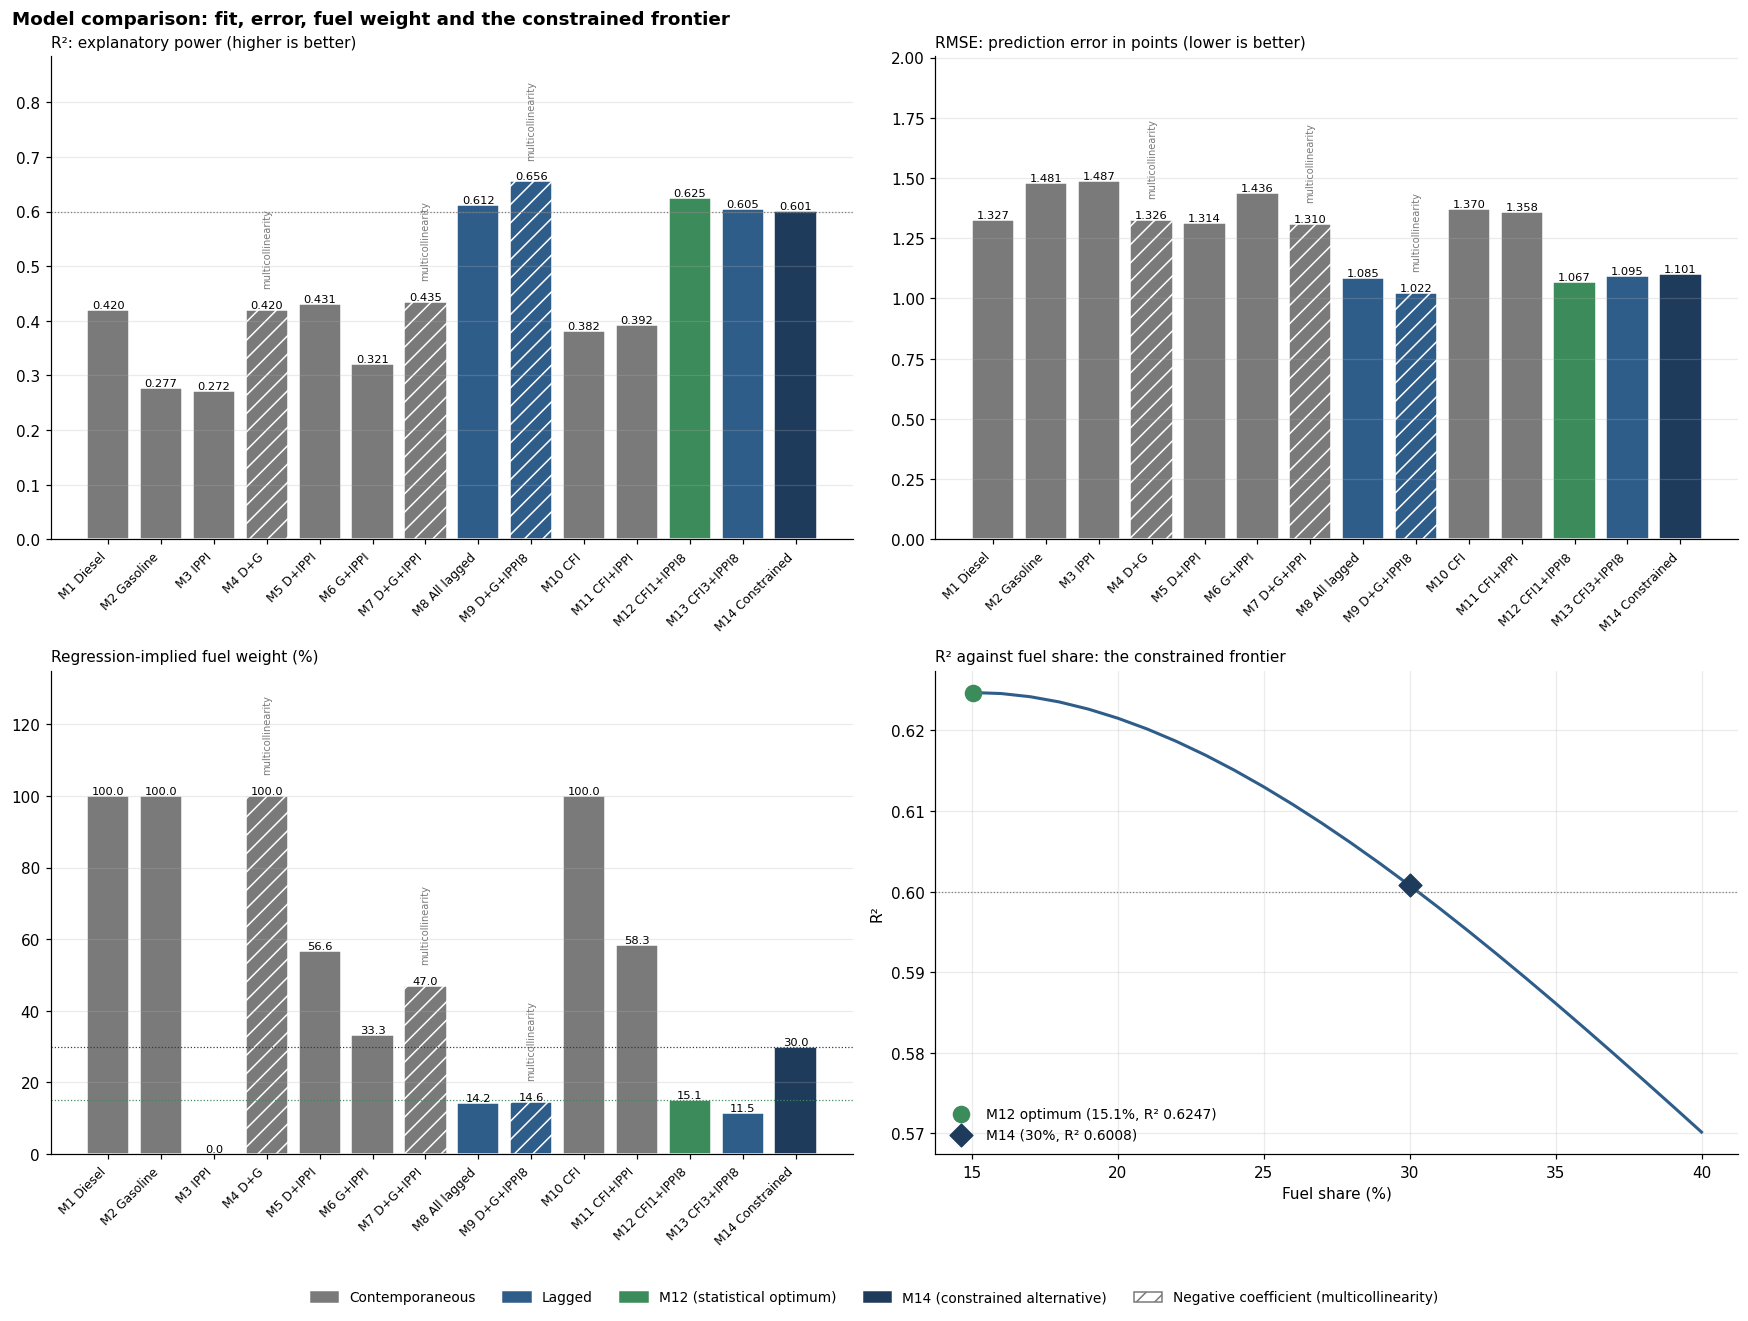

In [25]:
# Four-panel model comparison: R2, RMSE, regression-implied fuel weight and the constrained frontier
from matplotlib.patches import Patch
labels = {"M1": "Diesel", "M2": "Gasoline", "M3": "IPPI", "M4": "D+G", "M5": "D+IPPI", "M6": "G+IPPI",
          "M7": "D+G+IPPI", "M8": "All lagged", "M9": "D+G+IPPI8", "M10": "CFI", "M11": "CFI+IPPI",
          "M12": "CFI1+IPPI8", "M13": "CFI3+IPPI8", "M14": "Constrained"}
fuel_terms = ("diesel", "gasoline", "cfi")

rows = []
for name in list(MODELS) + ["M14"]:
    if name == "M14":
        r2, rmse, share, neg = m14.rsquared, np.sqrt(m14.ssr / m14.nobs), 30.0, False
    else:
        fit = results[name]
        b = fit.params.drop("const")
        fuel = b[[c for c in b.index if c.startswith(fuel_terms)]].sum()
        r2, rmse, share, neg = fit.rsquared, np.sqrt(fit.ssr / fit.nobs), fuel / b.sum() * 100, (b < 0).any()
    rows.append([name, r2, rmse, share, neg])
cmp_df = pd.DataFrame(rows, columns=["Model", "R2", "RMSE", "Fuel weight", "Negative"])

def bar_color(m):
    # Green for M12, navy for M14, blue for lagged models, grey for contemporaneous models
    if m == "M12": return COLORS["green"]
    if m == "M14": return COLORS["navy"]
    return COLORS["blue"] if m in ("M8", "M9", "M13") else COLORS["grey"]
colors = [bar_color(m) for m in cmp_df["Model"]]
hatches = ["//" if n else "" for n in cmp_df["Negative"]]
xlabels = [f"{m} {labels[m]}" for m in cmp_df["Model"]]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
panels = [(axes[0, 0], "R2", "R²: explanatory power (higher is better)", "{:.3f}"),
          (axes[0, 1], "RMSE", "RMSE: prediction error in points (lower is better)", "{:.3f}"),
          (axes[1, 0], "Fuel weight", "Regression-implied fuel weight (%)", "{:.1f}")]
for ax, col, title, fmt in panels:
    bars = ax.bar(range(len(cmp_df)), cmp_df[col], color=colors, hatch=hatches, edgecolor="white")
    top = cmp_df[col].max()
    for b, v, neg in zip(bars, cmp_df[col], cmp_df["Negative"]):
        x = b.get_x() + b.get_width() / 2
        ax.text(x, max(v, 0), fmt.format(v), ha="center", va="bottom", fontsize=7.5)
        if neg:
            # Flag the models whose negative coefficient comes from multicollinearity
            ax.text(x, max(v, 0) + top * 0.06, "multicollinearity", ha="center", va="bottom",
                    fontsize=6.5, color=COLORS["grey"], rotation=90)
    ax.set_ylim(0, top * 1.35)
    ax.set_xticks(range(len(cmp_df)), xlabels, fontsize=8, rotation=45, ha="right")
    ax.set_title(title, loc="left", fontsize=10)
    ax.grid(axis="x", visible=False)
axes[0, 0].axhline(0.6, color=COLORS["grey"], linewidth=0.8, linestyle=":")
axes[1, 0].axhline(15.1, color=COLORS["green"], linewidth=0.8, linestyle=":")
axes[1, 0].axhline(30, color=COLORS["navy"], linewidth=0.8, linestyle=":")

# Constrained frontier: R2 against the fuel share of the M12 specification
grid = np.round(np.arange(0.15, 0.401, 0.01), 2)
ax = axes[1, 1]
ax.plot(grid * 100, [fit_share(s).rsquared for s in grid], color=COLORS["blue"], linewidth=2)
ax.scatter(s_free * 100, m12.rsquared, s=110, color=COLORS["green"], zorder=3, label=f"M12 optimum ({s_free:.1%}, R² {m12.rsquared:.4f})")
ax.scatter(30, m14.rsquared, s=110, color=COLORS["navy"], marker="D", zorder=3, label=f"M14 (30%, R² {m14.rsquared:.4f})")
ax.axhline(0.6, color=COLORS["grey"], linewidth=0.8, linestyle=":")
ax.set_xlabel("Fuel share (%)")
ax.set_ylabel("R²")
ax.set_title("R² against fuel share: the constrained frontier", loc="left", fontsize=10)
ax.legend(loc="lower left", frameon=False, fontsize=9)

handles = [Patch(color=COLORS["grey"], label="Contemporaneous"), Patch(color=COLORS["blue"], label="Lagged"),
           Patch(color=COLORS["green"], label="M12 (statistical optimum)"), Patch(color=COLORS["navy"], label="M14 (constrained alternative)"),
           Patch(facecolor="white", edgecolor=COLORS["grey"], hatch="//", label="Negative coefficient (multicollinearity)")]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Model comparison: fit, error, fuel weight and the constrained frontier", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

**Reading the Chart**

- **R² and RMSE:** the two top panels show the same ranking from opposite directions. The lagged models (M8, M9, M12, M13) and M14 are the only ones near or above the 0.6 line, with RMSE between 1.02 and 1.10 points; every contemporaneous model stays below 0.44, with RMSE above 1.30. M9 has the best fit of all, but its hatched bar marks a negative coefficient caused by multicollinearity, so it cannot be used. M12 is the best model without that problem.
- **Fuel weight:** when the IPPI enters without a lag, the models give fuel a large share of the weight: 33.3% in M6, 56.6% in M5 and 58.3% in M11. Once the IPPI enters at its 8-month lag, the fuel weight falls to between 11.5% and 15.1% (M8, M12, M13), because the lagged IPPI explains most of what fuel seemed to explain before. The fuel weight of a model depends as much on the timing of the IPPI as on fuel itself.
- **Constrained frontier:** the curve is flat close to the M12 optimum and steepens gradually as the fuel share rises. R² falls slowly up to about 20%, then a little faster with each step, and reaches the 0.6 line at the 30% of M14.

### **3.5 Regime regression**

The M12 specification (CFI at lag 1, IPPI at lag 8) is estimated separately within each economic regime, to check whether the fuel share is stable across market conditions or shifts with them.

**Regression Windows by Regime**

| Regime | Window | Months |
|--------|--------|--------|
| Pre-COVID | September 2011 to February 2020 | 102 |
| COVID (extended) | January 2020 to June 2021 | 18 |
| Post-COVID surge | January 2021 to December 2023 | 36 |
| Stabilization | January 2024 to March 2026 | 27 |

The COVID shock has only 10 months, too few for a regression, so its window is extended to 18 months: two months before the shock and six after it. The extended window therefore overlaps the last two months of the Pre-COVID window (January and February 2020) and the first six months of the Post-COVID surge window (January to June 2021), and these months enter two regressions each. All regime results rest on small samples, and the COVID result is indicative only.

The earlier chapters give some expectations. Before COVID, the same-month IPPI correlation is close to zero, but the lag should restore its weight. In the post-COVID surge, fuel reaches its strongest correlation with the CPI, so its share may rise. If every regime gives a share close to M12 (15.1%), the weights are robust; if the shares diverge widely, that instability has to be acknowledged.

The regime shares are then combined into one blended fuel share, weighting each regime by its relevance for a multi-year project starting in 2026. The post-COVID surge, the scenario of greatest cost risk, receives the largest weight, followed by Stabilization, the regime closest to current conditions. These blending weights are a judgment, not an estimate.

**Blending Weights**

| Regime | Blending weight |
|--------|-----------------|
| Pre-COVID | 5% |
| COVID (extended) | 5% |
| Post-COVID surge | 60% |
| Stabilization | 30% |

In [26]:
# Estimate M12 within each regime, then blend the regime fuel shares with the first set of weights
REG_WINDOWS = {"Pre-COVID": ("2011-09-01", "2020-02-01"), "COVID (extended)": ("2020-01-01", "2021-06-01"),
               "Post-COVID surge": ("2021-01-01", "2023-12-01"), "Stabilization": ("2024-01-01", "2026-03-01")}
rows = []
for regime, (start, end) in REG_WINDOWS.items():
    sub = reg.loc[start:end]
    fit = sm.OLS(sub["cpi_montreal_n_yoy"], sm.add_constant(sub[["cfi_lag1", "ippi_lag8"]])).fit()
    b1, b2 = fit.params["cfi_lag1"], fit.params["ippi_lag8"]
    rows.append([regime, len(sub), fit.params["const"], b1, b2, b1 / (b1 + b2), fit.rsquared, np.sqrt(fit.ssr / fit.nobs)])
regime_fits = pd.DataFrame(rows, columns=["Regime", "N", "Intercept", "CFI coef", "IPPI coef",
                                          "Fuel share", "R2", "RMSE"]).set_index("Regime")
print(regime_fits.round(4).to_string())

# First blend: weight of each regime and its contribution to the blended fuel share
BLEND_1 = np.array([0.05, 0.05, 0.60, 0.30])
shares = regime_fits["Fuel share"].values
contrib = pd.DataFrame({"Blending weight": BLEND_1, "Regime fuel share": shares, "Contribution": BLEND_1 * shares},
                       index=regime_fits.index)
print("\nFirst blend:")
print(contrib.round(4).to_string())
print(f"Blended fuel share: {contrib['Contribution'].sum():.1%}")

                    N  Intercept  CFI coef  IPPI coef  Fuel share      R2    RMSE
Regime                                                                           
Pre-COVID         102     1.1665    0.0230     0.1255      0.1549  0.3364  0.5422
COVID (extended)   18     1.9186    0.0636     0.0465      0.5780  0.8848  0.4051
Post-COVID surge   36     3.6637    0.0059     0.1038      0.0538  0.8003  0.6882
Stabilization      27     2.8029    0.0203     0.0816      0.1994  0.1207  0.5674

First blend:
                  Blending weight  Regime fuel share  Contribution
Regime                                                            
Pre-COVID                    0.05             0.1549        0.0077
COVID (extended)             0.05             0.5780        0.0289
Post-COVID surge             0.60             0.0538        0.0323
Stabilization                0.30             0.1994        0.0598
Blended fuel share: 12.9%


**Regime Regression Results** (CFI at lag 1, IPPI at lag 8)

| Regime | N | Intercept | CFI coef | IPPI coef | Fuel share | R² | RMSE |
|--------|---|-----------|----------|-----------|------------|----|------|
| Pre-COVID | 102 | 1.1665 | 0.0230 | 0.1255 | 15.5% | 0.3364 | 0.542 |
| COVID (extended) | 18 | 1.9186 | 0.0636 | 0.0465 | 57.8% | 0.8848 | 0.405 |
| Post-COVID surge | 36 | 3.6637 | 0.0059 | 0.1038 | 5.4% | 0.8003 | 0.688 |
| Stabilization | 27 | 2.8029 | 0.0203 | 0.0816 | 19.9% | 0.1207 | 0.567 |
| Full period (M12) | 175 | 1.7385 | 0.0244 | 0.1376 | 15.1% | 0.6247 | 1.067 |

**First Blend**

| Regime | Blending weight | Regime fuel share | Contribution |
|--------|-----------------|-------------------|--------------|
| Pre-COVID | 5% | 15.5% | 0.8 points |
| COVID (extended) | 5% | 57.8% | 2.9 points |
| Post-COVID surge | 60% | 5.4% | 3.2 points |
| Stabilization | 30% | 19.9% | 6.0 points |
| **Blended fuel share** | **100%** | | **12.9%** |

The fuel share is not stable across regimes. Before COVID it is 15.5%, almost the same as the full period model. In the post-COVID surge it falls to 5.4%: the lagged IPPI explains most of the inflation of those years, with an R² of 0.80, and leaves little for fuel. Stabilization gives 19.9%, but its R² of 0.12 means the model explains little of that period. The COVID window gives 57.8%, because fuel collapses while the IPPI barely moves; with 18 overlapping months, this result is indicative only.

The first blend gives 12.9%, below the 15.1% of the full period model. The post-COVID surge carries 60% of the weight but contributes only 3.2 points, because its own fuel share is unusually low; the result depends heavily on a single regime whose share is the lowest of the four. Stabilization, the regime closest to current conditions, points to a higher share (19.9%) but has only half the weight. This dependence on one atypical regime calls for a second look at the blending weights.


### **3.5.1 Alternative blending**

The first blend gives 60% of the weight to the post-COVID surge, the regime with the most unusual fuel share, and the result depends heavily on it. An alternative blend reduces that dominance and gives more weight to the other regimes, especially Stabilization, the most relevant for a project priced in 2025 or 2026:

**First and Alternative Blending Weights**

| Regime | First blend | Alternative blend | Change |
|--------|-------------|-------------------|--------|
| Pre-COVID | 5% | 15% | +10 points |
| COVID (extended) | 5% | 10% | +5 points |
| Post-COVID surge | 60% | 40% | -20 points |
| Stabilization | 30% | 35% | +5 points |

Since any set of blending weights is a judgment, a sensitivity analysis then tests a range of combinations, from 20% to 70% of the weight on the post-COVID surge, to see how much the blended share depends on that choice.

In [27]:
# Alternative blend with less weight on the post-COVID surge, then a sensitivity analysis over six combinations
BLEND_2 = np.array([0.15, 0.10, 0.40, 0.35])
contrib2 = pd.DataFrame({"Blending weight": BLEND_2, "Regime fuel share": shares, "Contribution": BLEND_2 * shares},
                        index=regime_fits.index)
print("Alternative blend:")
print(contrib2.round(4).to_string())
print(f"Blended fuel share: {contrib2['Contribution'].sum():.1%}")

# Sensitivity: blended fuel share as the weight on the post-COVID surge rises from 20% to 70%
BLENDS = {"A": (0.20, 0.10, 0.20, 0.50), "B": (0.15, 0.10, 0.30, 0.45), "C": (0.15, 0.10, 0.40, 0.35),
          "D": (0.10, 0.10, 0.50, 0.30), "E": (0.05, 0.05, 0.60, 0.30), "F": (0.05, 0.05, 0.70, 0.20)}
sens = pd.DataFrame([[k, *[f"{w:.0%}" for w in ws], float(np.dot(ws, shares))] for k, ws in BLENDS.items()],
                    columns=["Blend", "Pre-COVID", "COVID", "Post-COVID", "Stabilization", "Blended fuel share"])
print("\nSensitivity analysis:")
print(sens.round(4).to_string(index=False))

Alternative blend:
                  Blending weight  Regime fuel share  Contribution
Regime                                                            
Pre-COVID                    0.15             0.1549        0.0232
COVID (extended)             0.10             0.5780        0.0578
Post-COVID surge             0.40             0.0538        0.0215
Stabilization                0.35             0.1994        0.0698
Blended fuel share: 17.2%

Sensitivity analysis:
Blend Pre-COVID COVID Post-COVID Stabilization  Blended fuel share
    A       20%   10%        20%           50%              0.1992
    B       15%   10%        30%           45%              0.1869
    C       15%   10%        40%           35%              0.1723
    D       10%   10%        50%           30%              0.1600
    E        5%    5%        60%           30%              0.1287
    F        5%    5%        70%           20%              0.1142


**Alternative Blend**

| Regime | Blending weight | Regime fuel share | Contribution |
|--------|-----------------|-------------------|--------------|
| Pre-COVID | 15% | 15.5% | 2.3 points |
| COVID (extended) | 10% | 57.8% | 5.8 points |
| Post-COVID surge | 40% | 5.4% | 2.2 points |
| Stabilization | 35% | 19.9% | 7.0 points |
| **Blended fuel share** | **100%** | | **17.2%** |

The alternative blend gives 17.2%, close to the 15.1% of the full period model. Stabilization becomes the largest contributor (7.0 points). The COVID window, the least reliable regime estimate because of its small sample, now contributes 5.8 points with only 10% of the weight, because its fuel share is so high. Reducing the influence of one atypical regime increases the influence of another, so no blend is free of judgment.



**Sensitivity Analysis:** blended fuel share as the weight on the post-COVID surge varies

| Post-COVID surge | Pre-COVID | COVID | Stabilization | Blended fuel share |
|------------------|-----------|-------|---------------|--------------------|
| 20% | 20% | 10% | 50% | 19.9% |
| 30% | 15% | 10% | 45% | 18.7% |
| **40% (alternative)** | **15%** | **10%** | **35%** | **17.2%** |
| 50% | 10% | 10% | 30% | 16.0% |
| 60% (first blend) | 5% | 5% | 30% | 12.9% |
| 70% | 5% | 5% | 20% | 11.4% |

The blended share falls steadily as the weight on the post-COVID surge rises. Across the six combinations tested, it ranges from 11.4% to 19.9%. This suggests that about 20% is a reasonable upper reference point within the weighting scenarios considered. A higher share would require a different set of assumptions, such as more weight on the COVID window, or an economic justification beyond the combinations tested here.

**Model Comparison Summary**

| Model | Fuel share | IPPI share | R² | Method |
|-------|------------|------------|----|--------|
| M12 | 15.1% | 84.9% | 0.6247 | Full period OLS, statistical optimum |
| First blend (E) | 12.9% | 87.1% | Not applicable | Regime regressions, 60% on the post-COVID surge |
| Alternative blend (C) | 17.2% | 82.8% | Not applicable | Regime regressions, 40% on the post-COVID surge |
| M14 | 30.0% | 70.0% | 0.6008 | Constrained OLS, economic adjustment |

The statistical approaches agree on the order of magnitude: the full period model gives 15.1% to fuel, the two blends 12.9% and 17.2%, and every blending scenario tested stays below 20%. The data point to an index dominated by the IPPI, with fuel between about 13% and 20%. M14 goes beyond that range, and its 30% needs to be presented as an economic adjustment, supported by the cost breakdown of the project. Section 3.5.2 tests the upper reference of about 20%.

### **3.5.2 Constrained model at the upper reference: M15**

The regime analysis places an upper reference for the fuel share at about 20%, within the weighting scenarios tested. A constrained model with the fuel share fixed at that level, designated M15, gives the highest fuel weight supported by those scenarios without an economic adjustment. It sits between M12, the statistical optimum (15.1%), and M14, the economic adjustment (30%).

In [28]:
# Compare M12, M15 (fuel share fixed at 20%) and M14 (30%): equation, fit and direction accuracy
m15 = fit_share(0.20)
rows = []
for name, fit, s in [("M12", m12, s_free), ("M15", m15, 0.20), ("M14", m14, 0.30)]:
    if name == "M12":
        b1, b2 = fit.params["cfi_lag1"], fit.params["ippi_lag8"]
    else:
        k = fit.params.iloc[1]
        b1, b2 = k * s, k * (1 - s)
    rows.append([name, fit.params["const"], b1, b2, s, fit.rsquared, fit.rsquared - m12.rsquared,
                 np.sqrt(fit.ssr / fit.nobs), direction_accuracy(y.values, fit.fittedvalues.values)])
family_cmp = pd.DataFrame(rows, columns=["Model", "Intercept", "CFI coef", "IPPI coef", "Fuel share",
                                         "R2", "R2 loss", "RMSE", "Dir acc (%)"])
print(family_cmp.round(4).to_string(index=False))

Model  Intercept  CFI coef  IPPI coef  Fuel share     R2  R2 loss   RMSE  Dir acc (%)
  M12     1.7385    0.0244     0.1376      0.1505 0.6247   0.0000 1.0673      59.7701
  M15     1.7736    0.0309     0.1236      0.2000 0.6215  -0.0032 1.0718      59.1954
  M14     1.8496    0.0413     0.0965      0.3000 0.6008  -0.0239 1.1008      58.6207


**M15 Coefficients**

$$\Delta\text{CPI}_t = 1.774 + 0.0309 \times \Delta\text{CFI}_{t-1} + 0.1236 \times \Delta\text{IPPI}_{t-8}$$

| Parameter | Value |
|-----------|-------|
| Intercept | 1.774 |
| CFI coefficient (lag 1) | 0.0309 |
| IPPI coefficient (lag 8) | 0.1236 |
| Fuel share | 20.0% |
| IPPI share | 80.0% |
| R² | 0.6215 |
| R² loss vs M12 | -0.0032 |
| RMSE | 1.072 |
| Directional accuracy | 59.2% |

Fixing the fuel share at the upper reference of 20% costs almost nothing in fit: R² falls by only 0.0032 from M12, the RMSE rises by 0.005 points and directional accuracy falls by 0.6 points.

### **3.5.3 The three candidate models**

**Complete Model Comparison**

| Model | Fuel share | IPPI share | R² | RMSE | Directional accuracy | R² loss vs M12 | Basis |
|-------|------------|------------|----|------|----------------------|----------------|-------|
| M12 | 15.1% | 84.9% | 0.6247 | 1.067 | 59.8% | 0.0000 | Statistical optimum |
| M15 | 20.0% | 80.0% | 0.6215 | 1.072 | 59.2% | -0.0032 | Upper reference from the regime blends |
| M14 | 30.0% | 70.0% | 0.6008 | 1.101 | 58.6% | -0.0239 | Economic adjustment |

The regime blends give 12.9% for the first blend and 17.2% for the alternative, with every blending scenario tested below 20%. The move from M15 to M14 costs more than six times as much R² as the move from M12 to M15. M14 is still estimated on the data, but its 30% fuel share rests on an economic judgment about fuel intensity, not on the full period optimum or the regime-blending scenarios.

**Index Formulas by Component**

$$\text{M12:} \quad \text{Index}_t = 0.151 \times \text{CFI}_{t-1} + 0.849 \times \text{IPPI}_{t-8} = 0.0755 \times \text{Diesel}_{t-1} + 0.0755 \times \text{Gasoline}_{t-1} + 0.849 \times \text{IPPI}_{t-8}$$

$$\text{M15:} \quad \text{Index}_t = 0.20 \times \text{CFI}_{t-1} + 0.80 \times \text{IPPI}_{t-8} = 0.10 \times \text{Diesel}_{t-1} + 0.10 \times \text{Gasoline}_{t-1} + 0.80 \times \text{IPPI}_{t-8}$$

$$\text{M14:} \quad \text{Index}_t = 0.30 \times \text{CFI}_{t-1} + 0.70 \times \text{IPPI}_{t-8} = 0.15 \times \text{Diesel}_{t-1} + 0.15 \times \text{Gasoline}_{t-1} + 0.70 \times \text{IPPI}_{t-8}$$

**Choosing Between the Three Models**

| Model | Role | Suitable when |
|-------|------|---------------|
| M12 | Purely statistical | The index must rest on the data alone, or the parties question any fuel adjustment |
| M15 | Upper reference from the regime blends | A higher fuel weight is wanted without an economic argument beyond the scenarios tested |
| M14 | Economic adjustment | The cost breakdown of the project shows fuel use clearly above average |

The three candidates are carried into Chapters 4 and 5 with the same structure, and the choice among them is made in Chapter 6.

### **3.6 From coefficients to index weights**

The M12 coefficients measure how the year-over-year change of the CPI responds to the year-over-year changes of the CFI and the IPPI. Dividing each coefficient by their sum turns them into weights that add up to 100%, and applying those weights to the normalized series gives the M12 index:

$$\text{M12:} \quad \text{Index}_t = 0.151 \times \text{CFI}_{t-1} + 0.849 \times \text{IPPI}_{t-8}$$

M15 (20% fuel) and M14 (30% fuel) give alternative versions of the same formula with higher fuel weights.

This conversion rests on one assumption. In an index built on levels, the influence of each component on the change of the index is its weight multiplied by its level, relative to the level of the index. The coefficient shares carry over exactly only when both components are at similar levels, as they are near the January 2018 base, where both equal about 100. When the levels drift apart, the effective weights drift with them. The code measures that drift over the analysis period.

A second reading of the coefficients is also shown. This standardized reading combines each input's coefficient with its standard deviation to compare their relative contributions to fitted CPI movements. It is not an exact decomposition of the fitted CPI's variance, particularly because the two lagged inputs are correlated.

In [29]:
# Build the M12 index from its weights, measure the drift of its effective weights and compare with standardized shares
W_CFI, W_IPPI = 0.151, 0.849
master["cfi_lag1_n"] = master["cfi_n"].shift(1)
master["ippi_lag8_n"] = master["ippi_p63_n"].shift(8)
master["cmi"] = W_CFI * master["cfi_lag1_n"] + W_IPPI * master["ippi_lag8_n"]

# Effective weight of each component: weight x level / index level
master["cfi_eff_w"] = W_CFI * master["cfi_lag1_n"] / master["cmi"]
eff = master[(master["regime"] != "Out-of-sample") & master["cmi"].notna()].set_index("month")
print(f"M12 index available from {eff.index.min():%Y-%m}; effective fuel weight over the analysis period:")
print(f"  at the base (2018-01): {eff.loc['2018-01-01', 'cfi_eff_w']:.1%}")
print(f"  in March 2026:         {eff.loc['2026-03-01', 'cfi_eff_w']:.1%}")
print(f"  minimum:               {eff['cfi_eff_w'].min():.1%} ({eff['cfi_eff_w'].idxmin():%Y-%m})")
print(f"  maximum:               {eff['cfi_eff_w'].max():.1%} ({eff['cfi_eff_w'].idxmax():%Y-%m})")
print(f"  mean:                  {eff['cfi_eff_w'].mean():.1%}")

# Standardized shares: coefficient x standard deviation of the input
b1, b2 = m12.params["cfi_lag1"], m12.params["ippi_lag8"]
sd1, sd2 = reg["cfi_lag1"].std(), reg["ippi_lag8"].std()
print(f"\nCoefficient shares:   CFI {b1 / (b1 + b2):.1%}, IPPI {b2 / (b1 + b2):.1%}")
print(f"Standardized shares:  CFI {b1 * sd1 / (b1 * sd1 + b2 * sd2):.1%}, IPPI {b2 * sd2 / (b1 * sd1 + b2 * sd2):.1%}")

# M12 index values at key dates
print("\nM12 index at key dates:")
print(master.set_index("month").loc[["2018-01-01", "2022-06-01", "2026-03-01", "2026-10-01"], "cmi"].round(2).to_string())

M12 index available from 2010-09; effective fuel weight over the analysis period:
  at the base (2018-01): 14.8%
  in March 2026:         13.5%
  minimum:               10.9% (2020-05)
  maximum:               19.1% (2014-05)
  mean:                  15.1%

Coefficient shares:   CFI 15.1%, IPPI 84.9%
Standardized shares:  CFI 29.9%, IPPI 70.1%

M12 index at key dates:
month
2018-01-01     98.17
2022-06-01    148.09
2026-03-01    150.44
2026-10-01    162.85


**Effective Fuel Weight of the M12 Index, September 2010 to March 2026**

| Measure | Effective fuel weight |
|---------|-----------------------|
| At the base (January 2018) | 14.8% |
| March 2026 | 13.5% |
| Minimum (May 2020) | 10.9% |
| Maximum (May 2014) | 19.1% |
| Mean | 15.1% |

**Two Readings of the M12 Coefficients**

| Reading | CFI | IPPI P63 | What it measures |
|---------|-----|----------|------------------|
| Coefficient shares | 15.1% | 84.9% | Response of the CPI to one point of change in each input |
| Standardized shares | 29.9% | 70.1% | Relative contribution implied by each input's coefficient and variability |

**M12 Index at Key Dates (January 2018 = 100 for each component)**

| Month | M12 index |
|-------|-----------|
| January 2018 | 98.17 |
| June 2022 | 148.09 |
| March 2026 | 150.44 |
| October 2026 | 162.85 |

The effective fuel weight moves with the relative levels of fuel and materials: it falls to 10.9% in May 2020, when fuel prices collapse, and rises to 19.1% in May 2014, when fuel is high relative to the IPPI. Its average over the analysis period, 15.1%, equals the nominal weight, so the conversion from coefficients to weights holds on average, with a drift of about four points either way.

The two readings of the coefficients answer different questions. A one-point change in the IPPI moves the fitted CPI more than a one-point change in fuel, which gives the IPPI 84.9% of the weight. But fuel moves much more than the IPPI (a standard deviation of 18.43 points against 7.66), so it represents about 30% under this standardized reading of the fitted CPI. This reading is approximate, because the two lagged inputs are correlated with each other. A fuel coefficient share of 15.1% therefore understates the relative contribution of fuel on this reading.

The M12 index equals 98.17 in January 2018 rather than 100, because its components refer to December 2017 for fuel and May 2017 for the IPPI, both slightly below their January 2018 levels. It rises to 148.09 by June 2022 and reaches 150.44 in March 2026, the last month of the analysis period. In October 2026, the last month of the master dataset, it stands at 162.85, inside the out-of-sample period that Chapter 5 examines.

### **3.7 Complete model summary**

**Full Model Inventory**

| Model | Specification | Fuel share | R² | RMSE | Dir acc | Max VIF | Usable |
|-------|---------------|------------|----|------|---------|---------|--------|
| M1 | Diesel | 100% | 0.4198 | 1.327 | 56.9% | Single input | Yes |
| M2 | Gasoline | 100% | 0.2773 | 1.481 | 66.1% | Single input | Yes |
| M3 | IPPI | 0% | 0.2717 | 1.487 | 50.0% | Single input | Yes |
| M4 | Diesel + gasoline | Not meaningful | 0.4204 | 1.326 | 56.3% | 3.27 | No: negative coefficient |
| M5 | Diesel + IPPI | 56.6% | 0.4308 | 1.314 | 60.9% | 1.89 | Yes |
| M6 | Gasoline + IPPI | 33.3% | 0.3205 | 1.436 | 67.8% | 2.03 | Yes |
| M7 | Diesel + gasoline + IPPI | Not meaningful | 0.4350 | 1.310 | 53.4% | 3.73 | No: negative coefficient |
| M8 | Diesel lag 1 + gasoline lag 5 + IPPI lag 8 | 14.2% | 0.6120 | 1.085 | 61.5% | 3.28 | Yes |
| M9 | Diesel + gasoline + IPPI lag 8 | Not meaningful | 0.6555 | 1.023 | 70.7% | 6.43 | No: negative coefficient |
| M10 | CFI | 100% | 0.3816 | 1.370 | 66.1% | Single input | Yes |
| M11 | CFI + IPPI | 58.3% | 0.3922 | 1.358 | 66.7% | 2.14 | Yes |
| **M12** | **CFI lag 1 + IPPI lag 8** | **15.1%** | **0.6247** | **1.067** | **59.8%** | **1.65** | **Yes** |
| M13 | CFI lag 3 + IPPI lag 8 | 11.5% | 0.6052 | 1.095 | 56.3% | 1.92 | Yes |
| M14 | M12 constrained at 30% fuel | 30.0% | 0.6008 | 1.101 | 58.6% | 1.65 | Yes |
| M15 | M12 constrained at 20% fuel | 20.0% | 0.6215 | 1.072 | 59.2% | 1.65 | Yes |



**From Inventory to Final Candidates**

- **Contemporaneous models (M1 to M7, M10, M11): excluded.** Without the lags of Chapter 2, they explain at most 43.5% of the variance of the CPI, against 60% or more for the lagged models.
- **M4, M7 and M9: excluded.** Each has a negative coefficient caused by multicollinearity between diesel and gasoline, which cannot be defended in an escalation index.
- **M8: excluded.** It gives each fuel its own lag, but needs three reference months at every review instead of two, and still fits slightly worse than M12 (R² of 0.6120 against 0.6247). The extra complexity brings no gain.
- **M13: excluded.** Its 3-month fuel lag fits worse than the 1-month lag on every metric (R² of 0.6052, RMSE of 1.095, directional accuracy of 56.3%), which supports the lag chosen in Chapter 2.

**Final Candidates**

| | M12 | M14 | M15 |
|---|-----|-----|-----|
| Fuel lag | CFI, 1 month | CFI, 1 month | CFI, 1 month |
| IPPI lag | 8 months | 8 months | 8 months |
| Fuel share | 15.1% | 30.0% | 20.0% |
| IPPI share | 84.9% | 70.0% | 80.0% |
| R² | 0.6247 | 0.6008 | 0.6215 |
| RMSE | 1.067 | 1.101 | 1.072 |
| Directional accuracy | 59.8% | 58.6% | 59.2% |
| Basis | Unconstrained OLS, statistical optimum | Constrained, economic adjustment | Constrained, upper reference from the regime blends |

The three candidates share the same structure and differ only in the fuel weight. Chapters 4 and 5 test them side by side, and Chapter 6 chooses one of them as the Construction Market Index.

### **Implications for cost control**

- **The index has a clear statistical basis.** Fifteen models are compared, and the best one without multicollinearity is M12: fuel at a 1-month lag and the IPPI at an 8-month lag, with weights of 15.1% and 84.9%. It explains about 62% of the variation of the CPI, against 44% at best without the lags.
- **Timing matters more than the choice of inputs.** The 8-month lag of the IPPI is what lifts every shortlisted model above 60% of variance explained. Giving each fuel its own lag (M8) or a longer fuel lag (M13) adds complexity or loses fit, with no gain.
- **Use one fuel component, not two.** Diesel and gasoline as separate inputs produce negative weights that cannot be defended in an escalation index. The combined fuel index keeps both fuels in the index with stable, positive weights.
- **A low fuel weight does not mean low fuel influence.** Because fuel moves far more than materials, its 15.1% coefficient share represents about 30% under a standardized reading of the fitted CPI. A team that wants more fuel exposure should keep this in mind before raising the weight.
- **The statistical results point to a fuel weight of about 15% to 20%; 30% is a project decision.** The full period model and the blending scenarios tested place fuel between about 13% and 20%, and M15 reaches the upper reference of 20% at almost no cost in fit. M14, at 30%, is defensible only when the project's own cost breakdown shows above-average fuel use.
- **The weights depend on the market regime.** Estimated within single regimes, the fuel share ranges from 5% to 58%. The index should be reviewed when market conditions change for long periods, not set once and forgotten.

# **Chapter 4: In-sample evaluation**

This chapter evaluates the three candidate indexes over the analysis period, the same months used to build them. The indexes are first constructed as monthly series, then compared with the CPI of Montréal for the full period and by regime. A sensitivity check measures the influence of the March 2026 spike, and a trigger simulation translates index movements into dollar adjustments on the hypothetical \$100M contract, including a stress test on the COVID shock.

### **4.1 Index construction**

Each candidate index is built from the normalized series (January 2018 = 100) in three steps.

**Step 1: lag the normalized series.** The CFI is taken one month earlier and the IPPI eight months earlier, creating `cfi_lag1_n` and `ippi_lag8_n`.

**Step 2: apply the weights to the lagged levels.**

$$\text{Index}_t = w_{\text{CFI}} \times \text{CFI}_{t-1} + w_{\text{IPPI}} \times \text{IPPI}_{t-8}, \quad \text{CFI}_{t-1} = \frac{\text{Diesel}^{n}_{t-1} + \text{Gasoline}^{n}_{t-1}}{2}$$

**Step 3: compute the year-over-year change of the index**, with the same formula used for every other series:

$$\Delta\text{Index}_t = \frac{\text{Index}_t - \text{Index}_{t-12}}{\text{Index}_{t-12}} \times 100$$

**The Three Candidate Indexes**

| Index | Formula | Fuel weight | IPPI weight |
|-------|---------|-------------|-------------|
| M12 | 0.151 × CFI(t-1) + 0.849 × IPPI(t-8) | 15.1% | 84.9% |
| M14 | 0.30 × CFI(t-1) + 0.70 × IPPI(t-8) | 30.0% | 70.0% |
| M15 | 0.20 × CFI(t-1) + 0.80 × IPPI(t-8) | 20.0% | 80.0% |

Every component enters the formula in normalized form. Raw values in cents per litre or in index points must be normalized first; mixing raw units would give a meaningless result.

The first index value is available in September 2010, eight months after the start of the data, and the first year-over-year change in September 2011, the same start as the regression dataset.

The components are normalized to January 2018 = 100, but the composite indexes are not rebased to 100 at that date. Because they combine lagged observations, their January 2018 value uses December 2017 fuel prices and the May 2017 IPPI, so it can differ slightly from 100. This does not affect their use: annual changes and contract adjustments are measured relative to a base value, as the next cell shows.

**Expanded Formula at a Base Date**

For a contract with base date $B$, the base value of each index uses the normalized fuel prices of the month before $B$ and the normalized IPPI of eight months before $B$:

$$\text{M12}_B = 0.151 \times \frac{\text{Diesel}_{B-1} + \text{Gasoline}_{B-1}}{2} + 0.849 \times \text{IPPI}_{B-8}$$

$$\text{M14}_B = 0.30 \times \frac{\text{Diesel}_{B-1} + \text{Gasoline}_{B-1}}{2} + 0.70 \times \text{IPPI}_{B-8}$$

$$\text{M15}_B = 0.20 \times \frac{\text{Diesel}_{B-1} + \text{Gasoline}_{B-1}}{2} + 0.80 \times \text{IPPI}_{B-8}$$

The base value is calculated once, with the values published for those reference months at the base date, and stays fixed for the life of the contract. Each later review computes the same formula with its own reference months and measures the cumulative change from the base value. Chapter 5 applies this procedure to a contract with a base date of February 2026.

In [30]:
# Build the three candidate indexes, explain their January 2018 base value and show their recent behavior
INDEXES = {"M12": (0.151, 0.849), "M14": (0.30, 0.70), "M15": (0.20, 0.80)}
for name, (w_cfi, w_ippi) in INDEXES.items():
    master[name] = w_cfi * master["cfi_lag1_n"] + w_ippi * master["ippi_lag8_n"]
    master[f"{name} yoy"] = master[name].pct_change(12, fill_method=None) * 100
idx_cols = list(INDEXES)
m = master.set_index("month")
print(f"First index value: {master.dropna(subset=['M12'])['month'].min():%Y-%m}, "
      f"first year-over-year change: {master.dropna(subset=['M12 yoy'])['month'].min():%Y-%m}")

# Worked example: the January 2018 value uses December 2017 fuel and May 2017 IPPI
print("\nComponents of the January 2018 index value:")
for label, col_raw, col_n, ref in [("Diesel", "diesel", "diesel_n", "2017-12-01"),
                                   ("Gasoline", "gasoline", "gasoline_n", "2017-12-01"),
                                   ("IPPI P63", "ippi_p63", "ippi_p63_n", "2017-05-01")]:
    print(f"  {label:<9} {ref[:7]}: raw {m.loc[ref, col_raw]:6.1f}, normalized {m.loc[ref, col_n]:6.2f}")
cfi_dec = m.loc["2017-12-01", "cfi_n"]
ippi_may = m.loc["2017-05-01", "ippi_p63_n"]
print(f"  CFI 2017-12 (normalized): {cfi_dec:.2f}")
for name, (w_cfi, w_ippi) in INDEXES.items():
    print(f"  {name:<10} January 2018 = {w_cfi} x {cfi_dec:.2f} + {w_ippi} x {ippi_may:.2f} = {m.loc['2018-01-01', name]:.2f}")

# Recent behavior: year-over-year changes from November 2025 to March 2026
print("\nYear-over-year change, November 2025 to March 2026 (%):")
print(m.loc["2025-11-01":"2026-03-01", ["cpi_montreal_n_yoy"] + [f"{c} yoy" for c in idx_cols]].round(2).to_string())

First index value: 2010-09, first year-over-year change: 2011-09

Components of the January 2018 index value:
  Diesel    2017-12: raw  123.3, normalized  96.55
  Gasoline  2017-12: raw  122.8, normalized  96.24
  IPPI P63  2017-05: raw   91.2, normalized  98.49
  CFI 2017-12 (normalized): 96.40
  M12        January 2018 = 0.151 x 96.40 + 0.849 x 98.49 = 98.17
  M14        January 2018 = 0.3 x 96.40 + 0.7 x 98.49 = 97.86
  M15        January 2018 = 0.2 x 96.40 + 0.8 x 98.49 = 98.07

Year-over-year change, November 2025 to March 2026 (%):
            cpi_montreal_n_yoy  M12 yoy  M14 yoy  M15 yoy
month                                                    
2025-11-01                3.05     2.38     1.88     2.22
2025-12-01                3.30     2.65     2.66     2.65
2026-01-01                3.18     1.52     0.72     1.26
2026-02-01                2.98     0.86    -0.60     0.39
2026-03-01                2.77     1.11     0.49     0.91


### **4.2 Performance against the CPI**

Each index is compared with the CPI of Montréal on year-over-year changes, over the 175 months from September 2011 to March 2026. Four measures describe the comparison:

**Comparison Measures**

| Measure | Definition | Reading |
|---------|------------|---------|
| Correlation | Pearson correlation between the year-over-year changes of the index and of the CPI | How closely the two move together |
| Tracking gap | Root mean square of the difference between the two year-over-year changes, in percentage points | Overall magnitude of the differences, with larger gaps receiving more weight |
| Mean bias | Average of the same difference | Whether the index runs above or below the CPI on average |
| Directional accuracy | Share of months in which both year-over-year changes move in the same direction, up or down, compared with the previous month | 50% equals a coin flip |

The tracking gap is not the prediction error of Chapter 3. The regression RMSE (1.067 points for M12) measures how well the fitted equation reproduces the CPI; the tracking gap measures the overall discrepancy between the index itself, built to follow input costs, and consumer prices. An escalation index is expected to diverge from the CPI when input costs surge, so a large tracking gap is not a flaw in itself.

In [31]:
# Correlation, tracking gap, mean bias and directional accuracy of each index against the CPI, full period
ev = master[(master["regime"] != "Out-of-sample")].dropna(subset=["M12 yoy"]).set_index("month")
cpi = ev["cpi_montreal_n_yoy"]
print(f"Evaluation period: {len(ev)} months, {ev.index.min():%Y-%m} to {ev.index.max():%Y-%m}\n")

rows = []
for name in idx_cols:
    s = ev[f"{name} yoy"]
    gap = s - cpi
    rows.append([name, s.corr(cpi), np.sqrt((gap ** 2).mean()), gap.mean(), direction_accuracy(cpi.values, s.values)])
perf_idx = pd.DataFrame(rows, columns=["Index", "Correlation", "Tracking gap (pts)", "Mean bias (pts)", "Dir acc (%)"])
print(perf_idx.round(4).to_string(index=False))

Evaluation period: 175 months, 2011-09 to 2026-03

Index  Correlation  Tracking gap (pts)  Mean bias (pts)  Dir acc (%)
  M12       0.7843              7.3323           1.5893      60.3448
  M14       0.7663              8.5497           1.4232      60.3448
  M15       0.7811              7.6837           1.5298      58.0460


**Index Performance Against the CPI of Montréal (year-over-year changes, 175 months, September 2011 to March 2026)**

| Index | Correlation | Tracking gap | Mean bias | Directional accuracy |
|-------|-------------|--------------|-----------|----------------------|
| M12 | 0.784 | 7.33 pts | +1.59 pts | 60.3% |
| M14 | 0.766 | 8.55 pts | +1.42 pts | 60.3% |
| M15 | 0.781 | 7.68 pts | +1.53 pts | 58.0% |

The three indexes move closely with the CPI, with correlations between 0.766 and 0.784, but the overall discrepancy is substantial: the RMSE of the differences between their year-over-year changes ranges from 7 to 9 percentage points. Because large differences weigh more in this measure, most of it is expected to come from the post-COVID surge, when input costs rose several times faster than consumer prices; section 4.2.1 measures it by regime.

On average, the indexes grow 1.4 to 1.6 points a year faster than the CPI, consistent with input costs outpacing general inflation over the period. More fuel weight lowers the correlation and widens the gap: M14 follows the CPI less closely than M12. Directional accuracy stays near 60% for all three, so the indexes capture the size of escalation episodes better than the month-to-month direction of the CPI.

### **4.2.1 Performance by regime**

The same four measures are computed within each economic regime. A full period average hides very different situations: the index can follow the CPI closely in calm years and move far away from it during a surge, which is exactly when an escalation index is supposed to diverge.

In [32]:
# Correlation, tracking gap, mean bias and directional accuracy of each index against the CPI, by regime
metrics = {"Correlation": [], "Tracking gap (pts)": [], "Mean bias (pts)": [], "Dir acc (%)": []}
for name in idx_cols:
    row = {m: {} for m in metrics}
    for regime in REGIMES:
        sub = ev[ev["regime"] == regime]
        s, c = sub[f"{name} yoy"], sub["cpi_montreal_n_yoy"]
        gap = s - c
        row["Correlation"][regime] = s.corr(c)
        row["Tracking gap (pts)"][regime] = np.sqrt((gap ** 2).mean())
        row["Mean bias (pts)"][regime] = gap.mean()
        row["Dir acc (%)"][regime] = direction_accuracy(c.values, s.values)
    for m in metrics:
        metrics[m].append(pd.Series(row[m], name=name))

print("Months by regime:", ev["regime"].value_counts().reindex(list(REGIMES)).to_dict())
for m, series_list in metrics.items():
    print(f"\n{m}:")
    print(pd.DataFrame(series_list).round(3).to_string())

Months by regime: {'Pre-COVID': 102, 'COVID shock': 10, 'Post-COVID surge': 36, 'Stabilization': 27}

Correlation:
     Pre-COVID  COVID shock  Post-COVID surge  Stabilization
M12      0.575        0.753             0.882          0.343
M14      0.503        0.660             0.846          0.344
M15      0.561        0.715             0.872          0.349

Tracking gap (pts):
     Pre-COVID  COVID shock  Post-COVID surge  Stabilization
M12      2.425        3.115            15.154          4.058
M14      3.444        5.880            17.220          4.560
M15      2.665        4.014            15.784          4.205

Mean bias (pts):
     Pre-COVID  COVID shock  Post-COVID surge  Stabilization
M12      0.790       -2.942             9.012         -3.611
M14      0.526       -5.484             9.950         -3.999
M15      0.699       -3.773             9.307         -3.738

Dir acc (%):
     Pre-COVID  COVID shock  Post-COVID surge  Stabilization
M12     54.455       66.667            

**Correlation with the CPI by Regime**

| Index | Pre-COVID (102) | COVID Shock (10) | Post-COVID surge (36) | Stabilization (27) |
|-------|-----------------|------------------|-----------------------|--------------------|
| M12 | 0.575 | 0.753 | 0.882 | 0.343 |
| M14 | 0.503 | 0.660 | 0.846 | 0.344 |
| M15 | 0.561 | 0.715 | 0.872 | 0.349 |

**Tracking Gap by Regime (points)**

| Index | Pre-COVID | COVID Shock | Post-COVID surge | Stabilization |
|-------|-----------|-------------|------------------|---------------|
| M12 | 2.43 | 3.12 | 15.15 | 4.06 |
| M14 | 3.44 | 5.88 | 17.22 | 4.56 |
| M15 | 2.67 | 4.01 | 15.78 | 4.21 |

**Mean Bias by Regime (points, index minus CPI)**

| Index | Pre-COVID | COVID Shock | Post-COVID surge | Stabilization |
|-------|-----------|-------------|------------------|---------------|
| M12 | +0.79 | -2.94 | +9.01 | -3.61 |
| M14 | +0.53 | -5.48 | +9.95 | -4.00 |
| M15 | +0.70 | -3.77 | +9.31 | -3.74 |

**Directional Accuracy by Regime (%)**

| Index | Pre-COVID | COVID Shock | Post-COVID surge | Stabilization |
|-------|-----------|-------------|------------------|---------------|
| M12 | 54.5 | 66.7 | 71.4 | 69.2 |
| M14 | 53.5 | 55.6 | 77.1 | 65.4 |
| M15 | 52.5 | 44.4 | 71.4 | 69.2 |

Each regime shows a different relationship between the index and the CPI. Before COVID, the indexes stay close to consumer prices, with gaps of 2.4 to 3.4 points and a small positive bias. During the COVID shock, they fall below the CPI (bias of -2.9 to -5.5 points) as fuel collapses. In the post-COVID surge, the indexes show their strongest correlation with the CPI (0.85 to 0.88) and their highest directional accuracy (71% to 77%), but they rise far above it, by 9 to 10 percentage points on average: this is the escalation the index is built to capture. In Stabilization, the relationship weakens (correlations near 0.34) and the indexes run 3.6 to 4.0 points below the CPI, as input costs retreat while consumer prices keep rising.

M12 has the smallest gap in every regime and the highest correlation in every regime except Stabilization, where the three are almost equal. The COVID shock has only 10 months, so its figures are the least reliable.

**Indexes against the CPI over time**

The top panel shows the year-over-year change of the three indexes and of the CPI of Montréal, with the regimes shaded. The bottom panel shows the gap between M12 and the CPI, which concentrates the differences measured above.

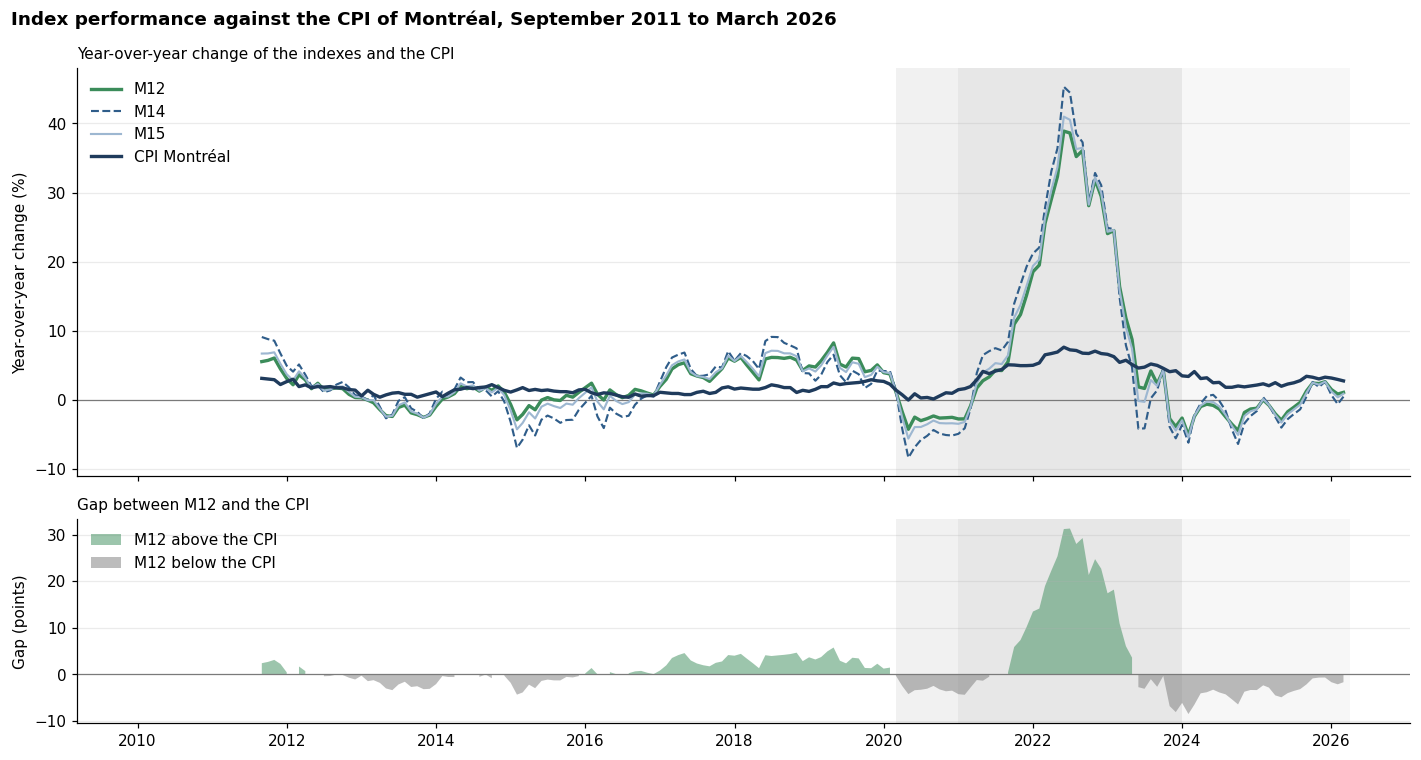

In [33]:
# Plot the year-over-year change of the three indexes against the CPI, and the M12 gap, with regimes shaded
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
idx_styles = {"M12": (COLORS["green"], "-", 2.2), "M14": (COLORS["blue"], "--", 1.4), "M15": (COLORS["light_blue"], "-", 1.4)}
for ax in axes:
    for (regime, (start, end)), shade in zip(REGIMES.items(), [0.0, 0.10, 0.18, 0.06]):
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end) + pd.offsets.MonthEnd(0), color=COLORS["grey"], alpha=shade, lw=0)
    ax.axhline(0, color=COLORS["grey"], linewidth=0.8)
    ax.grid(axis="x", visible=False)

for name, (color, style, width) in idx_styles.items():
    axes[0].plot(ev.index, ev[f"{name} yoy"], label=name, color=color, linestyle=style, linewidth=width)
axes[0].plot(ev.index, ev["cpi_montreal_n_yoy"], label="CPI Montréal", color=COLORS["navy"], linewidth=2.2)
axes[0].set_ylabel("Year-over-year change (%)")
axes[0].set_title("Year-over-year change of the indexes and the CPI", loc="left", fontsize=10)
axes[0].legend(loc="upper left", frameon=False)

gap = ev["M12 yoy"] - ev["cpi_montreal_n_yoy"]
axes[1].fill_between(ev.index, gap, 0, where=gap >= 0, color=COLORS["green"], alpha=0.5, lw=0, label="M12 above the CPI")
axes[1].fill_between(ev.index, gap, 0, where=gap < 0, color=COLORS["grey"], alpha=0.5, lw=0, label="M12 below the CPI")
axes[1].set_ylabel("Gap (points)")
axes[1].set_title("Gap between M12 and the CPI", loc="left", fontsize=10)
axes[1].legend(loc="upper left", frameon=False)

fig.suptitle("Index performance against the CPI of Montréal, September 2011 to March 2026", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

The top panel shows that the three indexes follow the shape of the CPI cycle but with much larger swings. Before 2020 they move around the CPI within a few points, below it during the 2015 to 2016 oil collapse and above it from 2017 to 2019. In 2021 and 2022 they rise to between about 39% (M12) and 45% (M14) a year, while the CPI peaks below 8%. M14, with the most fuel weight, has the widest swings in both directions.

The bottom panel concentrates the story of the gap. M12 runs above the CPI for most of 2017 to 2019 by up to about 5 points, then by up to about 31 points in mid-2022. It runs below the CPI in three periods: the 2015 to 2016 oil collapse, the COVID shock, and from late 2023 onward, when input costs retreat while consumer prices keep rising, by up to about 8 points in early 2024. By early 2026 the gap is close to zero again.

### **4.3 Sensitivity to the March 2026 spike**

The Data Integrity Note keeps the March 2026 diesel spike in full and leaves one question for this chapter: does that extreme month move the index weights? Two checks answer it. M12 is re-estimated without March 2026, and the influence of every month on the model is measured with Cook's distance.

Cook's distance measures how much the whole fitted model changes when one observation is removed. For month $i$:

$$D_i = \frac{\sum_j \left(\hat{y}_j - \hat{y}_{j(i)}\right)^2}{p \cdot s^2}$$

where $\hat{y}_j$ is the fitted CPI for month $j$ with every month in the model, $\hat{y}_{j(i)}$ the same fit without month $i$, $p$ the number of coefficients (3 here, including the intercept) and $s^2$ the residual variance of the model. A month gets a large distance when it combines two things: an unusual combination of inputs (high leverage) and a large error (a big residual). A month that is extreme in only one of the two usually has much less influence.

A common rule of thumb flags months with a distance above $4/n$, which is $4/175 = 0.0229$ here. Months above that level deserve a closer look; they are not errors and are not removed.

In [34]:
# Re-estimate M12 without March 2026, check which fuel month enters that row, and rank months by influence
X = sm.add_constant(reg[["cfi_lag1", "ippi_lag8"]])
row = reg.loc["2026-03-01", ["cfi_n_yoy", "cfi_lag1", "ippi_lag8", "cpi_montreal_n_yoy"]]
print("Regression row of March 2026 (year-over-year %):")
print(row.round(2).to_string())

rows = []
for label, keep in [("All 175 months", reg.index), ("Without March 2026", reg.index[reg.index != "2026-03-01"]),
                    ("Without January to March 2026", reg.index[reg.index < "2026-01-01"])]:
    fit = sm.OLS(y.loc[keep], X.loc[keep]).fit()
    b1, b2 = fit.params["cfi_lag1"], fit.params["ippi_lag8"]
    rows.append([label, len(keep), b1, b2, b1 / (b1 + b2), fit.rsquared])
print("\n", pd.DataFrame(rows, columns=["Sample", "N", "CFI coef", "IPPI coef", "Fuel share", "R2"]).round(4).to_string(index=False))

# Cook's distance: the five most influential months, and the rank of March 2026
cooks = pd.Series(m12.get_influence().cooks_distance[0], index=reg.index)
print(f"\nCook's distance, five most influential months (rule of thumb 4/n = {4 / len(reg):.4f}):")
print(cooks.sort_values(ascending=False).head(5).round(4).to_string())
print(f"March 2026: {cooks.loc['2026-03-01']:.4f}, rank {int(cooks.rank(ascending=False).loc['2026-03-01'])} of {len(cooks)}")

Regression row of March 2026 (year-over-year %):
cfi_n_yoy             24.124614
cfi_lag1              -2.646083
ippi_lag8              1.719198
cpi_montreal_n_yoy     2.769231

                        Sample   N  CFI coef  IPPI coef  Fuel share     R2
               All 175 months 175    0.0244     0.1376      0.1505 0.6247
           Without March 2026 174    0.0244     0.1377      0.1507 0.6260
Without January to March 2026 172    0.0249     0.1375      0.1532 0.6306

Cook's distance, five most influential months (rule of thumb 4/n = 0.0229):
month
2023-07-01    0.0917
2023-06-01    0.0877
2023-08-01    0.0613
2023-04-01    0.0587
2023-05-01    0.0431
March 2026: 0.0014, rank 105 of 175


**Regression Row of March 2026** (year-over-year change)

| Variable | Value |
|----------|-------|
| CFI, March 2026 | +24.12% |
| CFI at lag 1 (used in the model) | -2.65% |
| IPPI at lag 8 (used in the model) | +1.72% |
| CPI Montréal | +2.77% |

**M12 Coefficients With and Without the Last Months**

| Sample | N | CFI coef | IPPI coef | Fuel share | R² |
|--------|---|----------|-----------|------------|----|
| All 175 months | 175 | 0.0244 | 0.1376 | 15.05% | 0.6247 |
| Without March 2026 | 174 | 0.0244 | 0.1377 | 15.07% | 0.6260 |
| Without January to March 2026 | 172 | 0.0249 | 0.1375 | 15.32% | 0.6306 |

**Most Influential Months** (Cook's distance, rule of thumb 4/n = 0.0229)

| Month | Cook's distance |
|-------|-----------------|
| July 2023 | 0.0917 |
| June 2023 | 0.0877 |
| August 2023 | 0.0613 |
| April 2023 | 0.0587 |
| May 2023 | 0.0431 |
| March 2026 | 0.0014 (rank 105 of 175) |

The March 2026 spike does not reach the model. The fuel component enters with a one-month lag, so the March row uses the year-over-year change of the CFI in February (-2.65%), not the one in March (+24.12%). The spike enters the index from April 2026, outside the analysis period. Removing March 2026 changes the fuel share from 15.05% to 15.07%, and removing the first three months of 2026 moves it to 15.32%. The estimated weights are not materially affected by excluding the final month or the first three months of 2026.

The months that weigh most on the model are the spring and summer of 2023, all five above the rule-of-thumb threshold. A likely reason is that the CPI is still rising quickly at the end of the post-COVID surge while the lagged inputs have already turned down, so the model misses those months by the widest margin. March 2026, by contrast, ranks 105th of 175, with a Cook's distance far below the threshold.

### **4.4 Dollar impact**

The trigger simulation translates index movements into price adjustments on the hypothetical contract defined in the Project Constants: a value of \$100M, a standard anticipated inflation of 2.0% a year and a trigger threshold of ±10 percentage points around it.

Every month of the evaluation period is treated as an annual review: the index is compared with its value twelve months earlier, the base of a contract signed one year before. A review one year after the base falls at the start of the second contract year, when the standard inflation already built into the price is 2.0%. The review band is therefore:

**Review Band**

| Limit | Value |
|-------|-------|
| Upper limit | 2.0% + 10 percentage points = +12% |
| Standard inflation | +2.0% |
| Lower limit | 2.0% - 10 percentage points = -8% |

When the year-over-year change of the index falls inside the band, no adjustment applies. When it falls outside, the excess beyond the limit is applied to the contract value: an index change of +16% gives an excess of 4 points and an upward adjustment of \$4M; a change of -10% gives an excess of -2 points and a downward adjustment of \$2M. The CPI of Montréal goes through the same test as a benchmark: it shows what a contract indexed to general inflation would adjust, for comparison with the construction indexes.

Each monthly review stands for a different contract, signed exactly one year earlier. Consecutive reviews share 11 of their 12 reference months, so the same price movement is counted in several of them. A real contract is reviewed once a year, and its adjustment would be a single one of these monthly values. The sum of the monthly adjustments is therefore a measure of how often and how strongly the mechanism activates over the period, not the amount a contract would pay. The simulation is also simplified: each excess is applied to the full contract value, without compounding on previously adjusted values and regardless of the share of contract work completed by each review date, whereas real escalation clauses usually apply to the value of work performed in each period.

In [35]:
# Rolling annual review: each month's year-over-year change against the +12% / -8% band, in dollars on $100M
CONTRACT_VALUE = 100_000_000
UPPER, LOWER = 12.0, -8.0

def triggers(yoy):
    # Excess beyond the band (points) and the resulting adjustment in dollars
    excess = np.where(yoy > UPPER, yoy - UPPER, np.where(yoy < LOWER, yoy - LOWER, 0.0))
    return pd.DataFrame({"yoy": yoy, "excess": excess, "adjustment": excess / 100 * CONTRACT_VALUE}, index=yoy.index)

sim = {name: triggers(ev[f"{name} yoy"]) for name in idx_cols}
sim["CPI Montréal"] = triggers(ev["cpi_montreal_n_yoy"])

rows = []
for name, t in sim.items():
    up, down = t[t["excess"] > 0], t[t["excess"] < 0]
    hit = t[t["excess"] != 0]
    rows.append([name, len(up), len(down), len(hit), len(hit) / len(t) * 100,
                 f"{hit.index.min():%Y-%m}" if len(hit) else "-", f"{hit.index.max():%Y-%m}" if len(hit) else "-",
                 t["excess"].max(), t["adjustment"].sum() / 1e6])
summary = pd.DataFrame(rows, columns=["Series", "Upward", "Downward", "Total", "Share of months (%)",
                                      "First", "Last", "Peak excess (pts)", "Sum of adjustments ($M)"])
print(f"Reviews: {len(ev)} months, {ev.index.min():%Y-%m} to {ev.index.max():%Y-%m}\n")
print(summary.round(2).to_string(index=False))

# Trigger months by regime
print("\nTrigger months by regime:")
print(pd.DataFrame({name: t[t["excess"] != 0].join(ev["regime"])["regime"].value_counts()
                    for name, t in sim.items()}).reindex(list(REGIMES)).fillna(0).astype(int).to_string())

# Monthly detail for M12
cmi_hits = sim["M12"].join(ev["cpi_montreal_n_yoy"])
cmi_hits = cmi_hits[cmi_hits["excess"] != 0]
cmi_hits["adjustment ($M)"] = cmi_hits["adjustment"] / 1e6
cmi_hits.index = cmi_hits.index.strftime("%Y-%m")
print("\nM12 trigger months:")
print(cmi_hits[["yoy", "cpi_montreal_n_yoy", "excess", "adjustment ($M)"]].round(2).to_string())

Reviews: 175 months, 2011-09 to 2026-03

      Series  Upward  Downward  Total  Share of months (%)   First    Last  Peak excess (pts)  Sum of adjustments ($M)
         M12      17         0     17                 9.71 2021-11 2023-03              26.89                   251.76
         M14      18         1     19                10.86 2020-05 2023-03              33.31                   296.64
         M15      17         0     17                 9.71 2021-11 2023-03              28.98                   265.81
CPI Montréal       0         0      0                 0.00       -       -               0.00                     0.00

Trigger months by regime:
                  M12  M14  M15  CPI Montréal
regime                                       
Pre-COVID           0    0    0             0
COVID shock         0    1    0             0
Post-COVID surge   17   18   17             0
Stabilization       0    0    0             0

M12 trigger months:
           yoy  cpi_montreal_n_yoy  exce

**Trigger Simulation Summary (175 monthly reviews, September 2011 to March 2026)**

| Series | Upward | Downward | Total | Share of months | First | Last | Peak excess | Sum of adjustments |
|--------|--------|----------|-------|-----------------|-------|------|-------------|--------------------|
| M12 | 17 | 0 | 17 | 9.7% | Nov 2021 | Mar 2023 | 26.89 pts | \$251.76M |
| M14 | 18 | 1 | 19 | 10.9% | May 2020 | Mar 2023 | 33.31 pts | \$296.64M |
| M15 | 17 | 0 | 17 | 9.7% | Nov 2021 | Mar 2023 | 28.98 pts | \$265.81M |
| CPI Montréal | 0 | 0 | 0 | 0.0% | | | | \$0 |

**Trigger Months by Regime**

| Regime | M12 | M14 | M15 | CPI Montréal |
|--------|-----|-----|-----|--------------|
| Pre-COVID | 0 | 0 | 0 | 0 |
| COVID Shock | 0 | 1 | 0 | 0 |
| Post-COVID surge | 17 | 18 | 17 | 0 |
| Stabilization | 0 | 0 | 0 | 0 |

**M12 Trigger Months**

| Month | M12 change | CPI change | Excess | Adjustment |
|-------|------------|------------|--------|------------|
| Nov 2021 | +12.37% | +4.97% | 0.37 pts | \$0.37M |
| Dec 2021 | +15.20% | +4.98% | 3.20 pts | \$3.20M |
| Jan 2022 | +18.55% | +5.03% | 6.55 pts | \$6.55M |
| Feb 2022 | +19.52% | +5.36% | 7.52 pts | \$7.52M |
| Mar 2022 | +25.54% | +6.54% | 13.54 pts | \$13.54M |
| Apr 2022 | +29.05% | +6.73% | 17.05 pts | \$17.05M |
| May 2022 | +32.34% | +6.94% | 20.34 pts | \$20.34M |
| Jun 2022 | +38.89% | +7.64% | 26.89 pts | \$26.89M |
| Jul 2022 | +38.61% | +7.26% | 26.61 pts | \$26.61M |
| Aug 2022 | +35.20% | +7.16% | 23.20 pts | \$23.20M |
| Sep 2022 | +36.09% | +6.78% | 24.09 pts | \$24.09M |
| Oct 2022 | +28.10% | +6.73% | 16.10 pts | \$16.10M |
| Nov 2022 | +31.86% | +7.07% | 19.86 pts | \$19.86M |
| Dec 2022 | +29.45% | +6.72% | 17.45 pts | \$17.45M |
| Jan 2023 | +24.07% | +6.62% | 12.07 pts | \$12.07M |
| Feb 2023 | +24.51% | +6.28% | 12.51 pts | \$12.51M |
| Mar 2023 | +16.41% | +5.45% | 4.41 pts | \$4.41M |

M12 stays inside the band for 158 of the 175 reviews. It triggers only during the post-COVID surge, in 17 consecutive months from November 2021 to March 2023, always upward. The largest single adjustment comes in June 2022: an index change of 38.89% against a CPI change of 7.64%, an excess of 26.89 points, or \$26.89M on a \$100M contract. A contract tied to the CPI alone never adjusts: its largest annual change, 7.64%, stays below the +12% limit.

The fuel weight changes how often and how far the index crosses the band. M15 triggers in the same 17 months as M12, but produces a higher sum of monthly adjustments and a larger peak excess. M14 adds one more upward month and the only downward trigger of the simulation, in May 2020 (-8.34%, just below the -8% limit), when fuel prices collapse.

### **4.4.1 COVID stress test**

The COVID period is a demanding test for a review band: fuel prices collapse in 2020 while consumer prices barely move, and input costs then surge in 2021. A well-designed index should stay inside the band during the temporary collapse and cross it during the sustained surge. The stress test checks both: the lowest year-over-year change of each index from March 2020 to June 2021, against the lower limit of -8%, and the activation during the post-COVID surge.

In [36]:
# Stress test: trough of each index during the COVID collapse against the -8% limit, and activation in the surge
covid = ev.loc["2020-03-01":"2021-06-01"]
rows = []
for name in idx_cols + ["CPI Montréal"]:
    col = "cpi_montreal_n_yoy" if name == "CPI Montréal" else f"{name} yoy"
    trough, when = covid[col].min(), covid[col].idxmin()
    t = sim[name]
    surge = t.loc["2021-01-01":"2023-12-01"]
    hits = surge[surge["excess"] > 0]
    rows.append([name, trough, f"{when:%Y-%m}", trough - LOWER, "yes" if trough < LOWER else "no",
                 t.loc["2020-03-01":"2021-06-01", "adjustment"].sum() / 1e6,
                 len(hits), f"{hits.index.min():%Y-%m}" if len(hits) else "-", hits["excess"].max() if len(hits) else 0])
stress = pd.DataFrame(rows, columns=["Series", "COVID trough (%)", "Trough month", "Margin to -8% (pts)",
                                     "Lower limit breached", "COVID adjustments ($M)",
                                     "Surge triggers", "First surge trigger", "Peak surge excess (pts)"])
print(stress.round(2).to_string(index=False))

      Series  COVID trough (%) Trough month  Margin to -8% (pts) Lower limit breached  COVID adjustments ($M)  Surge triggers First surge trigger  Peak surge excess (pts)
         M12             -4.22      2020-05                 3.78                   no                    0.00              17             2021-11                    26.89
         M14             -8.34      2020-05                -0.34                  yes                   -0.34              18             2021-10                    33.31
         M15             -5.57      2020-05                 2.43                   no                    0.00              17             2021-11                    28.98
CPI Montréal              0.00      2020-05                 8.00                   no                    0.00               0                   -                     0.00


**COVID Stress Test (March 2020 to June 2021, and the post-COVID surge)**

| Series | COVID trough | Trough month | Margin to -8% | Lower limit breached | COVID adjustments | Surge triggers | First surge trigger | Peak surge excess |
|--------|--------------|--------------|---------------|----------------------|-------------------|----------------|---------------------|-------------------|
| M12 | -4.22% | May 2020 | 3.78 pts | No | \$0 | 17 | Nov 2021 | 26.89 pts |
| M14 | -8.34% | May 2020 | -0.34 pts | Yes | -\$0.34M | 18 | Oct 2021 | 33.31 pts |
| M15 | -5.57% | May 2020 | 2.43 pts | No | \$0 | 17 | Nov 2021 | 28.98 pts |
| CPI Montréal | 0.00% | May 2020 | 8.00 pts | No | \$0 | 0 | | 0 |

**Stress Test Verdict**

| Test | M12 | M14 | M15 |
|------|-----|-----|-----|
| Stays inside the band during the COVID collapse | Pass | Fail (by 0.34 pts) | Pass |
| Crosses the band during the post-COVID surge | Pass | Pass | Pass |

All three indexes reach their lowest point in May 2020, when the collapse of fuel prices is fully reflected in the year-over-year change. M12 falls to -4.22%, keeping 3.78 points of margin above the lower limit, so the band absorbs the temporary shock without any adjustment. M15 keeps a smaller margin of 2.43 points. M14, with the most fuel weight, falls just below the limit (-8.34%) and triggers a small downward adjustment of \$0.34M on a temporary shock that reverses within months.

During the surge, every index crosses the band for a sustained period: from November 2021 for M12 and M15, and one month earlier for M14. M12 and M15 meet both conditions of a well-behaved escalation index: they stay quiet through a temporary commodity shock and respond to sustained cost escalation. M12 does so with the wider margin.

**COVID stress test chart**

The three panels follow the stress test from June 2019 to June 2022: the normalized input series and the CPI, the year-over-year change of the indexes against the review band, and the excess of each index beyond the band.

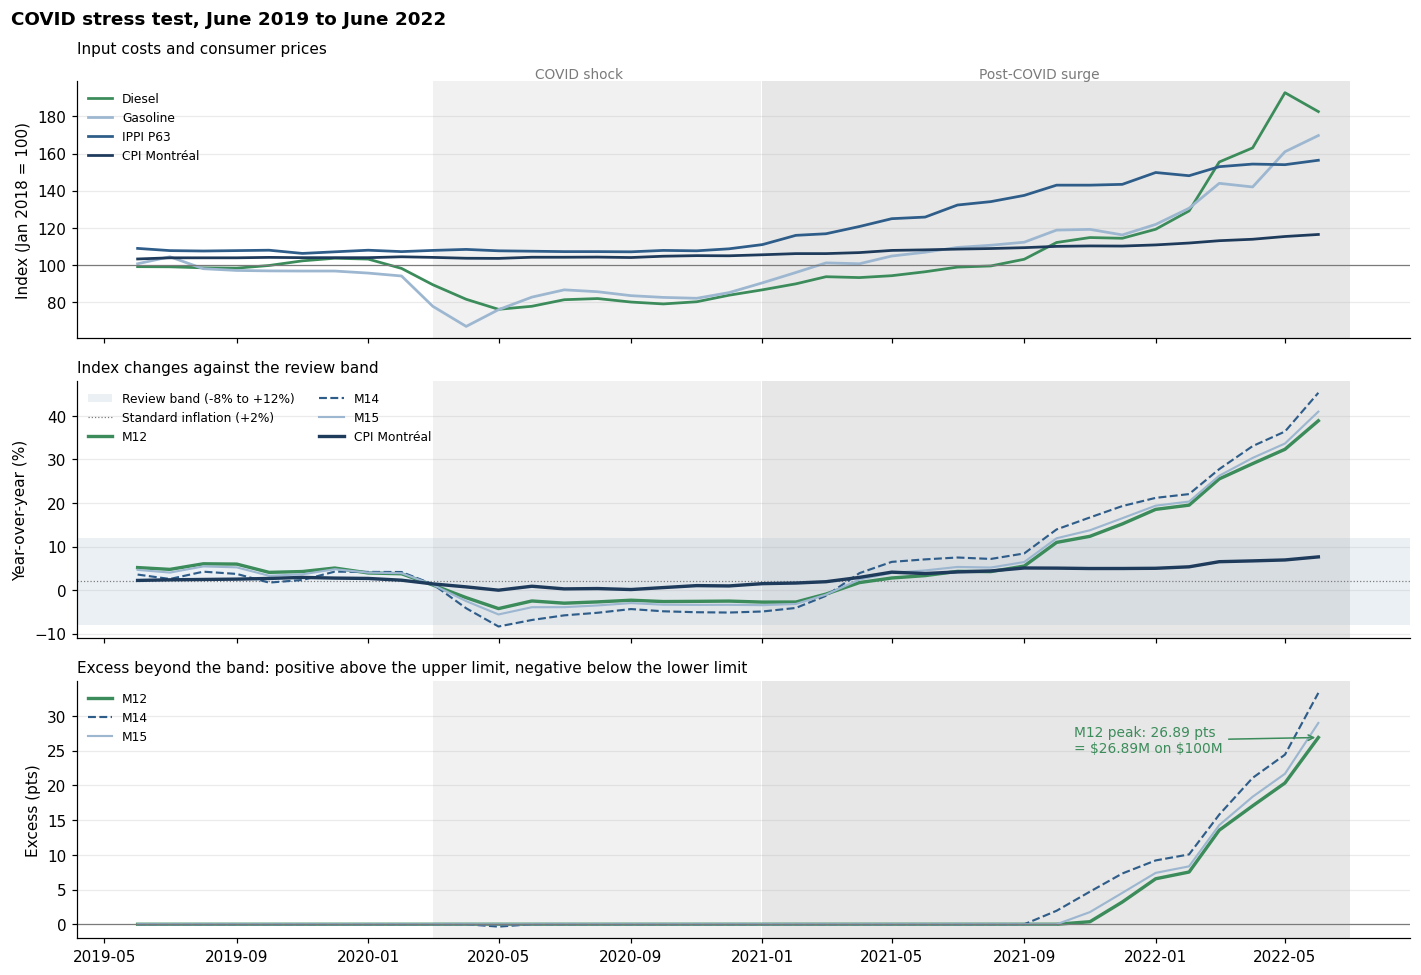

In [37]:
# COVID stress test chart: input levels, index changes against the band, and excess beyond the band
win = master.set_index("month").loc["2019-06-01":"2022-06-01"]
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax in axes:
    for regime, shade in [("COVID shock", 0.10), ("Post-COVID surge", 0.18)]:
        start, end = REGIMES[regime]
        ax.axvspan(pd.Timestamp(start), min(pd.Timestamp(end), win.index.max()) + pd.offsets.MonthEnd(0),
                   color=COLORS["grey"], alpha=shade, lw=0)
    ax.grid(axis="x", visible=False)
axes[0].text(pd.Timestamp("2020-07-15"), 1.01, "COVID shock", transform=axes[0].get_xaxis_transform(),
             ha="center", fontsize=9, color=COLORS["grey"])
axes[0].text(pd.Timestamp("2021-09-15"), 1.01, "Post-COVID surge", transform=axes[0].get_xaxis_transform(),
             ha="center", fontsize=9, color=COLORS["grey"])

# Panel 1: normalized input series and CPI
for col, label, color, style in [("diesel_n", "Diesel", COLORS["green"], "-"), ("gasoline_n", "Gasoline", COLORS["light_blue"], "-"),
                                 ("ippi_p63_n", "IPPI P63", COLORS["blue"], "-"), ("cpi_montreal_n", "CPI Montréal", COLORS["navy"], "-")]:
    axes[0].plot(win.index, win[col], label=label, color=color, linestyle=style, linewidth=1.8)
axes[0].axhline(100, color=COLORS["grey"], linewidth=0.8)
axes[0].set_ylabel("Index (Jan 2018 = 100)")
axes[0].set_title("Input costs and consumer prices", loc="left", fontsize=10, pad=18)
axes[0].legend(loc="upper left", frameon=False, fontsize=8)

# Panel 2: year-over-year change of the indexes against the band
axes[1].axhspan(LOWER, UPPER, color=COLORS["light_blue"], alpha=0.2, lw=0, label="Review band (-8% to +12%)")
axes[1].axhline(2.0, color=COLORS["grey"], linewidth=0.8, linestyle=":", label="Standard inflation (+2%)")
for name, (color, style, width) in idx_styles.items():
    axes[1].plot(win.index, win[f"{name} yoy"], label=name, color=color, linestyle=style, linewidth=width)
axes[1].plot(win.index, win["cpi_montreal_n_yoy"], label="CPI Montréal", color=COLORS["navy"], linewidth=2.2)
axes[1].set_ylabel("Year-over-year (%)")
axes[1].set_title("Index changes against the review band", loc="left", fontsize=10)
axes[1].legend(loc="upper left", frameon=False, fontsize=8, ncol=2)

# Panel 3: excess beyond the band
for name, (color, style, width) in idx_styles.items():
    exc = sim[name]["excess"].loc[win.index.min():win.index.max()]
    axes[2].plot(exc.index, exc, label=name, color=color, linestyle=style, linewidth=width)
axes[2].axhline(0, color=COLORS["grey"], linewidth=0.8)
peak = sim["M12"]["excess"].loc[:win.index.max()]
axes[2].annotate(f"M12 peak: {peak.max():.2f} pts\n= \\${peak.max():.2f}M on \\$100M", (peak.idxmax(), peak.max()),
                 xytext=(-160, -10), textcoords="offset points", fontsize=9, color=COLORS["green"],
                 arrowprops=dict(arrowstyle="->", color=COLORS["green"]))
axes[2].set_ylabel("Excess (pts)")
axes[2].set_title("Excess beyond the band: positive above the upper limit, negative below the lower limit", loc="left", fontsize=10)
axes[2].legend(loc="upper left", frameon=False, fontsize=8)

fig.suptitle("COVID stress test, June 2019 to June 2022", x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

The top panel shows the shock at its source. Fuel prices collapse in the spring of 2020, gasoline below 70 and diesel to about 76, while the IPPI and the CPI barely move. From 2021, the IPPI climbs steadily and fuel recovers, then surges in 2022, with diesel above 190 by May.

The middle panel shows how the band handles both phases. During the collapse, M12 and M15 dip below zero but stay inside the band; only M14 crosses the lower limit, slightly, in May 2020. During the surge, the indexes cross the upper limit in late 2021 and keep rising, while the CPI stays inside the band throughout.

The bottom panel shows the result in adjustment terms: almost nothing during the collapse, then a growing excess from late 2021, reaching 26.89 points for M12 by June 2022, or \$26.89M on the \$100M contract.

### **4.4.2 Trigger simulation chart**

The top panel shows the year-over-year change of the three indexes against the review band, with the trigger months of M12 marked. The middle panel shows the monthly adjustment of M12 on the \$100M contract, and the bottom panel the yearly sum of adjustments for each index.

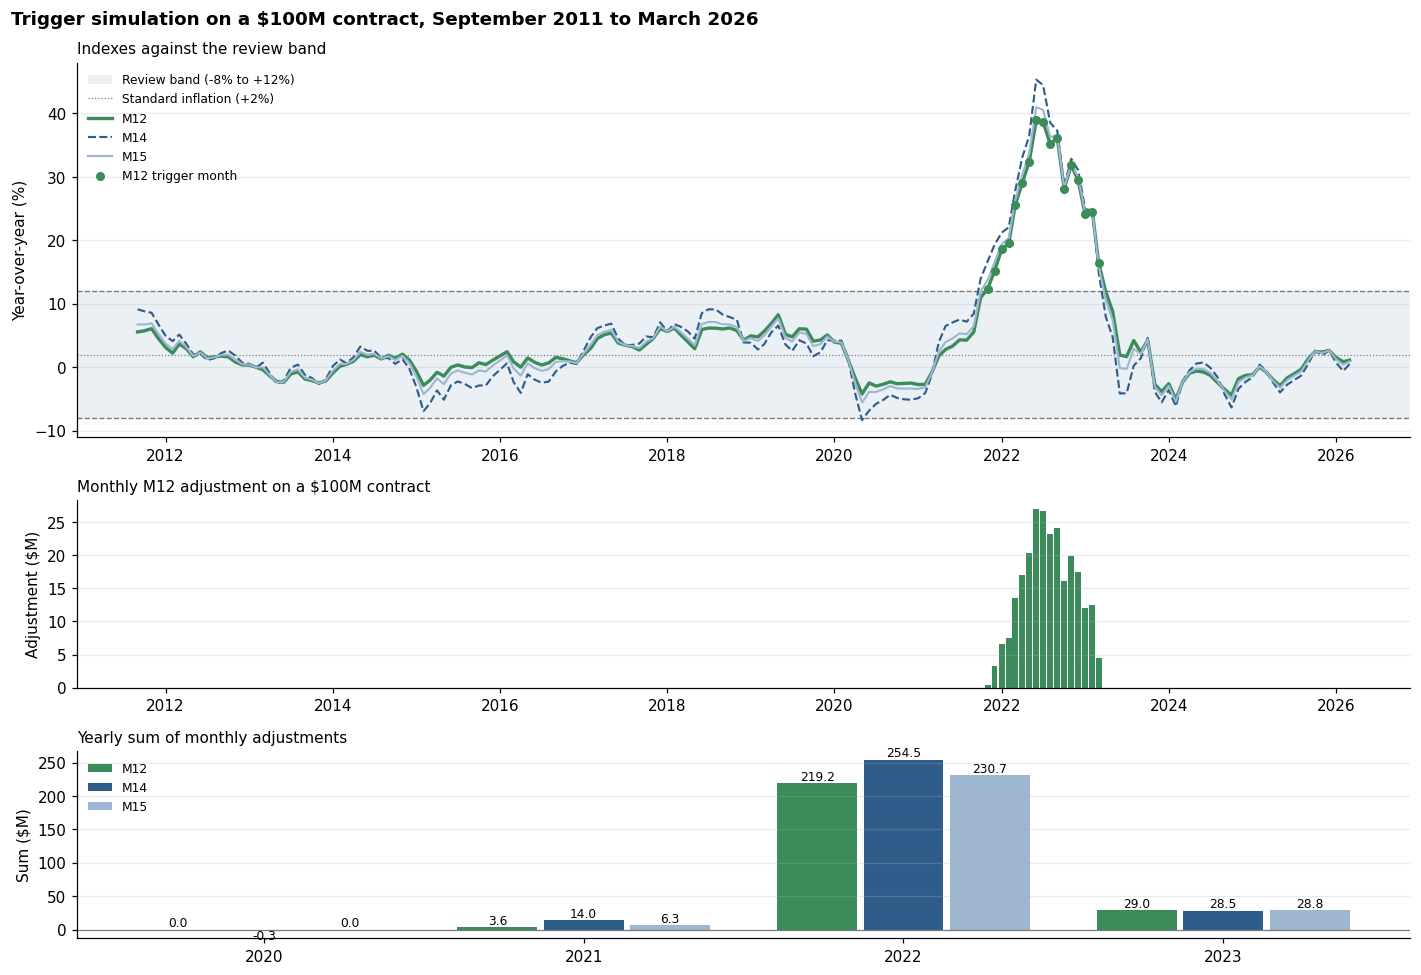

In [38]:
# Indexes against the band, monthly M12 adjustments and yearly adjustment sums by index
fig, axes = plt.subplots(3, 1, figsize=(13, 9), gridspec_kw={"height_ratios": [2, 1, 1]})

# Top panel: year-over-year change against the band
ax = axes[0]
ax.axhspan(LOWER, UPPER, color=COLORS["light_blue"], alpha=0.2, lw=0, label="Review band (-8% to +12%)")
ax.axhline(UPPER, color=COLORS["grey"], linewidth=0.9, linestyle="--")
ax.axhline(LOWER, color=COLORS["grey"], linewidth=0.9, linestyle="--")
ax.axhline(2.0, color=COLORS["grey"], linewidth=0.8, linestyle=":", label="Standard inflation (+2%)")
for name, (color, style, width) in idx_styles.items():
    ax.plot(ev.index, ev[f"{name} yoy"], label=name, color=color, linestyle=style, linewidth=width)
cmi_trig = sim["M12"][sim["M12"]["excess"] != 0]
ax.scatter(cmi_trig.index, cmi_trig["yoy"], s=24, color=COLORS["green"], zorder=3, label="M12 trigger month")
ax.set_ylabel("Year-over-year (%)")
ax.set_title("Indexes against the review band", loc="left", fontsize=10)
ax.legend(loc="upper left", frameon=False, fontsize=8)
ax.grid(axis="x", visible=False)

# Middle panel: monthly M12 adjustment in millions of dollars
ax = axes[1]
adj = sim["M12"]["adjustment"] / 1e6
ax.bar(adj.index, adj, width=25, color=np.where(adj >= 0, COLORS["green"], COLORS["grey"]))
ax.set_xlim(axes[0].get_xlim())
ax.set_ylabel("Adjustment ($M)")
ax.set_title("Monthly M12 adjustment on a $100M contract", loc="left", fontsize=10)
ax.grid(axis="x", visible=False)

# Bottom panel: yearly sum of adjustments by index
ax = axes[2]
yearly = pd.DataFrame({name: sim[name]["adjustment"].groupby(sim[name].index.year).sum() / 1e6 for name in idx_cols})
yearly = yearly.loc[(yearly != 0).any(axis=1)]
x = np.arange(len(yearly))
for k, (name, (color, _, _)) in enumerate(idx_styles.items()):
    bars = ax.bar(x + (k - 1) * 0.27, yearly[name], 0.25, color=color, label=name)
    for b, v in zip(bars, yearly[name]):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.1f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=8)
ax.axhline(0, color=COLORS["grey"], linewidth=0.8)
ax.set_xticks(x, yearly.index)
ax.set_ylabel("Sum ($M)")
ax.set_title("Yearly sum of monthly adjustments", loc="left", fontsize=10)
ax.legend(loc="upper left", frameon=False, fontsize=8)
ax.grid(axis="x", visible=False)

fig.suptitle("Trigger simulation on a $100M contract, September 2011 to March 2026", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

**Yearly Sum of Monthly Adjustments (\$M)**

| Year | M12 | M14 | M15 |
|------|-----|-----|-----|
| 2020 | 0.0 | -0.3 | 0.0 |
| 2021 | 3.6 | 14.0 | 6.3 |
| 2022 | 219.2 | 254.5 | 230.7 |
| 2023 | 29.0 | 28.5 | 28.8 |
| Total | 251.8 | 296.6 | 265.8 |

The top panel shows how rarely the indexes leave the band: over fourteen and a half years, M12 stays inside it except for one continuous episode, the post-COVID surge, marked by its trigger months from late 2021 to early 2023. The swings of 2015, 2020 and 2024, all below zero, stay inside the lower limit for M12 and M15.

The middle panel shows that the adjustments build up and fade gradually: they grow through the first half of 2022, peak at \$26.89M in June, and shrink to \$4.41M by March 2023. The bottom panel puts 2022 in perspective: it concentrates 87% of the M12 adjustments (\$219.2M of \$251.8M). M14 generates the most adjustment in 2021 and 2022, when fuel prices rise fastest, but slightly less than M12 in 2023, when fuel is already falling and the IPPI is still high.

### **Implications for cost control**

- **The index stays quiet in normal markets and responds in a surge.** Over 175 monthly reviews, M12 stays inside the review band in 158. It triggers only during the post-COVID surge, in 17 consecutive months, while a CPI-based index never triggers. This is the behavior an escalation index needs: no adjustment for ordinary movements, a clear response to sustained escalation.
- **The band absorbs temporary shocks.** During the COVID collapse, M12 falls to -4.22%, with 3.78 points of margin above the lower limit, so no downward adjustment applies on a shock that reverses within months.
- **The index diverges from the CPI by design.** It shows its strongest correlation with the CPI during the surge (0.88) but rises 9 points a year above it on average. A large gap with the CPI during an escalation episode is the reason to use an input cost index, not a flaw.
- **More fuel weight means more adjustment and more noise.** M14 generates \$45M more adjustment activity than M12 over the period and adds one more upward month, but it is also the only index that triggers a downward adjustment on the temporary COVID shock. M15 sits close to M12 and also passes the COVID stress test.
- **The March 2026 spike does not affect the estimated weights.** The spike enters the index only from April 2026, through the one-month fuel lag. Excluding March 2026 changes the fuel share from 15.05% to 15.07%, and excluding January to March 2026 moves it to 15.32%. Its effect on the index is tested out of sample in Chapter 5.

# **Chapter 5: Out-of-sample backtest**

This chapter tests the model and the three candidate indexes on months they have never seen. The weights and lags are fixed with data up to March 2026; Statistics Canada has since published fuel prices and the CPI up to October 2026, and the IPPI up to September 2026. These months show how the frozen model predicts the CPI, how the indexes behave during the 2026 fuel spike, and whether a contract priced in early 2026 would already be outside its first-year band. Because the indexes use lagged inputs, their value for November 2026 can also be computed before the CPI for that month is published.

### **5.1 Out-of-sample data**

The out-of-sample period runs from April 2026 to the latest published month. Thanks to the lags, the index needs less recent data than the CPI: its value for any month uses the fuel prices of the previous month and the IPPI of eight months earlier. The table checks which inputs are available for each month from April to November 2026.

In [39]:
# Out-of-sample months: published values and the reference months each index value needs
oos_months = pd.date_range("2026-04-01", "2026-11-01", freq="MS")
m = master.set_index("month")
rows = []
for month in oos_months:
    fuel_ref, ippi_ref = month - pd.DateOffset(months=1), month - pd.DateOffset(months=8)
    cfi_val = m["cfi_n"].get(fuel_ref, np.nan)
    ippi_val = m["ippi_p63_n"].get(ippi_ref, np.nan)
    cpi_val = m["cpi_montreal_n_yoy"].get(month, np.nan)
    rows.append([f"{month:%Y-%m}", f"{fuel_ref:%Y-%m}", round(cfi_val, 2), f"{ippi_ref:%Y-%m}", round(ippi_val, 2),
                 "yes" if not np.isnan(cfi_val) and not np.isnan(ippi_val) else "no",
                 round(cpi_val, 2) if not np.isnan(cpi_val) else "not yet published"])
avail = pd.DataFrame(rows, columns=["Month", "Fuel reference", "CFI (normalized)", "IPPI reference",
                                    "IPPI (normalized)", "Index computable", "CPI year-over-year (%)"])
print(avail.to_string(index=False))

  Month Fuel reference  CFI (normalized) IPPI reference  IPPI (normalized) Index computable CPI year-over-year (%)
2026-04        2026-03            164.62        2025-08             153.89              yes                   2.82
2026-05        2026-04            170.30        2025-09             155.72              yes                   3.42
2026-06        2026-05            171.28        2025-10             157.02              yes                   3.11
2026-07        2026-06            156.67        2025-11             157.88              yes                   3.35
2026-08        2026-07            166.27        2025-12             157.99              yes                   3.03
2026-09        2026-08            172.92        2026-01             158.32              yes                   3.02
2026-10        2026-09            190.15        2026-02             157.99              yes                   3.37
2026-11        2026-10            189.96        2026-03             159.61      

**Out-of-Sample Months and Their Inputs**

| Month | Fuel reference | CFI (normalized) | IPPI reference | IPPI (normalized) | Index computable | CPI year-over-year |
|-------|----------------|------------------|----------------|-------------------|------------------|--------------------|
| Apr 2026 | Mar 2026 | 164.62 | Aug 2025 | 153.89 | Yes | +2.82% |
| May 2026 | Apr 2026 | 170.30 | Sep 2025 | 155.72 | Yes | +3.42% |
| Jun 2026 | May 2026 | 171.28 | Oct 2025 | 157.02 | Yes | +3.11% |
| Jul 2026 | Jun 2026 | 156.67 | Nov 2025 | 157.88 | Yes | +3.35% |
| Aug 2026 | Jul 2026 | 166.27 | Dec 2025 | 157.99 | Yes | +3.03% |
| Sep 2026 | Aug 2026 | 172.92 | Jan 2026 | 158.32 | Yes | +3.02% |
| Oct 2026 | Sep 2026 | 190.15 | Feb 2026 | 157.99 | Yes | +3.37% |
| Nov 2026 | Oct 2026 | 189.96 | Mar 2026 | 159.61 | Yes | Not yet published |

The indexes can be computed for all eight months, including November 2026, whose CPI is not yet published: their inputs are the fuel prices of October 2026 and the IPPI of March 2026. The two components move very differently. The fuel component rises from 164.62 to about 190, carrying the 2026 spike, while the lagged IPPI stays almost flat, between 153.89 and 159.61, because it still reflects the calm months of late 2025 and early 2026. Over the same period, the CPI of Montréal grows between 2.82% and 3.42% a year.

### **5.2 Forecast versus actual**

The M12 regression estimated on data up to March 2026 is applied, without any change, to the out-of-sample months:

$$\widehat{\Delta\text{CPI}}_t = 1.7385 + 0.0244 \times \Delta\text{CFI}_{t-1} + 0.1376 \times \Delta\text{IPPI}_{t-8}$$

Each forecast is compared with the published CPI. A 95% prediction interval shows the range the model expected, and a simple benchmark gives a reference point: the last CPI change known when the model was frozen (March 2026), carried forward unchanged. A model worth using should at least beat that benchmark.

In [40]:
# Frozen M12 forecast of the CPI for the out-of-sample months, with 95% intervals, errors and a naive benchmark
fc = master.set_index("month").copy()
fc["cfi_lag1"] = fc["cfi_n_yoy"].shift(1)
fc["ippi_lag8"] = fc["ippi_p63_n_yoy"].shift(8)
oos = fc.loc["2026-04-01":"2026-10-01", ["cfi_lag1", "ippi_lag8", "cpi_montreal_n_yoy"]].copy()

pred = m12.get_prediction(sm.add_constant(oos[["cfi_lag1", "ippi_lag8"]], has_constant="add")).summary_frame(alpha=0.05)
oos["forecast"] = pred["mean"].values
oos["lower 95%"] = pred["obs_ci_lower"].values
oos["upper 95%"] = pred["obs_ci_upper"].values
oos["error"] = oos["cpi_montreal_n_yoy"] - oos["forecast"]
oos["naive"] = fc.loc["2026-03-01", "cpi_montreal_n_yoy"]
oos["naive error"] = oos["cpi_montreal_n_yoy"] - oos["naive"]
oos["inside interval"] = oos["cpi_montreal_n_yoy"].between(oos["lower 95%"], oos["upper 95%"])

show = oos.copy()
show.index = show.index.strftime("%Y-%m")
print(show[["cfi_lag1", "ippi_lag8", "forecast", "lower 95%", "upper 95%", "cpi_montreal_n_yoy", "error",
            "inside interval"]].round(2).to_string())

# Error summary: model against the naive benchmark
summary = pd.DataFrame({
    "MAE": [oos["error"].abs().mean(), oos["naive error"].abs().mean()],
    "RMSE": [np.sqrt((oos["error"] ** 2).mean()), np.sqrt((oos["naive error"] ** 2).mean())],
    "Mean error (bias)": [oos["error"].mean(), oos["naive error"].mean()]},
    index=["Frozen M12", "Naive (March 2026 carried forward)"])
print("\nOut-of-sample error summary (percentage points, 7 months):")
print(summary.round(3).to_string())
print(f"\nIn-sample RMSE of M12: {np.sqrt(m12.ssr / m12.nobs):.3f}")
print(f"Months inside the 95% interval: {oos['inside interval'].sum()} of {len(oos)}")

         cfi_lag1  ippi_lag8  forecast  lower 95%  upper 95%  cpi_montreal_n_yoy  error  inside interval
month                                                                                                   
2026-04     24.12       1.93      2.59       0.44       4.74                2.82   0.23             True
2026-05     31.83       3.97      3.06       0.91       5.22                3.42   0.36             True
2026-06     33.93       4.23      3.15       0.99       5.31                3.11  -0.03             True
2026-07     23.00       4.95      2.98       0.84       5.12                3.35   0.36             True
2026-08     28.17       4.43      3.03       0.89       5.18                3.03  -0.00             True
2026-09     33.86       3.02      2.98       0.82       5.14                3.02   0.04             True
2026-10     45.52       2.88      3.25       1.06       5.43                3.37   0.13             True

Out-of-sample error summary (percentage points, 7 mont

**Frozen M12 Forecast Against the Published CPI** (year-over-year change, %)

| Month | CFI at lag 1 | IPPI at lag 8 | Forecast | 95% interval | Actual CPI | Error |
|-------|--------------|---------------|----------|--------------|------------|-------|
| Apr 2026 | +24.12 | +1.93 | 2.59 | 0.44 to 4.74 | 2.82 | +0.23 |
| May 2026 | +31.83 | +3.97 | 3.06 | 0.91 to 5.22 | 3.42 | +0.36 |
| Jun 2026 | +33.93 | +4.23 | 3.15 | 0.99 to 5.31 | 3.11 | -0.03 |
| Jul 2026 | +23.00 | +4.95 | 2.98 | 0.84 to 5.12 | 3.35 | +0.36 |
| Aug 2026 | +28.17 | +4.43 | 3.03 | 0.89 to 5.18 | 3.03 | 0.00 |
| Sep 2026 | +33.86 | +3.02 | 2.98 | 0.82 to 5.14 | 3.02 | +0.04 |
| Oct 2026 | +45.52 | +2.88 | 3.25 | 1.06 to 5.43 | 3.37 | +0.13 |

**Out-of-Sample Error Summary** (percentage points, 7 months)

| Model | MAE | RMSE | Mean error |
|-------|-----|------|------------|
| Frozen M12 | 0.165 | 0.218 | +0.155 |
| Naive benchmark (March 2026 carried forward) | 0.392 | 0.443 | +0.392 |
| M12, in-sample RMSE (for reference) | | 1.067 | |

The frozen model tracks the CPI closely in the seven months it never saw. Its forecasts stay between 2.59% and 3.25%, against actual values between 2.82% and 3.42%, and every actual value falls inside the 95% interval. The out-of-sample RMSE is 0.218 points, about half that of the naive benchmark (0.443) and far below the in-sample RMSE of 1.067. The mean error of +0.155 points shows a slight tendency to underpredict.

Two cautions apply. Seven months is a short test, and the CPI moves within a narrow range during this period, a much easier condition than the post-COVID surge that drives the in-sample error. The 95% intervals are also wide, about 4.3 points, so falling inside them is a modest requirement. The result shows that the model does not break on new data, including months when fuel prices rise 23% to 46% a year; it does not yet show how it would perform in a new inflation surge.

### **5.3 The indexes in 2026**

The three candidate indexes are extended to November 2026 with the published inputs. Their levels and year-over-year changes show how the 2026 fuel spike passes into each index, and a decomposition separates the contribution of fuel and of the IPPI to the change since March 2026, the last month of the analysis period.

In [41]:
# Extend the indexes to November 2026 and decompose their change since March 2026 into fuel and IPPI
ext = master.set_index("month")[["cfi_n", "ippi_p63_n"]].reindex(pd.date_range("2010-01-01", "2026-11-01", freq="MS"))
ext["cfi_lag1_n"] = ext["cfi_n"].shift(1)
ext["ippi_lag8_n"] = ext["ippi_p63_n"].shift(8)
labels_2026 = {"M12": "M12", "M14": "M14", "M15": "M15"}
for name, (w_cfi, w_ippi) in INDEXES.items():
    lab = labels_2026[name]
    ext[lab] = w_cfi * ext["cfi_lag1_n"] + w_ippi * ext["ippi_lag8_n"]
    ext[f"{lab} yoy"] = ext[lab].pct_change(12, fill_method=None) * 100
labs = list(labels_2026.values())

print("Index levels, March to November 2026 (January 2018 = 100 for each component):")
print(ext.loc["2026-03-01":"2026-11-01", labs].round(2).set_axis(ext.loc["2026-03-01":"2026-11-01"].index.strftime("%Y-%m")).to_string())
print("\nYear-over-year change, March to November 2026 (%):")
print(ext.loc["2026-03-01":"2026-11-01", [f"{l} yoy" for l in labs]].round(2).set_axis(ext.loc["2026-03-01":"2026-11-01"].index.strftime("%Y-%m")).to_string())

# Change from March to November 2026, split into the fuel and IPPI contributions
rows = []
for name, (w_cfi, w_ippi) in INDEXES.items():
    lab = labels_2026[name]
    start, end = ext.loc["2026-03-01"], ext.loc["2026-11-01"]
    fuel = w_cfi * (end["cfi_lag1_n"] - start["cfi_lag1_n"])
    ippi = w_ippi * (end["ippi_lag8_n"] - start["ippi_lag8_n"])
    rows.append([lab, start[lab], end[lab], (end[lab] / start[lab] - 1) * 100, fuel, ippi])
decomp = pd.DataFrame(rows, columns=["Index", "March 2026", "November 2026", "Change (%)",
                                     "Fuel contribution (pts)", "IPPI contribution (pts)"])
print("\nChange from March to November 2026:")
print(decomp.round(2).to_string(index=False))

Index levels, March to November 2026 (January 2018 = 100 for each component):
            M12     M14     M15
2026-03  150.44  147.58  149.50
2026-04  155.51  157.11  156.03
2026-05  157.92  160.10  158.64
2026-06  159.17  161.30  159.87
2026-07  157.70  157.52  157.64
2026-08  159.24  160.47  159.65
2026-09  160.52  162.70  161.24
2026-10  162.85  167.64  164.42
2026-11  164.19  168.72  165.68

Year-over-year change, March to November 2026 (%):
         M12 yoy  M14 yoy  M15 yoy
2026-03     1.11     0.49     0.91
2026-04     4.93     8.00     5.93
2026-05     7.67    11.49     8.91
2026-06     8.13    12.15     9.43
2026-07     7.32     9.76     8.11
2026-08     7.57    10.81     8.62
2026-09     7.03    11.19     8.38
2026-10     8.49    14.28    10.36
2026-11     9.12    15.28    11.11

Change from March to November 2026:
Index  March 2026  November 2026  Change (%)  Fuel contribution (pts)  IPPI contribution (pts)
  M12      150.44         164.19        9.14                     8.4

**Index Levels, March to November 2026** (January 2018 = 100 for each component)

| Month | M12 | M14 | M15 |
|-------|-----|-----|-----|
| Mar 2026 | 150.44 | 147.58 | 149.50 |
| Apr 2026 | 155.51 | 157.11 | 156.03 |
| May 2026 | 157.92 | 160.10 | 158.64 |
| Jun 2026 | 159.17 | 161.30 | 159.87 |
| Jul 2026 | 157.70 | 157.52 | 157.64 |
| Aug 2026 | 159.24 | 160.47 | 159.65 |
| Sep 2026 | 160.52 | 162.70 | 161.24 |
| Oct 2026 | 162.85 | 167.64 | 164.42 |
| Nov 2026 | 164.19 | 168.72 | 165.68 |

**Year-over-Year Change, March to November 2026 (%)**

| Month | M12 | M14 | M15 |
|-------|-----|-----|-----|
| Mar 2026 | +1.11 | +0.49 | +0.91 |
| Apr 2026 | +4.93 | +8.00 | +5.93 |
| May 2026 | +7.67 | +11.49 | +8.91 |
| Jun 2026 | +8.13 | +12.15 | +9.43 |
| Jul 2026 | +7.32 | +9.76 | +8.11 |
| Aug 2026 | +7.57 | +10.81 | +8.62 |
| Sep 2026 | +7.03 | +11.19 | +8.38 |
| Oct 2026 | +8.49 | +14.28 | +10.36 |
| Nov 2026 | +9.12 | +15.28 | +11.11 |

**Change from March to November 2026, by Component**

| Index | March 2026 | November 2026 | Change | Fuel contribution | IPPI contribution | Fuel share of the change |
|-------|------------|---------------|--------|-------------------|-------------------|--------------------------|
| M12 | 150.44 | 164.19 | +9.14% | 8.43 pts | 5.32 pts | 61% |
| M14 | 147.58 | 168.72 | +14.32% | 16.75 pts | 4.38 pts | 79% |
| M15 | 149.50 | 165.68 | +10.82% | 11.17 pts | 5.01 pts | 69% |

The fuel spike enters the indexes in April 2026, one month after it happens, and their year-over-year change jumps from about 1% in March to between 4.93% and 8.00% in April. By November 2026, M12 grows 9.12% a year, M15 11.11% and M14 15.28%. The November CPI is not yet published; against the latest published change (3.37% in October), these rates are about 2.7 to 4.5 times as high.

Fuel drives most of the rise. Even in M12, where it weighs 15.1%, it accounts for 61% of the increase since March, because fuel prices rise far more than the IPPI. In M14, with twice the fuel weight, the share reaches 79%. The IPPI adds a steadier 4 to 5 points in all three. Its contribution should grow only slightly in the coming months: the IPPI published for mid-2026, which the index will use with its 8-month lag, is only a little above its March level.

### **5.4 Trigger simulation, April to November 2026**

Two tests show what the 2026 fuel spike would mean for the hypothetical \$100M contract. They answer different questions, so their results differ.

**Test 1: rolling annual review.** Each month asks: would a contract signed exactly one year earlier be due an adjustment today? The index is compared with its value twelve months before, against the band of +12% and -8% used in section 4.4 (at the first anniversary, the 2% standard inflation already applies). Because the index uses lagged inputs, the test runs through November 2026, before the CPI for that month is published.

**Test 2: a single contract with a base date of February 2026.** One contract is priced in February 2026, just before the fuel spike. Its base value is fixed with the formula of section 4.1, and each later month measures the cumulative change from that base. In the first contract year, no standard inflation has accrued yet, so the band is ±10% around zero. The formal review takes place on the first anniversary, in February 2027; the monthly values show where the contract is heading, not an adjustment already due.

**Why the two tests differ.** The single contract has a tighter limit (+10% instead of +12%) and a base set just before the spike, so it captures the full rise in prices. The rolling review compares each month with the same month a year earlier, when prices were already somewhat higher. The same market movement can therefore trigger one contract and not another, depending on when its base was fixed.

In [42]:
# Rolling annual review for April to November 2026, and a single contract with a base date of February 2026
rows = []
for lab in labs:
    t = triggers(ext.loc["2026-04-01":"2026-11-01", f"{lab} yoy"])
    for month, r in t.iterrows():
        rows.append([f"{month:%Y-%m}", lab, r["yoy"], r["excess"], r["adjustment"] / 1e6])
roll26 = pd.DataFrame(rows, columns=["Month", "Index", "YoY (%)", "Excess (pts)", "Adjustment ($M)"])
print("Rolling annual review, band +12% / -8%:")
print(roll26.pivot(index="Month", columns="Index", values="YoY (%)").round(2).to_string())
print("\nExcess beyond the band (pts):")
print(roll26.pivot(index="Month", columns="Index", values="Excess (pts)").round(2).to_string())
print("\nTrigger months and sum of adjustments, April to November 2026:")
print(roll26.groupby("Index").agg(triggers=("Excess (pts)", lambda s: int((s != 0).sum())),
                                  sum_adjustment_M=("Adjustment ($M)", "sum")).round(2).to_string())

# Single contract with a base date of February 2026: cumulative change against the first-year band of ±10%
base = ext.loc["2026-02-01", labs]
contract = (ext.loc["2026-03-01":"2026-11-01", labs] / base - 1) * 100
contract.index = contract.index.strftime("%Y-%m")
print(f"\nBase values, February 2026: " + ", ".join(f"{l} {base[l]:.2f}" for l in labs))
print("Cumulative change since February 2026 (%), first-year band -10% to +10%:")
print(contract.round(2).to_string())

Rolling annual review, band +12% / -8%:
Index     M12    M14    M15
Month                      
2026-04  4.93   8.00   5.93
2026-05  7.67  11.49   8.91
2026-06  8.13  12.15   9.43
2026-07  7.32   9.76   8.11
2026-08  7.57  10.81   8.62
2026-09  7.03  11.19   8.38
2026-10  8.49  14.28  10.36
2026-11  9.12  15.28  11.11

Excess beyond the band (pts):
Index    M12   M14  M15
Month                  
2026-04  0.0  0.00  0.0
2026-05  0.0  0.00  0.0
2026-06  0.0  0.15  0.0
2026-07  0.0  0.00  0.0
2026-08  0.0  0.00  0.0
2026-09  0.0  0.00  0.0
2026-10  0.0  2.28  0.0
2026-11  0.0  3.28  0.0

Trigger months and sum of adjustments, April to November 2026:
       triggers  sum_adjustment_M
Index                            
M12           0              0.00
M14           3              5.72
M15           0              0.00

Base values, February 2026: M12 149.04, M14 145.12, M15 147.75
Cumulative change since February 2026 (%), first-year band -10% to +10%:
           M12    M14    M15
2026-03  

**Test 1: Rolling Annual Review, April to November 2026 (year-over-year change against the +12% / -8% band)**

| Month | M12 | M14 | M15 |
|-------|-----|-----|-----|
| Apr 2026 | +4.93% | +8.00% | +5.93% |
| May 2026 | +7.67% | +11.49% | +8.91% |
| Jun 2026 | +8.13% | **+12.15%** | +9.43% |
| Jul 2026 | +7.32% | +9.76% | +8.11% |
| Aug 2026 | +7.57% | +10.81% | +8.62% |
| Sep 2026 | +7.03% | +11.19% | +8.38% |
| Oct 2026 | +8.49% | **+14.28%** | +10.36% |
| Nov 2026 | +9.12% | **+15.28%** | +11.11% |
| Trigger months | 0 | 3 | 0 |
| Sum of adjustments | \$0 | \$5.72M | \$0 |

Bold values mark the months beyond the upper limit.

**Test 2: Contract with a Base Date of February 2026 (cumulative change from the base, first-year band of ±10%)**

| Month | M12 | M14 | M15 |
|-------|-----|-----|-----|
| Base value (Feb 2026) | 149.04 | 145.12 | 147.75 |
| Mar 2026 | +0.94% | +1.69% | +1.18% |
| Apr 2026 | +4.34% | +8.26% | +5.60% |
| May 2026 | +5.96% | **+10.32%** | +7.37% |
| Jun 2026 | +6.80% | **+11.15%** | +8.20% |
| Jul 2026 | +5.81% | +8.55% | +6.69% |
| Aug 2026 | +6.84% | **+10.58%** | +8.05% |
| Sep 2026 | +7.70% | **+12.11%** | +9.13% |
| Oct 2026 | +9.26% | **+15.52%** | **+11.28%** |
| Nov 2026 | **+10.16%** | **+16.26%** | **+12.13%** |

Bold values mark the months beyond the +10% limit of the first contract year.

In Test 1, M12 and M15 stay inside the band through November 2026; M15 comes within one point of the limit. M14 crosses it three times, in June, October and November, for a total of \$5.72M, almost all of it in the last two months. As in section 4.4, this is the sum of three monthly hypothetical reviews, not the adjustment on a single contract.

In Test 2, the contract priced just before the fuel spike is already outside its first-year band under all three indexes by November. M14 first crosses the +10% limit in May, M15 in October and M12 in November, at +10.16%. Since the formal review takes place in February 2027, these values show where the contract is heading, not an adjustment already due. If fuel and material prices stay at their current level, the first review would trigger under every index.

**Trigger simulation chart, 2026**

The left panel shows Test 1, the rolling annual review, against the +12% upper limit; the right panel shows Test 2, the contract with a base date of February 2026, against its first-year limit of +10%.

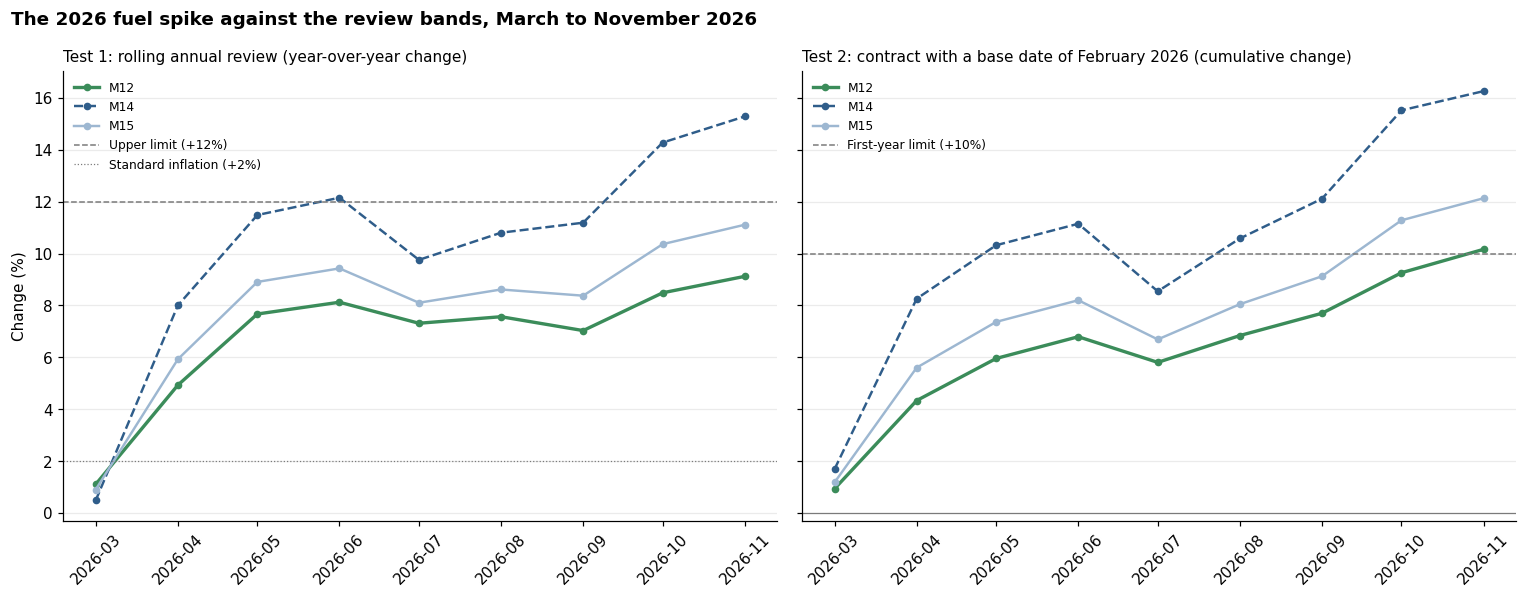

In [43]:
# Test 1 and Test 2 against their upper limits, March to November 2026
months_26 = ext.loc["2026-03-01":"2026-11-01"].index
styles_26 = {"M12": (COLORS["green"], "-", 2.2), "M14": (COLORS["blue"], "--", 1.6), "M15": (COLORS["light_blue"], "-", 1.6)}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for lab, (color, style, width) in styles_26.items():
    axes[0].plot(months_26, ext.loc[months_26, f"{lab} yoy"], label=lab, color=color, linestyle=style, linewidth=width, marker="o", markersize=4)
    axes[1].plot(months_26, (ext.loc[months_26, lab] / base[lab] - 1) * 100, label=lab, color=color, linestyle=style, linewidth=width, marker="o", markersize=4)
axes[0].axhline(UPPER, color=COLORS["grey"], linewidth=1, linestyle="--", label="Upper limit (+12%)")
axes[0].axhline(2.0, color=COLORS["grey"], linewidth=0.8, linestyle=":", label="Standard inflation (+2%)")
axes[1].axhline(10.0, color=COLORS["grey"], linewidth=1, linestyle="--", label="First-year limit (+10%)")
axes[1].axhline(0.0, color=COLORS["grey"], linewidth=0.8)
axes[0].set_title("Test 1: rolling annual review (year-over-year change)", loc="left", fontsize=10)
axes[1].set_title("Test 2: contract with a base date of February 2026 (cumulative change)", loc="left", fontsize=10)
axes[0].set_ylabel("Change (%)")
for ax in axes:
    ax.legend(loc="upper left", frameon=False, fontsize=8)
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("The 2026 fuel spike against the review bands, March to November 2026", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

Both panels show the same path: a sharp rise in April, when the fuel spike enters the indexes, a pause in July, when fuel prices ease for a month, and a new climb from August to November. The order of the indexes never changes: M14 stays highest and M12 lowest, in line with their fuel weights.

The two tests differ in how close the indexes come to triggering. In Test 1, M12 and M15 end November below the +12% limit, while M14 crosses it in June and again from October. Test 2 has a tighter limit (+10%) and measures the full rise since a base set just before the spike, so all three indexes are above it by November.

### **5.5 A real forecast: November 2026**

The lags of the model allow a forecast before the data exist. The CPI of November 2026 depends, in the frozen M12 regression, on the fuel change of October 2026 and the IPPI change of March 2026, both already published. The forecast below is recorded on the snapshot date, before Statistics Canada publishes the November CPI in December 2026, so it can be checked against the actual value later.

In [44]:
# Forecast the November 2026 CPI with the frozen M12 regression, before its publication
ext["cfi_yoy"] = ext["cfi_n"].pct_change(12, fill_method=None) * 100
ext["ippi_yoy"] = ext["ippi_p63_n"].pct_change(12, fill_method=None) * 100
x_nov = pd.DataFrame({"const": [1.0], "cfi_lag1": [ext.loc["2026-10-01", "cfi_yoy"]],
                      "ippi_lag8": [ext.loc["2026-03-01", "ippi_yoy"]]})
nov = m12.get_prediction(x_nov).summary_frame(alpha=0.05).iloc[0]

# Implied CPI level for November 2026, from the published November 2025 value
cpi_nov25 = master.set_index("month").loc["2025-11-01", "cpi_montreal"]
print(f"Inputs: CFI change in October 2026 = {x_nov['cfi_lag1'][0]:.2f}%, IPPI change in March 2026 = {x_nov['ippi_lag8'][0]:.2f}%")
print(f"\nForecast of the CPI of Montréal, November 2026 (year-over-year): {nov['mean']:.2f}%")
print(f"95% prediction interval: {nov['obs_ci_lower']:.2f}% to {nov['obs_ci_upper']:.2f}%")
print(f"\nCPI of Montréal, November 2025 (2002 = 100): {cpi_nov25:.1f}")
print(f"Implied November 2026 level: {cpi_nov25 * (1 + nov['mean'] / 100):.1f} "
      f"(interval {cpi_nov25 * (1 + nov['obs_ci_lower'] / 100):.1f} to {cpi_nov25 * (1 + nov['obs_ci_upper'] / 100):.1f})")
print(f"\nLast published values: October 2026 CPI change {master.set_index('month').loc['2026-10-01', 'cpi_montreal_n_yoy']:.2f}%, "
      f"forecast based on the snapshot of {SNAPSHOT_DATE}")

Inputs: CFI change in October 2026 = 49.59%, IPPI change in March 2026 = 3.21%

Forecast of the CPI of Montréal, November 2026 (year-over-year): 3.39%
95% prediction interval: 1.19% to 5.59%

CPI of Montréal, November 2025 (2002 = 100): 165.5
Implied November 2026 level: 171.1 (interval 167.5 to 174.7)

Last published values: October 2026 CPI change 3.37%, forecast based on the snapshot of 2026-11-17


**Forecast of the CPI of Montréal, November 2026**

| Item | Value |
|------|-------|
| CFI change, October 2026 (lag 1) | +49.59% |
| IPPI change, March 2026 (lag 8) | +3.21% |
| **Forecast, year-over-year change** | **+3.39%** |
| 95% prediction interval | +1.19% to +5.59% |
| CPI of Montréal, November 2025 | 165.5 |
| Implied November 2026 level | 171.1 (167.5 to 174.7) |
| Last published change (October 2026) | +3.37% |

The model expects the CPI of Montréal to grow 3.39% in the year to November 2026, almost the same as the last published change (3.37% in October). Fuel prices rise 49.59% in the year to October, but with a coefficient of 0.0244, that rise adds only about 1.2 points to the forecast. The rest comes from the intercept (1.74 points) and the modest change of the IPPI in March 2026 (0.44 points).

The forecast is recorded before Statistics Canada publishes the November 2026 CPI in December 2026. If the published value falls between 1.19% and 5.59%, the November observation will be consistent with the model's 95% prediction interval, adding one more month to its real-time evaluation. Because the interval is wide, the size of the error against the 3.39% forecast will be the more informative check.

### **Implications for cost control**

- **The model holds up on data it has never seen.** Frozen in March 2026, the M12 regression forecasts the CPI of April to October 2026 with an out-of-sample RMSE of 0.218 points, about half that of a naive benchmark (0.443), and every month falls inside its 95% interval. The test covers only seven calm months for the CPI, so it shows that the model does not break, not how it would perform in a new surge.
- **The index gives an early signal.** Thanks to its lags, the index for November 2026 can be computed before the CPI for that month is published, and the CPI forecast for November (+3.39%) is recorded in advance. A cost control team can use the index to identify changes in construction input costs before the corresponding CPI figures are published, giving them an earlier basis for assessing escalation risk.
- **The 2026 fuel spike is already a contract risk.** By November 2026, the indexes show year-over-year increases ranging from 9.12% to 15.28%, against 3.37% for the latest published CPI change (October). A contract priced in February 2026 is already beyond its +10% first-year limit under all three indexes by November, months before its first review.
- **The fuel weight decides how early an index reacts.** In the rolling review, M14 crosses the band in June, October and November 2026, for a sum of \$5.72M across these three hypothetical monthly reviews, while M12 and M15 stay inside it. More fuel weight gives an earlier response to fuel shocks, at the cost of more volatility in normal times.
- **The next months depend mostly on fuel.** Because the index uses the IPPI of eight months earlier and the IPPI is published up to September 2026, its material component is already known through May 2027, subject to revisions, and it is only slightly above its March level. For index months through May 2027, the unknown part of the indexes is fuel, so diesel is the series to watch at each review.

# **Chapter 6: From market index to project index**

This chapter turns the analysis into a tool a cost control team can use. The three candidates are compared on the evidence of Chapters 3 to 5, and one becomes the Construction Market Index (CMI). A second layer then adapts the CMI to the cost structure of a project, giving a project index (M16) that combines market signals with the costs a contract actually carries.

### **6.1 Choosing the Construction Market Index**

**Evidence on the Three Candidates**

| Criterion | M12 | M14 | M15 | Source |
|-----------|-----|-----|-----|--------|
| Fuel weight | 15.1% | 30.0% | 20.0% | Chapter 3 |
| Basis of the fuel weight | Statistical optimum | Economic adjustment | Upper reference from the regime blends | Chapter 3 |
| R² | 0.6247 | 0.6008 | 0.6215 | Section 3.5.3 |
| Correlation with the CPI | 0.784 | 0.766 | 0.781 | Section 4.2 |
| Tracking gap | 7.33 pts | 8.55 pts | 7.68 pts | Section 4.2 |
| Historical triggers | 17 up | 18 up, 1 down | 17 up | Section 4.4 |
| COVID stress test | Pass | Fails the lower limit by 0.34 pts | Pass | Section 4.4.1 |
| 2026, Test 1 triggers | 0 | 3 (\$5.72M) | 0 | Section 5.4 |
| 2026, Test 2 change by November | +10.16% | +16.26% | +12.13% | Section 5.4 |

**Decision: M12 becomes the Construction Market Index.**

M12 has the best fit, follows the CPI most closely, passes the COVID stress test and rests on no economic assumption. M15 performs almost as well and remains a valid choice when more fuel weight is wanted. M14 reacts earliest to fuel shocks, but it also triggers on the temporary COVID shock, and its 30% depends on a judgment the market data do not support.

A project's own fuel exposure does not need to be built into the market index. The second layer, in section 6.2, adds the fuel and material costs a project actually carries as separate components. This keeps the CMI purely statistical and leaves the project-specific judgment where it can be documented with the project's cost breakdown.

$$\text{CMI}_t = 0.151 \times \text{CFI}_{t-1} + 0.849 \times \text{IPPI}_{t-8}$$

### **6.2 Building the Project Index (M16)**

The CMI measures how the construction market moves. A project, however, does not spend all its budget at market prices with a delay. Part of the cost is fixed at signature (design, mobilization, contracted labour rates), and part is exposed directly to current fuel and material prices. The project index combines these four components:

**M16 Components**

| Component | Weight | Series | Timing |
|-----------|--------|--------|--------|
| Fixed costs | 15% | Constant at 100 | Does not move |
| Fuel | 10% | CFI | Current month |
| Materials | 15% | IPPI P63 | Current month |
| Market index | 60% | CMI | Lags of 1 and 8 months |

$$\text{M16}_t = 0.15 \times 100 + 0.10 \times \text{CFI}_t + 0.15 \times \text{IPPI}_t + 0.60 \times \text{CMI}_t$$

These weights are illustrative. In practice they come from the cost breakdown of the project: the share of the budget that is fixed, the share spent on fuel and the share spent on materials. The rest follows the market through the CMI.

Two rules keep the index consistent. First, every component is on the same scale (January 2018 = 100), including the fixed component, which is set at 100. A fixed value on a different scale would pull the index down and distort both its level and its changes. Second, the current IPPI is published with a delay, so M16 is available up to September 2026, while the CMI, built on lagged values, reaches November 2026.

In [45]:
# Second layer: project index M16 from a fixed component, current fuel, current materials and the CMI
M16_WEIGHTS = {"fixed": 0.15, "fuel": 0.10, "materials": 0.15, "cmi": 0.60}
FIXED_LEVEL = 100.0
assert abs(sum(M16_WEIGHTS.values()) - 1) < 1e-9

ext["CMI"] = ext["M12"]
ext["M16"] = (M16_WEIGHTS["fixed"] * FIXED_LEVEL
              + M16_WEIGHTS["fuel"] * ext["cfi_n"]
              + M16_WEIGHTS["materials"] * ext["ippi_p63_n"]
              + M16_WEIGHTS["cmi"] * ext["CMI"])
ext["M16 yoy"] = ext["M16"].pct_change(12, fill_method=None) * 100
ext["CMI yoy"] = ext["CMI"].pct_change(12, fill_method=None) * 100

last_m16 = ext["M16"].last_valid_index()
print(f"Data range: {ext.index.min():%b %Y} to {ext.index.max():%b %Y}")
print(f"M16 available to: {last_m16:%b %Y}")
print(f"CMI available to: {ext['CMI'].last_valid_index():%b %Y}\n")

# Contribution of each component at key dates (index points)
dates = pd.to_datetime(["2018-01-01", "2026-02-01", last_m16])
contrib = pd.DataFrame({
    "Fixed": M16_WEIGHTS["fixed"] * FIXED_LEVEL,
    "Fuel": M16_WEIGHTS["fuel"] * ext.loc[dates, "cfi_n"],
    "Materials": M16_WEIGHTS["materials"] * ext.loc[dates, "ippi_p63_n"],
    "Market (CMI)": M16_WEIGHTS["cmi"] * ext.loc[dates, "CMI"],
})
contrib["M16"] = ext.loc[dates, "M16"]
contrib["CMI"] = ext.loc[dates, "CMI"]
contrib["M16 YoY %"] = ext.loc[dates, "M16 yoy"]
contrib["CMI YoY %"] = ext.loc[dates, "CMI yoy"]
contrib.index = contrib.index.strftime("%b %Y")
print("M16 Components at Key Dates")
display(contrib.round(2))

Data range: Jan 2010 to Nov 2026
M16 available to: Sep 2026
CMI available to: Nov 2026

M16 Components at Key Dates


,Fixed,Fuel,Materials,Market (CMI),M16,CMI,M16 YoY %,CMI YoY %
Jan 2018,15.0,10.00,15.00,58.90,98.90,98.17,4.85,5.62
Feb 2026,15.0,13.41,23.70,89.43,141.54,149.04,0.76,0.86
Sep 2026,15.0,19.02,24.33,96.31,154.66,160.52,9.37,7.03


**Reading the Components**

- **The level of M16 sits below the CMI.** The fixed component holds 15% of the index at 100 while the market moves above it. By February 2026 the CMI stands at 149.04 and M16 at 141.54. The gap is expected: the fixed share of a project does not escalate.
- **January 2018 is close to, but not exactly, 100.** The CMI is built on lagged values (December 2017 for fuel, May 2017 for materials), so it starts at 98.17, and M16 at 98.90.
- **Current fuel drives a large share of the 2026 movement.** Between February and September 2026, M16 rises 13.12 points (+9.27%). Fuel contributes 5.61 points, materials 0.63 and the market index 6.88. With only 10% of the weight, current fuel explains about 43% of the change.
- **M16 reacts faster than the CMI.** In September 2026, M16 is up 9.37% year over year against 7.03% for the CMI. The current fuel component brings in the March 2026 diesel shock without the one-month lag, and its effect adds to what the CMI already carries.

The second layer does what the market index alone cannot: it gives fuel the weight it has in the project budget at the moment the cost is paid, while the CMI keeps the general market trend. The next section tests how M16 behaves in the history and in the 2026 review.

### **6.3 M16 in the History and in the 2026 Review**

M16 is tested with the same rules applied to the candidates in Chapters 4 and 5, with the CMI as the reference:

- **Historical triggers:** year-over-year change against the review band (+12% / -8%) on a reference contract of \$100M, from September 2011 to March 2026.
- **COVID stress test:** the lowest year-over-year change in 2020 against the lower limit of -8%.
- **2026, Test 1:** rolling annual review, year-over-year change against the same band.
- **2026, Test 2:** contract with a base date of February 2026, cumulative change against a ±10% band in the first year.

M16 is available up to September 2026 and the CMI up to November 2026.

In [46]:
# M16 against the CMI: historical triggers, COVID stress test and the 2026 tests
def band_excess(yoy, upper=UPPER, lower=LOWER):
    # Excess above the upper limit or below the lower limit, zero inside the band
    return pd.Series(np.where(yoy > upper, yoy - upper,
                              np.where(yoy < lower, yoy - lower, 0.0)), index=yoy.index)

hist = ext.loc["2011-09-01":"2026-03-01"]
summary = {}
for name in ["CMI", "M16"]:
    yoy = hist[f"{name} yoy"]
    exc = band_excess(yoy)
    adj = exc / 100 * CONTRACT_VALUE
    trig = exc[exc != 0]
    summary[name] = {
        "Months up": int((exc > 0).sum()),
        "Months down": int((exc < 0).sum()),
        "First trigger": f"{trig.index.min():%b %Y}" if len(trig) else "-",
        "Last trigger": f"{trig.index.max():%b %Y}" if len(trig) else "-",
        "Sum of monthly adjustments ($M)": round(adj.sum() / 1e6, 2),
        "Lowest YoY 2020 (%)": round(yoy.loc["2020"].min(), 2),
        "Lowest month": f"{yoy.loc['2020'].idxmin():%b %Y}",
    }
print("Historical Triggers and COVID Stress Test, Sep 2011 to Mar 2026")
display(pd.DataFrame(summary))

# 2026: Test 1 (rolling YoY against +12% / -8%) and Test 2 (change since Feb 2026 against ±10%)
y26 = ext.loc["2026-03-01":"2026-11-01"]
base26 = ext.loc["2026-02-01", ["CMI", "M16"]]
t26 = pd.DataFrame({
    "CMI YoY %": y26["CMI yoy"],
    "M16 YoY %": y26["M16 yoy"],
    "CMI since Feb 2026 %": (y26["CMI"] / base26["CMI"] - 1) * 100,
    "M16 since Feb 2026 %": (y26["M16"] / base26["M16"] - 1) * 100,
})
t26.index = t26.index.strftime("%b %Y")
print("\n2026 Review: Test 1 and Test 2")
display(t26.round(2))

for name in ["CMI", "M16"]:
    exc26 = band_excess(y26[f"{name} yoy"].dropna())
    chg = (y26[name].dropna() / base26[name] - 1) * 100
    over = chg[chg.abs() > 10]
    print(f"{name}: Test 1 triggers {int((exc26 != 0).sum())}, "
          f"adjustment ${exc26.sum() / 100 * CONTRACT_VALUE / 1e6:,.2f}M | "
          f"Test 2 first month outside ±10%: {over.index.min():%b %Y}" if len(over)
          else f"{name}: Test 1 triggers {int((exc26 != 0).sum())}, "
               f"adjustment ${exc26.sum() / 100 * CONTRACT_VALUE / 1e6:,.2f}M | "
               f"Test 2 within ±10% to {chg.index.max():%b %Y}")

Historical Triggers and COVID Stress Test, Sep 2011 to Mar 2026


,CMI,M16
Months up,17,17
Months down,0,0
First trigger,Nov 2021,Oct 2021
Last trigger,Mar 2023,Feb 2023
Sum of monthly adjustments ($M),251.76,189.15
Lowest YoY 2020 (%),-4.22,-5.37
Lowest month,May 2020,May 2020



2026 Review: Test 1 and Test 2


,CMI YoY %,M16 YoY %,CMI since Feb 2026 %,M16 since Feb 2026 %
Mar 2026,1.11,3.51,0.94,2.92
Apr 2026,4.93,6.65,4.34,5.51
May 2026,7.67,8.65,5.96,6.60
Jun 2026,8.13,8.12,6.80,6.20
Jul 2026,7.32,8.15,5.81,6.32
Aug 2026,7.57,9.04,6.84,7.72
Sep 2026,7.03,9.37,7.70,9.27
Oct 2026,8.49,NaN,9.26,NaN
Nov 2026,9.12,NaN,10.16,NaN


CMI: Test 1 triggers 0, adjustment $0.00M | Test 2 first month outside ±10%: Nov 2026
M16: Test 1 triggers 0, adjustment $0.00M | Test 2 within ±10% to Sep 2026


**Key Observations**

- **Same number of triggers, one month earlier.** M16 crosses the upper limit in 17 months, like the CMI, but from October 2021 to February 2023 instead of November 2021 to March 2023. The current fuel and materials components react without the CMI's lags.
- **A lower sum of monthly adjustments in the history.** The sum of monthly adjustments falls from \$251.76M to \$189.15M (-25%). The lower sum reflects M16's project-specific structure: the fixed component does not escalate, while fuel and materials enter at their current values and project-specific weights. The result is valid only if those weights match the project's real cost breakdown.
- **The COVID stress test still passes.** M16 drops further than the CMI in 2020 (-5.37% against -4.22%, both in May 2020), because current fuel prices collapse without a delay. The trough stays 2.63 points above the -8% lower limit.
- **2026, Test 1: no trigger.** M16 picks up the March 2026 diesel shock right away (+3.51% in March against +1.11% for the CMI) and peaks at +9.37% in September, below the +12% upper limit.
- **2026, Test 2:** M16 reaches +9.27% in September, 0.73 points from the +10% limit, while the CMI is at +7.70% the same month and crosses the limit in November (+10.16%). With M16 closer to the limit two months earlier, the October and November values will decide whether a project with this cost structure needs an adjustment in the first year.

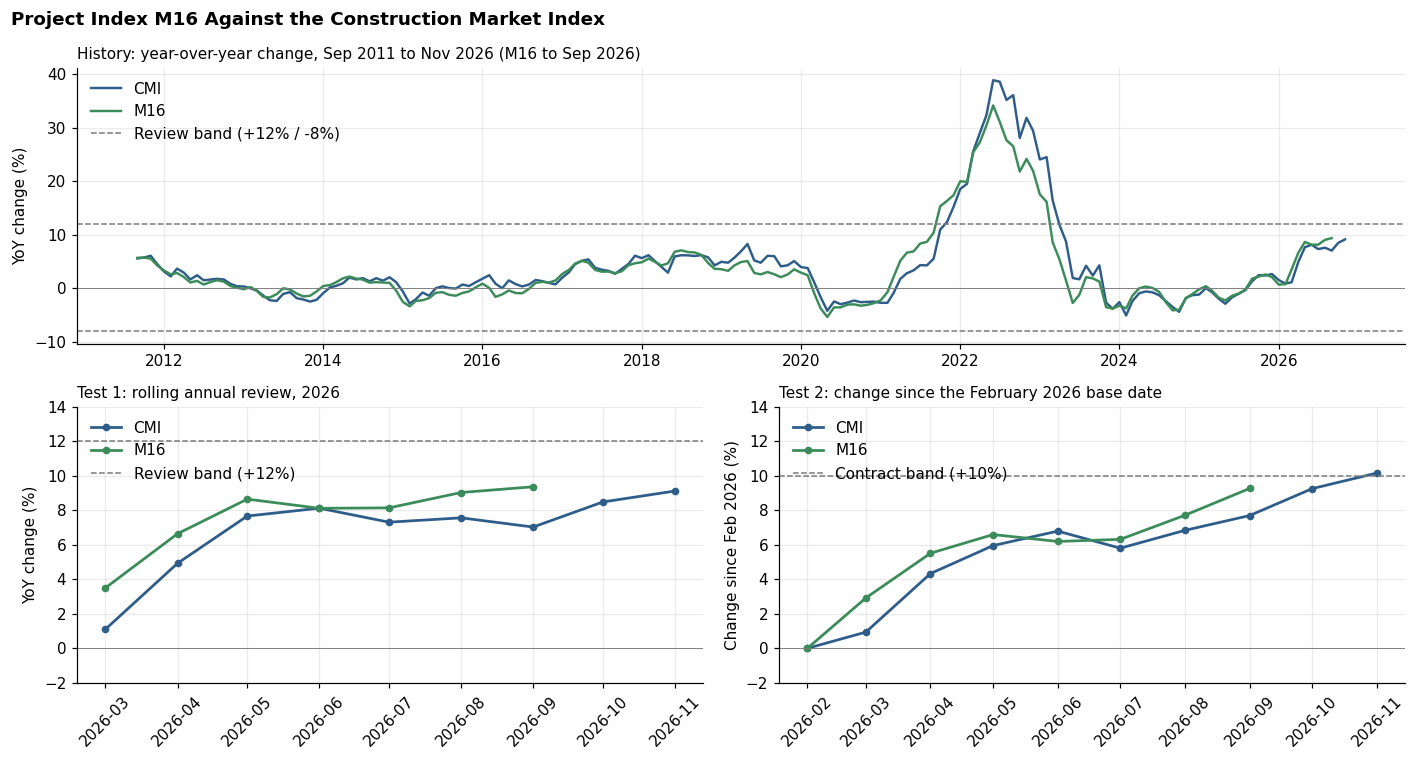

In [47]:
# Chart: M16 against the CMI in the history and in the two 2026 tests
fig = plt.figure(figsize=(13, 7))
gs = fig.add_gridspec(2, 2)

# Panel 1: historical year-over-year change against the review band
ax = fig.add_subplot(gs[0, :])
h = ext.loc["2011-09-01":"2026-11-01"]
ax.plot(h.index, h["CMI yoy"], color=COLORS["blue"], lw=1.6, label="CMI")
ax.plot(h.index, h["M16 yoy"], color=COLORS["green"], lw=1.6, label="M16")
ax.axhline(UPPER, color=COLORS["grey"], ls="--", lw=1, label="Review band (+12% / -8%)")
ax.axhline(LOWER, color=COLORS["grey"], ls="--", lw=1)
ax.axhline(0, color=COLORS["grey"], lw=0.6)
ax.set_title("History: year-over-year change, Sep 2011 to Nov 2026 (M16 to Sep 2026)", loc="left", fontsize=10)
ax.set_ylabel("YoY change (%)")
ax.legend(loc="upper left", frameon=False)

# Panel 2: Test 1, rolling annual review in 2026 against +12% / -8%
ax = fig.add_subplot(gs[1, 0])
p = ext.loc["2026-03-01":"2026-11-01"]
for name, color in [("CMI", COLORS["blue"]), ("M16", COLORS["green"])]:
    ax.plot(p.index, p[f"{name} yoy"], color=color, lw=1.8, marker="o", ms=4, label=name)
ax.axhline(UPPER, color=COLORS["grey"], ls="--", lw=1, label="Review band (+12%)")
ax.axhline(0, color=COLORS["grey"], lw=0.6)
ax.set_ylim(-2, 14)
ax.set_title("Test 1: rolling annual review, 2026", loc="left", fontsize=10)
ax.set_ylabel("YoY change (%)")
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="upper left", frameon=False)

# Panel 3: Test 2, change since the February 2026 base date against ±10%
ax = fig.add_subplot(gs[1, 1])
p = ext.loc["2026-02-01":"2026-11-01"]
for name, color in [("CMI", COLORS["blue"]), ("M16", COLORS["green"])]:
    chg = (p[name] / p.loc["2026-02-01", name] - 1) * 100
    ax.plot(chg.index, chg, color=color, lw=1.8, marker="o", ms=4, label=name)
ax.axhline(10, color=COLORS["grey"], ls="--", lw=1, label="Contract band (+10%)")
ax.axhline(0, color=COLORS["grey"], lw=0.6)
ax.set_ylim(-2, 14)
ax.set_title("Test 2: change since the February 2026 base date", loc="left", fontsize=10)
ax.set_ylabel("Change since Feb 2026 (%)")
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="upper left", frameon=False)

fig.suptitle("Project Index M16 Against the Construction Market Index",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

**Reading the Chart**

The top panel shows that M16 follows the same broad cycle as the CMI, but responds earlier to changes in fuel and materials because those components enter at current prices rather than with the CMI's lags. Its peaks are also lower in some of the broad market episodes, partly because 15% of the index does not escalate. In 2020 it dips further than the CMI, driven by the collapse in current fuel prices, but stays above the -8% lower limit.

The bottom left panel shows Test 1. M16 reacts to the March 2026 diesel shock right away (+3.51% against +1.11% for the CMI) and stays above the CMI for most of the year, peaking at +9.37% in September. Neither index reaches the +12% upper limit, so the rolling review triggers no adjustment.

The bottom right panel shows Test 2. M16 runs above the CMI in every month except June and ends at +9.27% in September, just under the +10% limit, while the CMI crosses the limit in November (+10.16%).

In both tests the M16 line stops in September because the current IPPI for October is not yet published. It will be completed as Statistics Canada releases new data.

### **Implications for cost control**

- **Two indexes, two roles.** The CMI is the market reference: it is statistical, it is the same for every project and it can be compared across contracts. M16 measures the exposure of one project. Keeping them separate means the market evidence and the project judgment can each be reviewed on their own.
- **The weights of M16 come from the project, not from the data.** The fixed, fuel and materials shares should come from the project's cost breakdown, be documented at contract signature and be updated if the cost structure changes significantly.
- **Every component must be on the same scale.** The fixed component is set at 100, like the other series at the base date. A fixed value on a different scale distorts the level of the index and every adjustment calculated from it.
- **M16 gives an earlier signal and an adjustment closer to the project's cost.** It triggers in 17 months, like the CMI, but from October 2021 to February 2023 instead of November 2021 to March 2023, so the protection is kept. In the history, its sum of monthly adjustments is 25% lower (\$189.15M against \$251.76M). The lower sum reflects M16's project-specific structure: the fixed component does not escalate, while fuel and materials enter at their current values and project-specific weights. It is not lower by design: in 2026, when fuel rises sharply, M16 runs mostly above the CMI in both tests. Its accuracy depends on the accuracy of the cost breakdown.
- **Publication delays set the review calendar.** M16 depends on the current IPPI, so each monthly value is confirmed one to two months later. Reviews should use the latest published month and state the date of the data used.
- **2026 needs close monitoring.** In September M16 stands at +9.27% since February, 0.73 points from the +10% contract limit. Its October and November values can be calculated only once Statistics Canada publishes the current IPPI for those months; they will show whether a project with this cost structure requires a first-year adjustment.

# **Chapter 7: Conclusions and recommendations**

This chapter brings together what the analysis shows, what a cost control team should do with it, where the method reaches its limits and how the results can be reproduced.

### **7.1 Conclusions**

- **Public data are enough to build a leading cost index.** Fuel prices and the IPPI for construction materials lead the Montréal CPI. The relationship is strongest with a one-month lag for fuel (correlation 0.634) and an eight-month lag for materials (0.765, against 0.516 with no lag).
- **The Construction Market Index (CMI) combines both signals.** With weights of 15.1% fuel and 84.9% materials, it explains 62.5% of the variation in the CPI (R² 0.6247). In-sample, its fitted values match the direction of month-to-month changes in annual CPI inflation 59.8% of the time, so the model tracks the level of annual CPI inflation better than its month-to-month direction.
- **The model holds on new data.** On the seven months after March 2026, which were not used to fit it, the error is half that of a naive benchmark (RMSE 0.218 against 0.443), and every actual value falls inside the 95% prediction interval.
- **The index reacts when it should.** In the history, it triggers adjustments only during the post-COVID surge (17 months, November 2021 to March 2023) and stays inside the review band during the 2020 shock.
- **2026 shows rising pressure, close to the contract limit.** The rolling annual review triggers no adjustment, but a contract with a February 2026 base date crosses the +10% first-year limit in November (+10.16%).
- **A second layer adapts the market index to a project.** M16 adapts the market index to a project's cost structure. It records the same number of historical triggers as the CMI, starting one month earlier, and uses project-specific weights for the fixed, fuel and materials components.

### **7.2 Recommendations**

- **Use the CMI as the market reference and M16 as the project index.** The CMI provides a common reference based on the movement of fuel and construction material prices and can be shared across contracts. M16 should be the basis for adjustments on a specific project.
- **Set the M16 weights from the project's cost breakdown.** The fixed, fuel and materials shares in this notebook are illustrative. On a real project they should come from the estimate, be documented at contract signature and be reviewed if the cost structure changes significantly.
- **Test how sensitive M16 is to its weights.** Before signing, recalculate the index with the fixed share a few points higher and lower. If a small change in the breakdown moves the adjustments a lot, the breakdown needs more support.
- **Update the indexes on a fixed monthly calendar.** Refresh the data after each Statistics Canada release, use the latest published month and record the date of the data used. Values used in a past review should be kept as they were, even if Statistics Canada later revises them.
- **Re-estimate the CMI once a year or after a regime change.** The weights and lags come from 2011 to 2026. A rolling correlation that weakens, or a new shock like 2020 or 2022, is a signal to evaluate whether the model needs to be refitted.
- **Consider a lagged materials layer if timing matters more than precision.** Using the IPPI with a one- or two-month lag in M16 would make the index available up to the latest month, at the cost of no longer reflecting current material prices.
- **Monitor the 2026 contract test closely.** M16 is 0.73 points from the +10% limit in September and the CMI crosses it in November. The next releases should be reviewed as soon as they are published.
- **Extend the index with other cost drivers when data allow.** Labour, equipment rental and regional material prices are not in the model. Adding them to the second layer would bring M16 closer to the full cost of a project.

### **7.3 Limitations**

- **The CMI is calibrated to the CPI, not to construction costs.** Its weights measure how well fuel and materials anticipate consumer inflation in Montréal, not how much each one weighs in a project budget. This is why the second layer is needed, and why the CMI alone should not be read as a cost structure.
- **The weights depend on how they are derived.** The 15.1% / 84.9% split comes from the ratio of the regression coefficients. A standardized reading, which also accounts for the variability of each input, gives 29.9% / 70.1%, because fuel is far more volatile than materials. The two readings answer different questions: the first is the weight used in the index, the second describes the relative contribution of each input to the fitted CPI.
- **M16 is only as accurate as the cost breakdown.** An overstated fixed share under-compensates the contractor, and an understated one over-compensates. The weights used here are illustrative.
- **The relationships depend on the regime.** Correlations and weights change between the Pre-COVID period, the 2020 shock, the post-COVID surge and Stabilization. A model fitted on 2011 to 2026 may not hold in a different economic context.
- **Some regimes have very few months.** The COVID shock covers 10 months and the out-of-sample test 7. Results on these periods are indicative, not conclusive.
- **Year-over-year changes overlap.** Consecutive YoY values share 11 of their 12 months, so the residuals are likely autocorrelated. The coefficient estimates still describe the fitted relationship, but conventional standard errors and p-values, such as those in section 3.3, may overstate the statistical precision.
- **The series differ in geography.** The CPI and fuel prices are for Montréal, while the IPPI for construction materials is national. Regional differences in material prices are not captured.
- **Published data change and arrive late.** Statistics Canada revises recent values (the IPPI for March 2026 moved from 147.0 to 147.8), and the current IPPI is published with a delay, which limits M16 to September 2026 in this snapshot.

### **7.4 Reproducibility notes**

**Data Sources**

| Series | Statistics Canada table | Geography | Unit or base |
|--------|-------------------------|-----------|--------------|
| Diesel and regular unleaded gasoline, self service | 18-10-0001-01 | Montréal | ¢/L |
| IPPI, Fabricated metal products and construction materials [P63] | 18-10-0266-01 | Canada | 2020 = 100 |
| CPI, All-items | 18-10-0004-01 | Montréal and Canada | 2002 = 100 |

**Analysis Settings**

| Setting | Value |
|---------|-------|
| Master dataset | January 2010 to October 2026 (202 months) |
| Analysis period | January 2010 to March 2026 (195 months) |
| Year-over-year series and correlations | January 2011 to March 2026 (183 months) |
| Model estimation | September 2011 to March 2026 (175 months) |
| Out-of-sample period | April 2026 to the latest published month |
| Normalization base | January 2018 = 100 |
| Data snapshot | 17 November 2026 |

**Saved Files**

- `data/raw/statcan_series_2026-11-17.csv.gz`: the raw series as downloaded (3,457 rows).
- `data/processed/master_dataset_2026-11-17.parquet`: the monthly master dataset, including out-of-sample observations (202 months × 12 columns).

**Rerunning the Notebook**

1. Download the three tables as full CSV zip files from Statistics Canada and place them in `data/raw/`.
2. Set `SNAPSHOT_DATE` to the download date. The model estimation period remains fixed through March 2026; new months extend the out-of-sample test and the 2026 review.
3. New downloads may include revised values that change some results. The saved files keep the exact values used in this notebook, so any difference can be traced to a revision.

All calculations are deterministic: no random sampling is used, so the same data always give the same results.

**External References**

Used in the Data Integrity Note (section 0.5) to check the March 2026 diesel spike against sources independent of Statistics Canada:

- Kalibrate, *March 2026: Kalibrate's Canadian Petroleum Price Snapshot*, April 7, 2026. https://kalibrate.com/?p=19581
- Kalibrate, *Petroleum pricing in Canada: the Q1 2026 report*, April 29, 2026. https://kalibrate.com/?p=19811
- The Canadian Press, *Now at historic highs, diesel prices poised to hit consumers even harder* (citing Natural Resources Canada), September 29, 2026. https://www.ctvnews.ca/business/inflation/article/now-at-historic-highs-diesel-prices-poised-to-hit-consumers-even-harder/

In [48]:
# Environment used to run this notebook
import sys
import matplotlib
import statsmodels

print(f"Python      {sys.version.split()[0]}")
print(f"pandas      {pd.__version__}")
print(f"numpy       {np.__version__}")
print(f"statsmodels {statsmodels.__version__}")
print(f"matplotlib  {matplotlib.__version__}")
print(f"Data snapshot: {SNAPSHOT_DATE}")

Python      3.13.18
pandas      2.2.3
numpy       2.4.6
statsmodels 0.15.0
matplotlib  3.10.0
Data snapshot: 2026-11-17


These are the versions used to produce every result in this notebook. Newer versions should give the same results, with possible differences in chart rendering or in the last decimals.